# Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions
Team Toxic (23): Arjun Srikanth, Ankit Umadi, Jayanth K.

**Research question:** With limited target fitting labels, do local models, pooled cross-city models, fine-tuning, or meta-learning yield better daily AQI forecasts? We compare each against persistence and retain negative findings.

This is a retrospective station-level study using original CPCB exports, not a city-average exposure model. The original 24–72-hour aim is implemented as nominal 1–3-day forecasts of the reported 4 PM daily AQI. Exact publication latency is unverified. Earlier seven-station pilot tests were inspected; these six target cities were chosen before this run's errors, but this is not a public preregistration.


Execution note: after Kaggle queued the main run, the user authorized local computation. The frozen study below executed on the Mac CPU; notebook01 and the GPU environment check executed on Kaggle. Paths adapt to either environment. No target scores chose this backend or the model settings.


## Data and evidence
The immutable source release has 3,820 workbooks, including empty exports. Every file is checked against its SHA256 and parsed according to its day/month layout. Summary rows are not measurements. Unmatched station IDs remain in the extraction and audit; their unresolved geography prevents their use in the city-transfer experiment. Four source values above 500 remain visible and unchanged; they are in 2017, outside this study's modeling years. No missing inputs or test truths are imputed.

The source covers a captured current roster and 2017–2025, not every historical Indian station. Calendar coverage is reporting availability, not verified monitor uptime. Original export routes and listing evidence are packaged with the dataset; this notebook consumes those files and does not claim to collect them from CPCB inside Kaggle.


In [1]:
from pathlib import Path
import os,sys,json,hashlib,time,platform
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
if Path('/kaggle/input').is_dir():
    roots=[p.parent for p in Path('/kaggle/input').rglob('DATASET_CARD.md') if p.parent.name=='CPCB_AQI_Source_Release_v1']
    assert len(roots)==1, f'Attach the v1 release; found {roots}'
    SOURCE=roots[0]
    OUT=Path('/kaggle/working/afml_final')
else:
    SOURCE=Path(os.environ['AFML_SOURCE'])
    OUT=Path(os.environ['AFML_OUTPUT'])
OUT.mkdir(parents=True,exist_ok=True)
print('Source:',SOURCE,'Python:',platform.python_version(),'Backend:',platform.system())


Source: /Users/arjun/Downloads/AFML_course_project/delivery/dataset_release_20261114/CPCB_AQI_Source_Release_v1 Python: 3.12.15 Backend: Darwin


## Reproducible extraction and availability checks
Functions below verify original files before building calendar-safe examples.

In [2]:
"""Immutable CPCB extraction, descriptive EDA and frozen study construction."""
from pathlib import Path
import calendar, hashlib, importlib.util, json, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

TARGETS = ['Amaravati', 'Guwahati', 'Ahmedabad', 'Pithampur', 'Ludhiana', 'Udaipur']
DEV_CITIES = ['Chandigarh', 'Dewas', 'Jalandhar', 'Ajmer']

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def write_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, default=str))

def prepare(root, outdir):
    root, out = Path(root), Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    started = time.time()
    register = pd.read_csv(root/'file_register.csv', dtype={'station_id':str})
    meta = pd.read_csv(root/'station_metadata.csv', dtype={'site_id':str})
    assert len(register)==3820 and len(meta)==626
    assert not meta.site_id.duplicated().any()
    spec = importlib.util.spec_from_file_location('release_parser', root/'scripts/build_paper_source_coverage.py')
    parser = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(parser)
    rows, integrity = [], []
    for r in register.itertuples(index=False):
        path = root/'aqi_files'/r.filename
        assert path.stat().st_size==int(r.bytes), path
        digest = sha256(path)
        assert digest == r.sha256, path
        readings, layout, nrows, ncols = parser.parse_workbook(path, int(r.year))
        rows.extend((str(r.station_id), d, v) for d,v in readings.items())
        integrity.append({'filename':r.filename,'sha256':digest,'observations':len(readings),
                          'layout':f'{layout}_{nrows}x{ncols}',
                          'above_500':sum(v>500 for v in readings.values()),'below_zero':sum(v<0 for v in readings.values())})
    raw = pd.DataFrame(rows,columns=['station_id','date','aqi'])
    raw['date']=pd.to_datetime(raw.date)
    assert len(raw)==769129 and not raw.duplicated(['station_id','date']).any()
    assert np.isfinite(raw.aqi).all()
    raw=raw.sort_values(['station_id','date']).reset_index(drop=True)
    raw=raw.merge(meta.rename(columns={'site_id':'station_id'}),on='station_id',how='left',validate='many_to_one')
    pd.DataFrame(integrity).to_csv(out/'raw_integrity.csv',index=False)
    raw[['station_id','date','aqi','station_name','city','city_code','state']].to_csv(out/'observations.csv.gz',index=False)
    raw.loc[(raw.aqi>500)|(raw.aqi<0),['station_id','date','aqi','city']].to_csv(out/'range_flags.csv',index=False)
    raw.loc[raw.city.isna()].groupby('station_id').size().rename('observations').to_csv(out/'unmatched_ids.csv')
    matched=raw[raw.city.notna()].copy()
    matched['year']=matched.date.dt.year
    idx=pd.MultiIndex.from_product([meta.site_id.astype(str),range(2017,2026)],names=['station_id','year'])
    cov=matched.groupby(['station_id','year']).size().reindex(idx,fill_value=0).rename('observed').reset_index()
    cov['calendar_days']=cov.year.map(lambda y:366 if calendar.isleap(int(y)) else 365)
    cov['fraction']=cov.observed/cov.calendar_days
    cov=cov.merge(meta[['site_id','city','city_code','state','station_name']].rename(columns={'site_id':'station_id'}),on='station_id',validate='many_to_one')
    cov.to_csv(out/'station_year_coverage.csv',index=False)
    grid=cov.pivot(index='station_id',columns='year',values='fraction').reindex(columns=range(2020,2026))
    eligible_ids=grid.index[(grid>=.8).all(axis=1)]
    eligible=meta[meta.site_id.astype(str).isin(eligible_ids)].copy()
    rank=cov[cov.year.between(2020,2023)].groupby('station_id')['observed'].sum()
    eligible['training_observed_days']=eligible.site_id.map(rank)
    eligible['numeric_id']=eligible.site_id.astype(int)
    chosen=eligible.sort_values(['training_observed_days','numeric_id'],ascending=[False,True]).drop_duplicates('city_code')
    chosen=chosen.sort_values(['state','city']).drop(columns='numeric_id').reset_index(drop=True)
    assert len(chosen)==30 and set(TARGETS).issubset(chosen.city)
    chosen['role']=np.where(chosen.city.isin(TARGETS),'target',np.where(chosen.city.isin(DEV_CITIES),'donor_development','donor'))
    # Official city codes can subdivide one urban area (e.g. Ahmedabad/Vatva).
    # A declared25km station buffer removes adjacent aliases from source tasks.
    coords=np.radians(chosen[['latitude','longitude']].astype(float).to_numpy())
    target_geo=meta.loc[meta.city.isin(TARGETS),['latitude','longitude']].apply(pd.to_numeric,errors='coerce').dropna()
    tcoords=np.radians(target_geo.to_numpy())
    dist=[]
    for p in coords:
        a=np.sin((tcoords[:,0]-p[0])/2)**2+np.cos(p[0])*np.cos(tcoords[:,0])*np.sin((tcoords[:,1]-p[1])/2)**2
        dist.append(float((2*6371*np.arcsin(np.sqrt(np.clip(a,0,1)))).min()))
    chosen['nearest_target_station_km']=dist
    chosen.loc[(chosen.role!='target')&(chosen.nearest_target_station_km<25),'role']='excluded_source_buffer'
    donor_city_names=chosen.loc[chosen.role.isin(['donor','donor_development']),'city'].tolist()
    assert set(DEV_CITIES).issubset(donor_city_names)
    chosen.to_csv(out/'cohort.csv',index=False)
    eligible.drop(columns='numeric_id').to_csv(out/'eligible_stations.csv',index=False)
    selected=raw[raw.station_id.isin(chosen.site_id)].copy()
    win=[]
    for sid,group in selected.groupby('station_id',sort=True):
        group=group.set_index('date').sort_index()
        city=group.city.iloc[0]
        vals=group.aqi.to_dict()
        common=[]
        for d,y in vals.items():
            if not pd.Timestamp('2020-01-04')<=d<=pd.Timestamp('2025-12-31'):continue
            candidates=[]
            for h in (1,2,3):
                issue=d-pd.Timedelta(days=h)
                dates=pd.date_range(issue-pd.Timedelta(days=6),issue)
                if not all(t in vals for t in dates):break
                v=[vals[t] for t in dates]
                candidates.append({'station_id':sid,'city':city,'date':d,'issue_date':issue,'horizon':h,
                    'feature_date_min':dates[0],'feature_date_max':dates[-1],'y':float(y),'last':float(v[-1]),
                    **{f'x{i}':float(a) for i,a in enumerate(v)},'issue_doy':issue.dayofyear,'issue_dow':issue.dayofweek})
            if len(candidates)==3:common.extend(candidates)
        win.extend(common)
    windows=pd.DataFrame(win).sort_values(['city','date','horizon']).reset_index(drop=True)
    assert not windows.duplicated(['city','date','horizon']).any()
    assert (windows.feature_date_max==windows.issue_date).all()
    assert ((windows.date-windows.issue_date).dt.days==windows.horizon).all()
    assert (windows.feature_date_min==windows.issue_date-pd.Timedelta(days=6)).all()
    windows.to_csv(out/'forecast_examples.csv.gz',index=False)
    donors=windows[windows.city.isin(donor_city_names)]
    donor_train=donors[(donors.date<='2022-12-31')&(donors.issue_date>='2020-01-01')].copy()
    donor_val=donors[(donors.date.between('2023-01-04','2023-12-31'))&(donors.issue_date>='2023-01-01')].copy()
    donor_full=donors[(donors.date<='2023-12-31')&(donors.issue_date>='2020-01-01')].copy()
    targets={}
    counts=[]
    for city in TARGETS:
        d=windows[windows.city==city]
        adapt=d[d.date<='2023-12-31'].copy()
        secondary=d[d.date.between('2024-01-04','2024-12-31')&(d.issue_date>='2024-01-01')].copy()
        test=d[d.date.between('2025-01-01','2025-12-31')&(d.issue_date>='2024-01-01')].copy()
        assert adapt.date.nunique()>=180 and len(secondary)>0 and len(test)>0
        targets[city]={'adapt':adapt,'validation':secondary,'test':test}
        for period,frame in [('adapt',adapt),('secondary_2024',secondary),('test_2025',test)]:
            counts.append({'city':city,'station_id':str(frame.station_id.iloc[0]),'period':period,
                           'unique_label_dates':frame.date.nunique(),'examples':len(frame),
                           'first_label':frame.date.min(),'last_label':frame.date.max(),
                           'eligible_fraction_of_calendar':frame.date.nunique()/(366 if period=='secondary_2024' else 365) if period!='adapt' else None})
    pd.DataFrame(counts).to_csv(out/'eligibility.csv',index=False)
    # Descriptive EDA: value inspection confined to development years before model evaluation.
    dev=raw[raw.date.dt.year.between(2020,2023)].copy()
    dev['year']=dev.date.dt.year
    dev['month']=dev.date.dt.month
    dev.aqi.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_csv(out/'development_distribution.csv')
    dev.groupby('year').agg(observations=('aqi','size'),stations=('station_id','nunique'),mean=('aqi','mean'),median=('aqi','median')).to_csv(out/'development_by_year.csv')
    dev[dev.city.notna()].groupby(['city','month']).aqi.agg(['mean','median','count']).to_csv(out/'development_seasonality.csv')
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    axs[0].hist(dev.aqi,bins=60,color='#2b7b9f');axs[0].set(title='Observed AQI, 2020–2023',xlabel='AQI',ylabel='Station-days')
    coverage_image=cov.pivot(index='station_id',columns='year',values='fraction').sort_values(list(range(2017,2026)),ascending=False)
    im=axs[1].imshow(coverage_image.values,aspect='auto',vmin=0,vmax=1,cmap='viridis')
    axs[1].set(title='Calendar observation coverage: current roster',xlabel='Year',ylabel='Station (sorted)')
    axs[1].set_xticks(range(9),range(2017,2026),rotation=45);fig.colorbar(im,ax=axs[1],label='Fraction observed')
    fig.tight_layout();fig.savefig(out/'eda_source.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,5))
    for city in TARGETS:
        s=dev[dev.city==city].groupby('month').aqi.mean()
        ax.plot(s.index,s.values,marker='o',label=city)
    ax.set(title='Development-period target-city seasonality (observed stations)',xlabel='Month',ylabel='Mean AQI');ax.legend(ncol=3)
    fig.tight_layout();fig.savefig(out/'eda_seasonality.png',dpi=160);plt.close(fig)
    autoc=[]
    for sid,g in selected.groupby('station_id'):
        s=g[g.date.dt.year.between(2020,2023)].set_index('date').aqi.asfreq('D')
        autoc.append({'station_id':sid,'city':g.city.iloc[0],**{f'lag_{l}':s.corr(s.shift(l)) for l in [1,2,3,7,14]}})
    pd.DataFrame(autoc).to_csv(out/'development_autocorrelation.csv',index=False)
    summary={'workbooks':len(register),'observations':len(raw),'matched_observations':int(raw.city.notna().sum()),
             'unmatched_observations':int(raw.city.isna().sum()),'empty_workbooks':sum(r['observations']==0 for r in integrity),
             'above500':int((raw.aqi>500).sum()),'duplicates':0,'parse_errors':0,'eligible_stations_at_least_80pct':len(eligible),
             'representative_cities':len(chosen),'donor_cities':donors.city.nunique(),'target_cities':TARGETS,'development_tuning_cities':DEV_CITIES,
             'integrity_seconds':time.time()-started,'python':platform.python_version(),
             'register_sha256':sha256(root/'file_register.csv'),'metadata_sha256':sha256(root/'station_metadata.csv')}
    write_json(out/'data_summary.json',summary)
    protocol={'title':'Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions',
      'design':'retrospective, frozen before this run; old pilot results and broad coverage already inspected',
      'source_release_sha256':'014fa6ab88854a9649e4d903483d516be5b4b5ecf482ecd497e291cdf1a89811',
      'source_period':'2017–2025; modeling 2020–2025', 'targets':TARGETS,'dev_cities':DEV_CITIES,
      'station_selection':'at least 80% observed each2020–2025; one per city_code ranked by2020–2023 observed days, numeric ID tie-break',
      'target_selection':'six untested pilot cities in different states, chosen before forecast inspection; convenience availability cohort',
      'source_geography_guard':'exclude any non-target representative station within25km of ANY known station in a target city, including Vatva beside Ahmedabad; current coordinates, not a historic boundary proof',
      'budgets':[30,90,180],'budget_definition':'B unique most-recent eligible target label dates <=2023-12-31, shared across3horizons (3B training pairs); preceding input context additionally available',
      'input':'7 consecutive observed daily AQI values, issue-calendar features, horizon; no weather/peers/future inputs',
      'forecast':'direct horizon-conditioned residual output + last AQI; continuous uncapped',
      'horizons':[1,2,3],'donor_train':'2020–2022','donor_tune':'2023, development cities excluded preliminary fitting',
      'donor_refit':'2020–2023 after donor-only setting selection','target_fitting_cutoff':'2023-12-31',
      'secondary_evaluation':'2024Jan4–Dec31, origins>=2024Jan1; never used for tuning',
      'main_evaluation':'2025 all common eligible label dates; frozen2023weights with rolling observed inputs',
      'exclusions':'unmatched identities and insufficient coverage; gaps yield ineligible windows; no imputation of inputs or truth',
      'seeds':[17,43,71],'metrics':['MAE','RMSE','bias','persistence-relative skill'],
      'uncertainty':'seed-average paired losses; within-city14calendar-day block bootstrap, macro6city mean; conditional on these6cities',
      'limitations':['station not city average','simulated fitting-label scarcity not naturally sparse monitoring','last-B selection confounds recency and season',
        'test availability used for eligibility, not performance','target cities convenience sample','frozen2023model ages through2025',
        'daily nominal1–3days approximate24–72hours; publication latency not verified','CPCB current roster not historic census']}
    write_json(out/'protocol.json',protocol)
    return {'donor_train':donor_train,'donor_val':donor_val,'donor_full':donor_full,'targets':targets,'dev_cities':DEV_CITIES},protocol,summary


## Frozen comparison and decisions
- Eligibility: at least 80% observed dates in each 2020–2025 year. One station per city is chosen using only 2020–2023 observation counts, then numeric ID. Eligibility uses later *availability*, which can bias the cohort toward well-reported stations; forecast errors do not choose it.
- Targets: Amaravati, Guwahati, Ahmedabad, Pithampur, Ludhiana and Udaipur, chosen for geographic spread and exclusion from the earlier pilot. Every station in each target city is excluded from donor fitting/tuning and meta-learning. A25km source-station buffer also excludes nearby city-code aliases (Vatva beside Ahmedabad); remaining eligible representatives form the donor pool.
- Scarcity: the latest **30, 90 or 180 unique fitting label dates** through 2023, shared across horizons. Each date makes three (input,horizon,label) pairs. Seven observed recent inputs are additionally available, so this simulates limited fitting supervision rather than an unmonitored city. Nested last-B budgets also change seasonal/recency composition.
- Inputs: seven consecutive observed daily AQIs, issue calendar and horizon. Features stop at the forecast origin. Outputs predict a residual from persistence and are never clipped.
- All hyperparameter/checkpoint/adaptation choices use donors only. Four donor development cities are held out during initial tuning; donor fitting uses 2020–2022 and tuning uses 2023. Final source models may refit all donor cities through 2023 at the chosen duration. Target fitting uses its budget only and no target early stopping.
- Weights are frozen after 2023. 2024 is a secondary evaluation and 2025 the main evaluation, with rolling observed inputs but no model updates. Forecast origins must occur after fitting; January boundary dates are excluded when needed. This is a model-aging experiment, not adaptation on fresh 2024 labels.
- Common observed label dates across horizons and methods make comparisons paired. MAE and RMSE are reported by city/budget/horizon. Seeds describe optimization variation. Fourteen-calendar-day paired block intervals are conditional on these six selected cities, not all India.


/var/folders/n4/fgr8t45d24q93v_t2_n0tl7h0000gn/T/ipykernel_99686/948813862.py:101: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  **{f'x{i}':float(a) for i,a in enumerate(v)},'issue_doy':issue.dayofyear,'issue_dow':issue.dayofweek})
/var/folders/n4/fgr8t45d24q93v_t2_n0tl7h0000gn/T/ipykernel_99686/948813862.py:101: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  **{f'x{i}':float(a) for i,a in enumerate(v)},'issue_doy':issue.dayofyear,'issue_dow':issue.dayofweek})


workbooks                                                                        3820
observations                                                                   769129
matched_observations                                                           758536
unmatched_observations                                                          10593
empty_workbooks                                                                  1059
above500                                                                            4
duplicates                                                                          0
parse_errors                                                                        0
eligible_stations_at_least_80pct                                                   60
representative_cities                                                              30
donor_cities                                                                       23
target_cities                       [Amaravati, Guwaha

,site_id,station_name,city,state,agency,latitude,longitude,state_code,city_code,source_response_sha256,source_url,record_classification,provenanceclassification,training_observed_days,role,nearest_target_station_km
0,1406,"Secretariat, Amaravati - APPCB",Amaravati,Andhra Pradesh,APPCB,16.515083,80.518167,ST-02,CTY-000015,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1398,target,0.000000
1,1399,"Anand Kala Kshetram, Rajamahendravaram - APPCB",Rajamahendravaram,Andhra Pradesh,APPCB,16.987287,81.736318,ST-02,CTY-000499,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1412,donor,139.928508
2,260,"GVM Corporation, Visakhapatnam - APPCB",Visakhapatnam,Andhra Pradesh,APPCB,17.720000,83.300000,ST-02,CTY-000645,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1347,donor,324.558861
3,5073,"Railway Colony, Guwahati - PCBA",Guwahati,Assam,PCBA,26.181742,91.780630,ST-04,CTY-000224,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1361,target,0.000000
4,5262,"Rajbansi Nagar, Patna - BSPCB",Patna,Bihar,BSPCB,25.599486,85.113666,ST-05,CTY-000465,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1372,donor,650.410882
5,5127,"Sector-25, Chandigarh - CPCC",Chandigarh,Chandigarh,CPCC,30.751462,76.762879,ST-06,CTY-000129,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1426,donor_development,92.659895
6,113,"Shadipur, Delhi - CPCB",Delhi,Delhi,CPCB,28.651478,77.147311,ST-10,CTY-000170,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1442,donor,281.703595
7,308,"Maninagar, Ahmedabad - GPCB",Ahmedabad,Gujarat,GPCB,23.002657,72.591912,ST-12,CTY-000004,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1394,target,0.000000
8,5065,"GIDC, Ankleshwar - GPCB",Ankleshwar,Gujarat,GPCB,21.613267,73.010555,ST-12,CTY-000031,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1216,donor,158.791876
9,5067,"Phase-4 GIDC, Vatva - GPCB",Vatva,Gujarat,GPCB,22.969611,72.643500,ST-12,CTY-000637,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1378,excluded_source_buffer,5.555573


,city,station_id,period,unique_label_dates,examples,first_label,last_label,eligible_fraction_of_calendar
0,Amaravati,1406,adapt,1098,3294,2020-01-04,2023-12-17,NaN
1,Amaravati,1406,secondary_2024,240,720,2024-01-18,2024-12-31,0.655738
2,Amaravati,1406,test_2025,266,798,2025-01-01,2025-12-31,0.728767
3,Guwahati,5073,adapt,1041,3123,2020-01-05,2023-12-14,NaN
4,Guwahati,5073,secondary_2024,177,531,2024-01-27,2024-12-31,0.483607
5,Guwahati,5073,test_2025,135,405,2025-01-01,2025-12-31,0.369863
6,Ahmedabad,308,adapt,1037,3111,2020-01-07,2023-12-31,NaN
7,Ahmedabad,308,secondary_2024,163,489,2024-01-04,2024-12-18,0.445355
8,Ahmedabad,308,test_2025,133,399,2025-01-08,2025-12-31,0.364384
9,Pithampur,1402,adapt,1299,3897,2020-01-04,2023-12-31,NaN


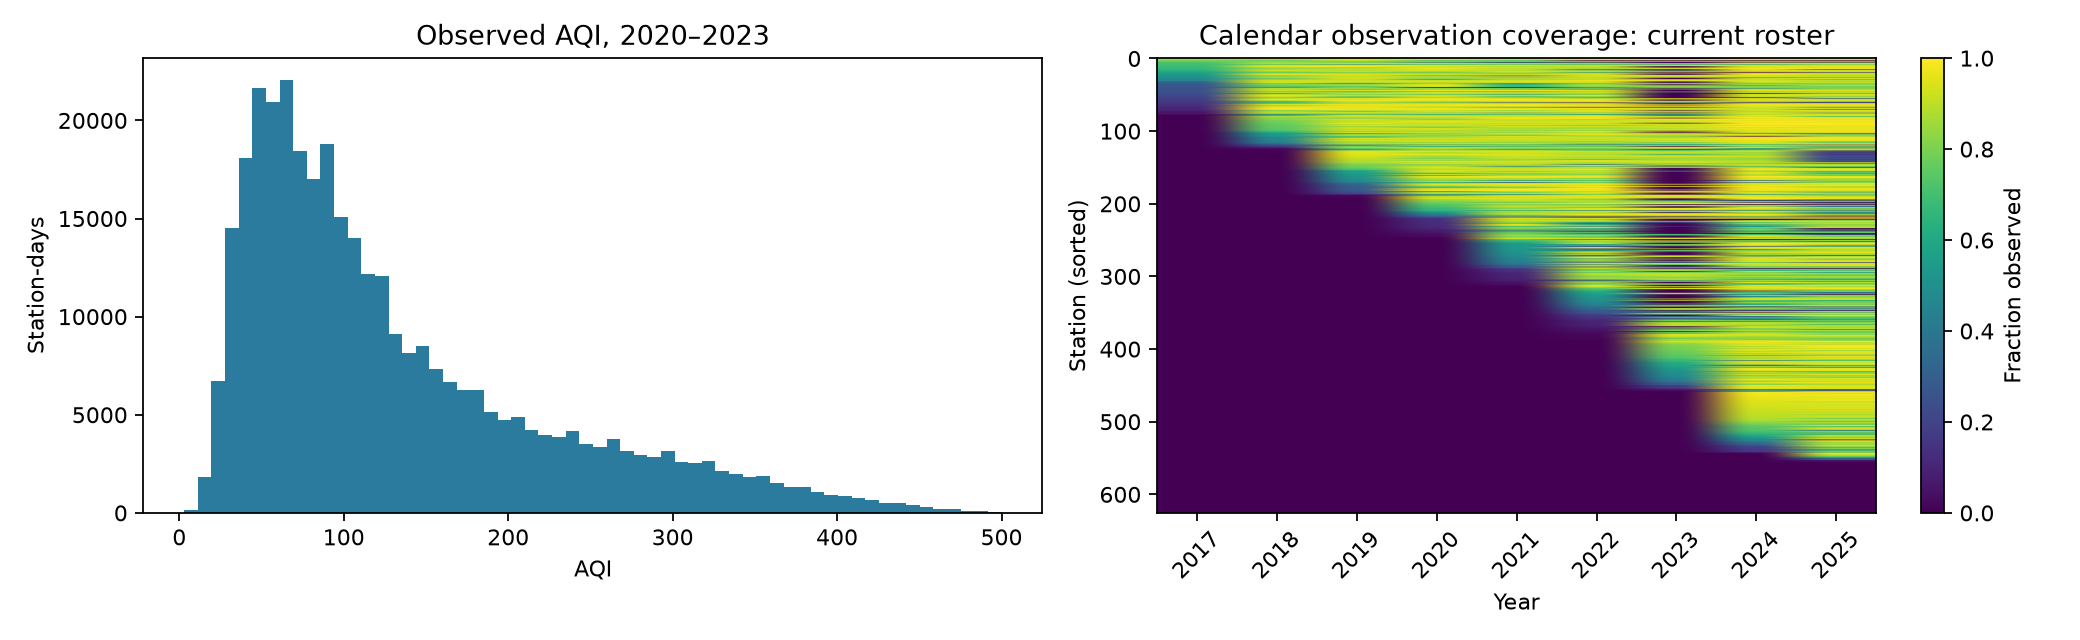

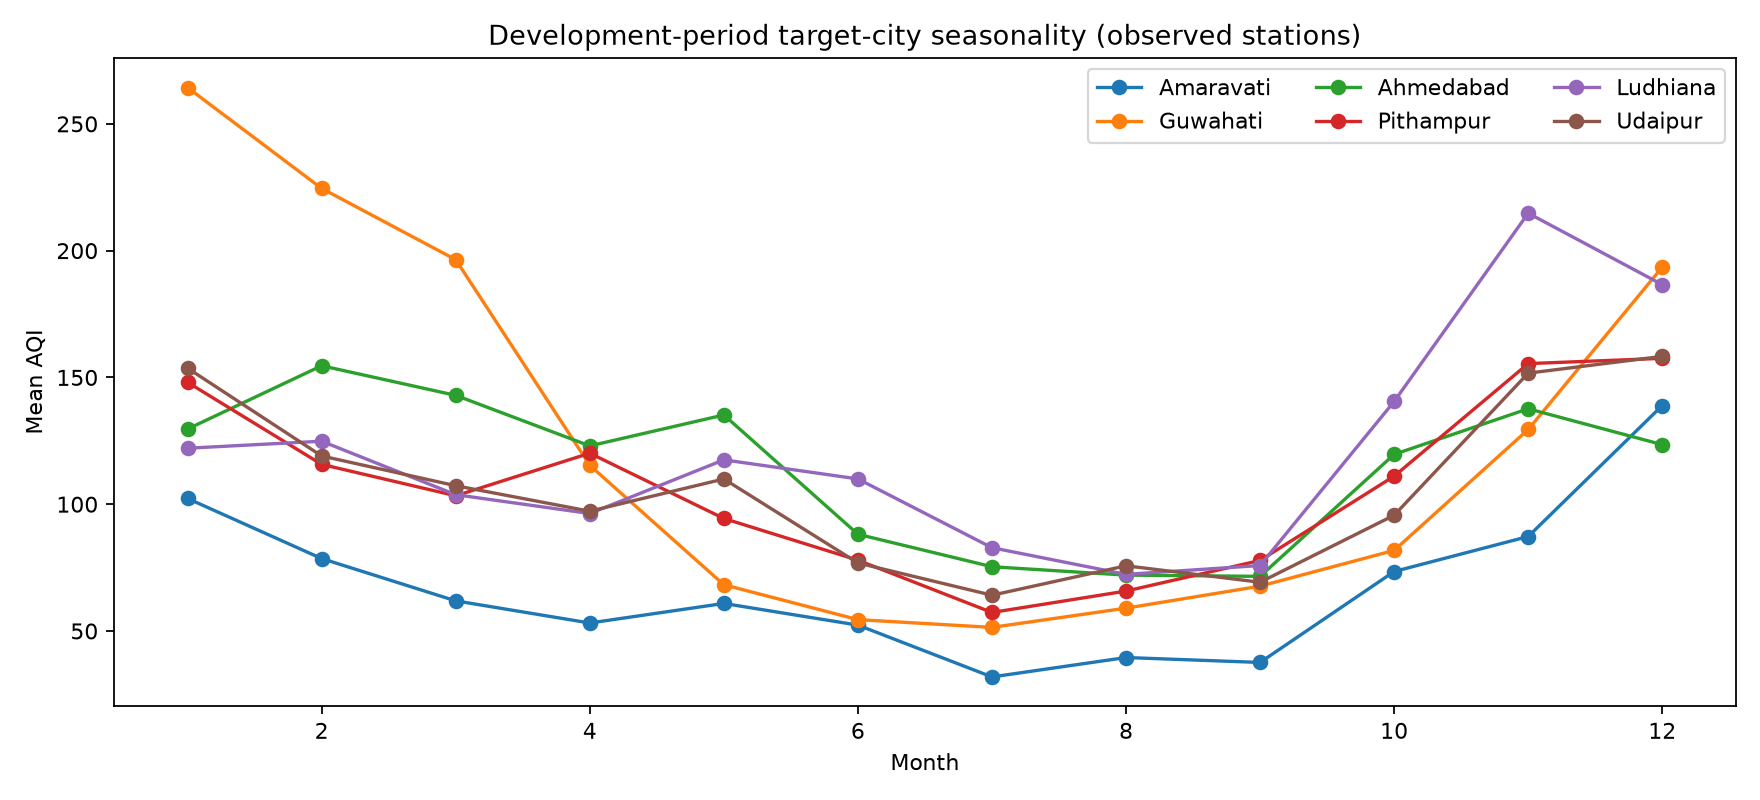

,station_id,city,lag_1,lag_2,lag_3,lag_7,lag_14
0,113,Delhi,0.879596,0.791900,0.741788,0.690028,0.655536
1,1390,Alwar,0.732846,0.594565,0.546022,0.445086,0.320990
2,1392,Ajmer,0.637487,0.527885,0.442853,0.299640,0.231739
3,1395,Pali,0.711131,0.580142,0.506950,0.466284,0.376228
4,1397,Udaipur,0.813690,0.697694,0.650248,0.551709,0.506475
5,1399,Rajamahendravaram,0.877412,0.761784,0.669826,0.514009,0.442978
6,1401,Singrauli,0.885769,0.817931,0.779127,0.733000,0.669783
7,1402,Pithampur,0.818030,0.715736,0.648040,0.539768,0.466469
8,1403,Mandideep,0.833341,0.738944,0.679585,0.609499,0.503113
9,1404,Dewas,0.813709,0.701773,0.635559,0.532352,0.407287


In [3]:
bundle, protocol, source_summary = prepare(SOURCE, OUT/'data')
display(pd.Series(source_summary))
display(pd.read_csv(OUT/'data/cohort.csv'))
display(pd.read_csv(OUT/'data/eligibility.csv'))
display(Image(filename=str(OUT/'data/eda_source.png')))
display(Image(filename=str(OUT/'data/eda_seasonality.png')))
display(pd.read_csv(OUT/'data/development_autocorrelation.csv'))


## Model families and fair comparisons
Persistence, seasonal persistence, recent mean, local Ridge, histogram gradient boosting and random forest provide simple controls. Small MLP, GRU, LSTM, TCN and Transformer models compare scratch training, pooled prediction and fine-tuning using the same permitted inputs. Reptile and first-order MAML use city tasks with disjoint support/query dates; they are not claimed to be full second-order MAML. All target results are inference-only after donor settings are fixed.


In [4]:
#!/usr/bin/env python3
"""Frozen, donor-selected residual forecasting engine for the final AQI study.

Public API: ``predictions, fit_log = train_all(bundle, outdir, config)``.
The canonical frame has station_id, city, date (label date), issue_date,
horizon (1/2/3), y, last, and x0..x6 (oldest to newest daily AQI).
Each selected city has one representative station and complete horizon triples.

Target ``validation`` is an evaluation-only 2024 period. It is never supplied to
any fitting or selection function. All choices use held-out donor cities.
Outputs are continuous, unbounded AQI. Source scaling is fixed, not fitted.
Run ``python final_model_engine.py --smoke --out /tmp/aqi-engine-smoke`` to test
all architectures, first-order meta updates, resume, and prediction alignment
on artificial data (no project outcome data).
"""
from __future__ import annotations

import argparse
import copy
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import random
import re
import sys
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from torch import nn
from torch.nn import functional as F


ENGINE_VERSION = "final-residual-v1.1"
ARCHITECTURES = ("gru", "lstm", "tcn", "transformer", "mlp")
BASELINES = ("persistence", "seasonal7", "mean7", "ridge_local", "histgb_local", "randomforest_local")
METHODS = (*BASELINES, *(f"{a}_{m}" for a in ARCHITECTURES for m in ("local", "pooled_zero", "finetune")),
           "reptile_gru", "fomaml_gru")
REQUIRED = ("station_id", "city", "date", "issue_date", "horizon", "y", "last", *(f"x{i}" for i in range(7)))
PREDICTION_COLUMNS = ("station_id", "city", "date", "issue_date", "horizon", "budget", "seed",
                      "method", "y_true", "y_pred", "last", "period")
DEFAULTS: dict[str, Any] = {
    "seeds": [17, 43, 71], "budgets": [30, 90, 180],
    "architectures": list(ARCHITECTURES), "hidden_size": 32,
    "batch_size": 128, "num_threads": 2, "device": "auto",
    "pooled_steps": 600, "pooled_lr": 0.001, "eval_every": 60,
    "weight_decay": 0.0001, "grad_clip": 1.0,
    # Scratch and fine-tuning get independent choices from equally sized grids.
    "adaptation_presets": [{"lr": 0.001, "steps": 100}, {"lr": 0.0003, "steps": 100}],
    "scratch_presets": [{"lr": 0.001, "steps": 100}, {"lr": 0.003, "steps": 250}],
    "pseudo_budgets": None, "pseudo_query_days": None,
    "meta_steps": 360, "meta_tasks": 3, "meta_inner_steps": 3,
    "meta_inner_lr": 0.01, "meta_outer_lr": 0.001,
    "reptile_outer_lr": 0.1, "meta_query_days": 14,
    "meta_validation_budget": 90, "purge_days": 9,
    "dev_cities": ["Chandigarh", "Dewas", "Jalandhar", "Ajmer"],
    "ridge_alpha": 10.0, "histgb_iterations": 100, "rf_trees": 128,
    "ridge_presets": [{"alpha": 1.0}, {"alpha": 100.0}],
    "histgb_presets": [{"min_samples_leaf": 5, "l2_regularization": 1.0},
                        {"min_samples_leaf": 15, "l2_regularization": 10.0}],
    "randomforest_presets": [{"min_samples_leaf": 1, "max_depth": None},
                              {"min_samples_leaf": 3, "max_depth": 6}],
    "resume": True, "save_target_states": True, "smoke": False,
}


def _jsonable(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.integer, np.floating)):
        return x.item()
    if isinstance(x, (Path, pd.Timestamp)):
        return str(x)
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def _atomic_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(_jsonable(value), indent=2, sort_keys=True), encoding="utf-8")
    os.replace(temp, path)


def _atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    frame.to_csv(temp, index=False, compression="gzip" if path.name.endswith(".gz") else None)
    os.replace(temp, path)


def _torch_save(path: Path, payload: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temp)
    os.replace(temp, path)


def _torch_load(path: Path, device: str | torch.device = "cpu") -> dict[str, Any]:
    # These are locally generated, trusted experiment checkpoints, never input data.
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:  # PyTorch before the weights_only argument.
        return torch.load(path, map_location=device)


def _slug(s: str) -> str:
    return re.sub(r"[^a-zA-Z0-9_-]+", "_", s).strip("_") + "_" + hashlib.sha256(s.encode()).hexdigest()[:8]


def _seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _config(config: dict[str, Any] | None) -> dict[str, Any]:
    c = copy.deepcopy(DEFAULTS)
    c.update(config or {})
    for key in ("seeds", "budgets"):
        c[key] = [int(v) for v in c[key]]
        if not c[key] or len(set(c[key])) != len(c[key]):
            raise ValueError(f"{key} must be a nonempty list without duplicates")
    if any(b < 1 for b in c["budgets"]):
        raise ValueError("Budgets must be positive")
    if not set(c["architectures"]).issubset(ARCHITECTURES):
        raise ValueError("Unknown neural architecture")
    if int(c["purge_days"]) < 9:
        raise ValueError("Meta/pseudo-task purge must have at least nine intervening calendar days")
    for grid in ("adaptation_presets", "scratch_presets"):
        if len(c[grid]) != 2 and not c["smoke"]:
            raise ValueError(f"{grid} must contain exactly two donor-tested presets")
        if not c[grid] or any(float(p["lr"]) <= 0 or int(p["steps"]) < 1 for p in c[grid]):
            raise ValueError(f"Invalid {grid}")
    if len(c["adaptation_presets"]) != len(c["scratch_presets"]):
        raise ValueError("Scratch and fine-tuning must have equally sized tuning grids")
    for k in ("batch_size", "eval_every", "num_threads", "meta_tasks", "meta_inner_steps", "meta_query_days"):
        if int(c[k]) < 1:
            raise ValueError(f"{k} must be positive")
    return c


def canonical_frame(frame: pd.DataFrame, name: str = "data") -> pd.DataFrame:
    """Validate, copy and sort without silently dropping or imputing a row."""
    if not isinstance(frame, pd.DataFrame):
        raise TypeError(f"{name} must be a pandas DataFrame")
    missing = set(REQUIRED) - set(frame)
    if missing:
        raise ValueError(f"{name}: missing columns {sorted(missing)}")
    d = frame.copy()
    if len(d) == 0:
        raise ValueError(f"{name}: empty frame")
    for col in ("station_id", "city"):
        if d[col].isna().any():
            raise ValueError(f"{name}: null {col}")
        d[col] = d[col].astype(str)
    for col in ("date", "issue_date"):
        d[col] = pd.to_datetime(d[col], errors="raise").dt.normalize()
    for col in ("horizon", "y", "last", *(f"x{i}" for i in range(7))):
        d[col] = pd.to_numeric(d[col], errors="raise")
        if not np.isfinite(d[col].to_numpy(float)).all():
            raise ValueError(f"{name}: nonfinite {col}")
    if not d.horizon.isin([1, 2, 3]).all():
        raise ValueError(f"{name}: horizons must be 1/2/3")
    d["horizon"] = d.horizon.astype(int)
    if not ((d.date - d.issue_date).dt.days == d.horizon).all():
        raise ValueError(f"{name}: label date must equal issue date plus horizon")
    if not np.allclose(d["last"], d.x6, rtol=0, atol=1e-6):
        raise ValueError(f"{name}: last must equal newest observed lag x6")
    if d.duplicated(["city", "date", "horizon"]).any():
        raise ValueError(f"{name}: duplicate city/date/horizon; exactly one representative station is required")
    if (d.groupby("city").station_id.nunique() != 1).any():
        raise ValueError(f"{name}: more than one station per city")
    triples = d.groupby(["city", "date"]).horizon.agg(["count", "nunique"])
    if not ((triples["count"] == 3) & (triples["nunique"] == 3)).all():
        raise ValueError(f"{name}: every label date must contain all three horizons")
    for col, expected in (("feature_date_min", d.issue_date - pd.Timedelta(days=6)),
                          ("feature_date_max", d.issue_date)):
        if col in d:
            actual = pd.to_datetime(d[col], errors="raise").dt.normalize()
            if not (actual == expected).all():
                raise ValueError(f"{name}: {col} does not match the seven-day past-only input")
            d[col] = actual
    if "issue_doy" in d and not (pd.to_numeric(d.issue_doy) == d.issue_date.dt.day_of_year).all():
        raise ValueError(f"{name}: inconsistent issue_doy")
    if "issue_dow" in d and not (pd.to_numeric(d.issue_dow) == d.issue_date.dt.day_of_week).all():
        raise ValueError(f"{name}: inconsistent issue_dow (Monday must be zero)")
    return d.sort_values(["city", "date", "horizon"]).reset_index(drop=True)


def select_budget(frame: pd.DataFrame, budget: int) -> pd.DataFrame:
    """Last B common label dates, exactly 3B rows; caller supplies one city."""
    if frame.city.nunique() != 1:
        raise ValueError("select_budget requires exactly one city")
    dates = np.sort(frame.date.unique())
    if len(dates) < budget:
        raise ValueError(f"Only {len(dates)} label dates available for budget {budget}")
    d = frame[frame.date.isin(dates[-budget:])].copy().reset_index(drop=True)
    if len(d) != 3 * budget or d.date.nunique() != budget:
        raise AssertionError("Budget must be exactly B labels and 3B examples")
    return d


def feature_array(frame: pd.DataFrame) -> np.ndarray:
    """7x6 fixed-scale features. Calendar phases use the forecast issue day."""
    n = len(frame)
    x = np.empty((n, 7, 6), dtype=np.float32)
    x[:, :, 0] = frame[[f"x{i}" for i in range(7)]].to_numpy(np.float32) / 500.0
    doy = frame.issue_date.dt.day_of_year.to_numpy(float)
    dow = frame.issue_date.dt.day_of_week.to_numpy(float)
    calendar = np.column_stack((np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25),
                                np.sin(2 * np.pi * dow / 7.0), np.cos(2 * np.pi * dow / 7.0),
                                frame.horizon.to_numpy(float) / 3.0))
    x[:, :, 1:] = calendar[:, None, :]
    return x


class ResidualForecaster(nn.Module):
    def __init__(self, architecture: str, hidden: int = 32):
        super().__init__()
        self.architecture = architecture
        self.hidden = hidden
        if architecture == "gru":
            self.body = nn.GRU(6, hidden, batch_first=True)
        elif architecture == "lstm":
            self.body = nn.LSTM(6, hidden, batch_first=True)
        elif architecture == "tcn":
            self.conv1 = nn.Conv1d(6, hidden, 3)
            self.conv2 = nn.Conv1d(hidden, hidden, 3, dilation=2)
        elif architecture == "transformer":
            if hidden % 4:
                raise ValueError("Transformer hidden size must be divisible by four")
            self.embed = nn.Linear(6, hidden)
            layer = nn.TransformerEncoderLayer(hidden, 4, hidden * 2, dropout=0.0, activation="gelu",
                                                batch_first=True, norm_first=False)
            self.body = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
            positions = torch.arange(7).float()[:, None]
            div = torch.exp(torch.arange(0, hidden, 2).float() * (-math.log(10000.0) / hidden))
            pos = torch.zeros(7, hidden)
            pos[:, 0::2] = torch.sin(positions * div)
            pos[:, 1::2] = torch.cos(positions * div)
            self.register_buffer("positions", pos[None, :, :])
        elif architecture == "mlp":
            self.body = nn.Sequential(nn.Flatten(), nn.Linear(42, hidden), nn.ReLU(),
                                      nn.Linear(hidden, hidden), nn.ReLU())
        else:
            raise ValueError(f"Unknown architecture {architecture}")
        self.head = nn.Linear(hidden, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.architecture in ("gru", "lstm"):
            z = self.body(x)[0][:, -1]
        elif self.architecture == "tcn":
            z = F.relu(self.conv1(F.pad(x.transpose(1, 2), (2, 0))))
            z = F.relu(self.conv2(F.pad(z, (4, 0))))[:, :, -1]
        elif self.architecture == "transformer":
            z = self.body(self.embed(x) + self.positions)[:, -1]
        else:
            z = self.body(x)
        return self.head(z).squeeze(-1)


def _new_model(architecture: str, seed: int, c: dict[str, Any], device: torch.device) -> ResidualForecaster:
    _seed(seed)
    return ResidualForecaster(architecture, int(c["hidden_size"])).to(device)


def _state(model: nn.Module) -> dict[str, torch.Tensor]:
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


@dataclass
class ArrayData:
    x: torch.Tensor
    residual: torch.Tensor
    cities: np.ndarray
    dates: np.ndarray


def _arrays(frame: pd.DataFrame, device: torch.device) -> ArrayData:
    return ArrayData(torch.as_tensor(feature_array(frame), device=device),
                     torch.as_tensor((frame.y.to_numpy(np.float32) - frame["last"].to_numpy(np.float32)) / 100.0,
                                     device=device),
                     frame.city.to_numpy(str), frame.date.to_numpy())


class CitySampler:
    """Uniform city, then uniform example within city, using a local RNG."""
    def __init__(self, cities: np.ndarray, seed: int):
        self.groups = [np.flatnonzero(cities == city) for city in sorted(set(cities))]
        self.rng = np.random.default_rng(seed)
        self.n = len(cities)

    def sample(self, batch_size: int) -> np.ndarray:
        groups = self.rng.integers(len(self.groups), size=min(batch_size, self.n))
        result = np.empty(len(groups), dtype=np.int64)
        for k in np.unique(groups):
            pos = np.flatnonzero(groups == k)
            result[pos] = self.rng.choice(self.groups[int(k)], size=len(pos), replace=True)
        return result


def predict_neural(model: nn.Module, frame: pd.DataFrame, device: torch.device, batch_size: int = 2048) -> np.ndarray:
    model.eval()
    x = feature_array(frame)
    parts = []
    with torch.inference_mode():
        for start in range(0, len(x), batch_size):
            parts.append(model(torch.as_tensor(x[start:start + batch_size], device=device)).cpu().numpy())
    residual = np.concatenate(parts).astype(float)
    result = frame["last"].to_numpy(float) + residual * 100.0
    if not np.isfinite(result).all():
        raise FloatingPointError("Neural predictions are nonfinite")
    return result


def _macro_mae(model: nn.Module, frame: pd.DataFrame, device: torch.device) -> float:
    errors = frame[["city", "horizon"]].copy()
    errors["error"] = np.abs(predict_neural(model, frame, device) - frame.y.to_numpy(float))
    return float(errors.groupby(["city", "horizon"]).error.mean().mean())


@dataclass
class FitResult:
    model: ResidualForecaster
    selected_step: int
    validation_mae: float | None
    history: list[dict[str, Any]]
    elapsed: float
    episodes: list[dict[str, Any]] | None = None


def fit_neural(model: ResidualForecaster, train: pd.DataFrame, *, steps: int, lr: float, seed: int,
               c: dict[str, Any], device: torch.device, validation: pd.DataFrame | None = None,
               checkpoint: Path | None = None, select_best: bool = False) -> FitResult:
    """City-balanced Adam/MSE; checkpoints selected only by uncapped donor MAE."""
    start = time.perf_counter()
    data = _arrays(train, device)
    sampler = CitySampler(data.cities, seed + 991)
    opt = torch.optim.Adam(model.parameters(), lr=float(lr), weight_decay=float(c["weight_decay"]))
    history: list[dict[str, Any]] = []
    first_step, elapsed_before = 0, 0.0
    best_mae = float("inf")
    best_state, best_step = _state(model), 0
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        saved = _torch_load(checkpoint, device)
        if int(saved["requested_steps"]) != steps or float(saved["lr"]) != float(lr):
            raise ValueError(f"Checkpoint training settings differ: {checkpoint}")
        model.load_state_dict(saved["state_dict"])
        opt.load_state_dict(saved["optimizer"])
        sampler.rng.bit_generator.state = saved["sampler_rng"]
        first_step = int(saved["step"])
        history = saved["history"]
        best_state, best_step, best_mae = saved["best_state"], int(saved["best_step"]), float(saved["best_mae"])
        elapsed_before = float(saved["elapsed"])
    elif validation is not None:
        best_mae = _macro_mae(model, validation, device)
        history.append({"step": 0, "loss": None, "validation_mae": best_mae})
    if select_best and validation is None:
        raise ValueError("Best-checkpoint selection requires a donor validation frame")
    for step in range(first_step + 1, int(steps) + 1):
        idx = torch.as_tensor(sampler.sample(int(c["batch_size"])), device=device)
        model.train()
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(data.x[idx]), data.residual[idx])
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Nonfinite training loss at step {step}")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
        opt.step()
        if step % int(c["eval_every"]) == 0 or step == steps:
            mae = _macro_mae(model, validation, device) if validation is not None else None
            history.append({"step": step, "loss": float(loss.detach().cpu()), "validation_mae": mae})
            if mae is not None and mae < best_mae - 1e-9:
                best_mae, best_step, best_state = mae, step, _state(model)
            if checkpoint is not None:
                _torch_save(checkpoint, {"state_dict": _state(model), "optimizer": opt.state_dict(),
                    "step": step, "requested_steps": steps, "lr": lr, "sampler_rng": sampler.rng.bit_generator.state,
                    "history": history, "best_state": best_state, "best_step": best_step, "best_mae": best_mae,
                    "elapsed": elapsed_before + time.perf_counter() - start})
    elapsed = elapsed_before + time.perf_counter() - start
    if select_best:
        model.load_state_dict(best_state)
    else:
        best_step = int(steps)
    return FitResult(model, best_step, best_mae if validation is not None else None, history, elapsed)


def _pseudo_tasks(train: pd.DataFrame, query: pd.DataFrame, cities: list[str], budgets: list[int],
                  c: dict[str, Any]) -> list[tuple[str, int, pd.DataFrame, pd.DataFrame]]:
    tasks = []
    for city in cities:
        q = query[query.city == city].copy()
        if q.empty:
            raise ValueError(f"No donor pseudo-query for {city}")
        if c["pseudo_query_days"] is not None:
            dates = np.sort(q.date.unique())[:int(c["pseudo_query_days"])]
            q = q[q.date.isin(dates)].copy()
        # Nine *intervening* days is stricter than just a nine-day date difference.
        latest_support = q.date.min() - pd.Timedelta(days=int(c["purge_days"]) + 1)
        support = train[(train.city == city) & (train.date <= latest_support)]
        for budget in budgets:
            s = select_budget(support, int(budget))
            if (q.date.min() - s.date.max()).days <= int(c["purge_days"]):
                raise AssertionError("Pseudo-task temporal purge violated")
            tasks.append((city, int(budget), s, q))
    return tasks


def _adapt(model: ResidualForecaster, support: pd.DataFrame, preset: dict[str, Any], seed: int,
           c: dict[str, Any], device: torch.device) -> FitResult:
    return fit_neural(model, support, steps=int(preset["steps"]), lr=float(preset["lr"]), seed=seed,
                      c=c, device=device)


def tune_presets(architecture: str, base: ResidualForecaster | None,
                 tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]], presets: list[dict[str, Any]],
                 *, seed: int, c: dict[str, Any], device: torch.device, label: str,
                 out: Path) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    cache = out / "selection" / f"{label}.json"
    if cache.exists() and c["resume"]:
        saved = json.loads(cache.read_text())
        return saved["selected_preset"], saved["scores"]
    scores = []
    for candidate, preset in enumerate(presets):
        for task_idx, (city, budget, support, query) in enumerate(tasks):
            model = _new_model(architecture, seed, c, device) if base is None else copy.deepcopy(base).to(device)
            result = _adapt(model, support, preset, seed + task_idx * 37, c, device)
            scores.append({"selection": label, "candidate": candidate, "lr": float(preset["lr"]),
                "steps": int(preset["steps"]), "city": city, "budget": budget,
                "macro_horizon_mae": _macro_mae(result.model, query, device), "seed": seed,
                "support_first": support.date.min(), "support_last": support.date.max(),
                "query_first": query.date.min(), "query_last": query.date.max(),
                "purge_intervening_days": (query.date.min() - support.date.max()).days - 1,
                "fit_seconds": result.elapsed, "support_examples": len(support),
                "query_examples": len(query), "architecture": architecture,
                "parameters": sum(p.numel() for p in result.model.parameters())})
            del model, result
    table = pd.DataFrame(scores)
    # Equal weight for each held-out city, label budget and horizon; strict tie-break by grid order.
    ranking = table.groupby("candidate", sort=True).macro_horizon_mae.mean()
    chosen = int(ranking.idxmin())
    selected = copy.deepcopy(presets[chosen])
    _atomic_json(cache, {"selected_candidate": chosen, "selected_preset": selected,
        "mean_macro_mae": ranking.to_dict(), "scores": scores,
        "selection_source": "held-out donor-city 2023 pseudo-query; targets entirely excluded"})
    return selected, scores


class EpisodeSampler:
    """Uniform donor-city tasks with disjoint, chronological support/query labels."""
    def __init__(self, train: pd.DataFrame, budgets: list[int], query_days: int, purge_days: int, seed: int):
        self.rng = np.random.default_rng(seed)
        self.groups: dict[str, dict[str, Any]] = {}
        self.budgets, self.query_days, self.purge_days = budgets, query_days, purge_days
        for city in sorted(train.city.unique()):
            g = train[train.city == city]
            dates = np.sort(g.date.unique())
            index = {date: g.index[g.date == date].to_numpy() for date in dates}
            # Require the largest budget for every sampled city; no city is silently underweighted.
            starts = []
            for j in range(len(dates) - query_days + 1):
                cutoff = dates[j] - np.timedelta64(purge_days + 1, "D")
                n_support = int(np.searchsorted(dates, cutoff, side="right"))
                if n_support >= max(budgets):
                    starts.append((j, n_support))
            if not starts:
                raise ValueError(f"Donor {city} cannot form a purged {max(budgets)}-label meta episode")
            self.groups[str(city)] = {"dates": dates, "index": index, "starts": starts}
        self.cities = sorted(self.groups)

    def sample(self) -> tuple[np.ndarray, np.ndarray, dict[str, Any]]:
        city = self.cities[int(self.rng.integers(len(self.cities)))]
        g = self.groups[city]
        budget = int(self.rng.choice(self.budgets))
        j, count = g["starts"][int(self.rng.integers(len(g["starts"])))]
        sd = g["dates"][count - budget:count]
        qd = g["dates"][j:j + self.query_days]
        support = np.concatenate([g["index"][date] for date in sd])
        query = np.concatenate([g["index"][date] for date in qd])
        gap = int((qd[0] - sd[-1]) / np.timedelta64(1, "D")) - 1
        if gap < self.purge_days or np.intersect1d(sd, qd).size:
            raise AssertionError("Meta support/query leakage")
        return support, query, {"city": city, "budget": budget, "support_first": str(sd[0])[:10],
            "support_last": str(sd[-1])[:10], "query_first": str(qd[0])[:10], "query_last": str(qd[-1])[:10],
            "purge_intervening_days": gap, "support_examples": len(support), "query_examples": len(query)}


def _inner_updates(model: ResidualForecaster, data: ArrayData, indices: np.ndarray, rng: np.random.Generator,
                   steps: int, lr: float, c: dict[str, Any], device: torch.device) -> None:
    # No differentiable optimizer is used: query gradients for FOMAML are explicitly first order.
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    model.train()
    for _ in range(steps):
        selected = rng.choice(indices, size=min(int(c["batch_size"]), len(indices)), replace=True)
        idx = torch.as_tensor(selected, device=device)
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(data.x[idx]), data.residual[idx])
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite meta inner loss")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
        opt.step()


def _meta_validation(model: ResidualForecaster, tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]],
                      c: dict[str, Any], device: torch.device, seed: int) -> float:
    errors = []
    for i, (_, _, support, query) in enumerate(tasks):
        adapted = copy.deepcopy(model).to(device)
        data = _arrays(support, device)
        _inner_updates(adapted, data, np.arange(len(support)), np.random.default_rng(seed + i),
                       int(c["meta_inner_steps"]), float(c["meta_inner_lr"]), c, device)
        errors.append(_macro_mae(adapted, query, device))
        del adapted, data
    return float(np.mean(errors))


def fit_meta(algorithm: str, train: pd.DataFrame, *, steps: int, seed: int, c: dict[str, Any],
             device: torch.device, validation_tasks: list | None = None,
             checkpoint: Path | None = None, select_best: bool = False) -> FitResult:
    if algorithm not in ("reptile", "fomaml"):
        raise ValueError(algorithm)
    start = time.perf_counter()
    model = _new_model("gru", seed, c, device)
    train = train.reset_index(drop=True)
    data = _arrays(train, device)
    sampler = EpisodeSampler(train, list(c["budgets"]), int(c["meta_query_days"]), int(c["purge_days"]), seed + 177)
    rng = np.random.default_rng(seed + 7919)
    outer = torch.optim.Adam(model.parameters(), lr=float(c["meta_outer_lr"])) if algorithm == "fomaml" else None
    history, episodes = [], []
    best_state, best_step, best_mae = _state(model), 0, float("inf")
    first_step, elapsed_before = 0, 0.0
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        saved = _torch_load(checkpoint, device)
        if saved["algorithm"] != algorithm or int(saved["requested_steps"]) != steps:
            raise ValueError("Meta checkpoint settings differ")
        model.load_state_dict(saved["state_dict"])
        if outer is not None:
            outer.load_state_dict(saved["optimizer"])
        sampler.rng.bit_generator.state, rng.bit_generator.state = saved["sampler_rng"], saved["inner_rng"]
        first_step, history, episodes = int(saved["step"]), saved["history"], saved["episodes"]
        best_state, best_step, best_mae = saved["best_state"], int(saved["best_step"]), float(saved["best_mae"])
        elapsed_before = float(saved["elapsed"])
    elif validation_tasks is not None:
        best_mae = _meta_validation(model, validation_tasks, c, device, seed)
        history.append({"step": 0, "query_mse": None, "validation_adapted_mae": best_mae})
    if select_best and validation_tasks is None:
        raise ValueError("Meta checkpoint selection needs donor validation tasks")
    for step in range(first_step + 1, steps + 1):
        accum = [torch.zeros_like(p) for p in model.parameters()]
        query_losses = []
        for task_number in range(int(c["meta_tasks"])):
            si, qi, audit = sampler.sample()
            audit.update({"step": step, "task": task_number, "algorithm": algorithm, "seed": seed})
            episodes.append(audit)
            adapted = copy.deepcopy(model).to(device)
            _inner_updates(adapted, data, si, rng, int(c["meta_inner_steps"]), float(c["meta_inner_lr"]), c, device)
            query_idx = torch.as_tensor(qi, device=device)
            if algorithm == "fomaml":
                adapted.zero_grad(set_to_none=True)
                query_loss = F.mse_loss(adapted(data.x[query_idx]), data.residual[query_idx])
                if not torch.isfinite(query_loss):
                    raise FloatingPointError("Nonfinite FOMAML query loss")
                query_loss.backward()
                for total, p in zip(accum, adapted.parameters()):
                    if p.grad is not None:
                        total.add_(p.grad.detach())
            else:
                with torch.no_grad():
                    query_loss = F.mse_loss(adapted(data.x[query_idx]), data.residual[query_idx])
                    if not torch.isfinite(query_loss):
                        raise FloatingPointError("Nonfinite Reptile query loss")
                    for total, p in zip(accum, adapted.parameters()):
                        total.add_(p.detach())
            query_losses.append(float(query_loss.detach().cpu()))
            del adapted
        tasks = int(c["meta_tasks"])
        if algorithm == "fomaml":
            outer.zero_grad(set_to_none=True)
            # Copy gradients at adapted parameters to theta. No Hessian/inner-graph terms.
            for p, total in zip(model.parameters(), accum):
                p.grad = total.div_(tasks)
            nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
            outer.step()
        else:
            epsilon = float(c["reptile_outer_lr"])  # fixed schedule also usable in fixed-step final refit
            with torch.no_grad():
                for p, total in zip(model.parameters(), accum):
                    p.add_(epsilon * (total.div_(tasks) - p))
        if step % int(c["eval_every"]) == 0 or step == steps:
            mae = _meta_validation(model, validation_tasks, c, device, seed) if validation_tasks is not None else None
            history.append({"step": step, "query_mse": float(np.mean(query_losses)), "validation_adapted_mae": mae})
            if mae is not None and mae < best_mae - 1e-9:
                best_mae, best_step, best_state = mae, step, _state(model)
            if checkpoint is not None:
                _torch_save(checkpoint, {"algorithm": algorithm, "state_dict": _state(model),
                    "optimizer": outer.state_dict() if outer is not None else None,
                    "step": step, "requested_steps": steps, "sampler_rng": sampler.rng.bit_generator.state,
                    "inner_rng": rng.bit_generator.state, "history": history, "episodes": episodes,
                    "best_state": best_state, "best_step": best_step, "best_mae": best_mae,
                    "elapsed": elapsed_before + time.perf_counter() - start})
    elapsed = elapsed_before + time.perf_counter() - start
    if select_best:
        model.load_state_dict(best_state)
    else:
        best_step = steps
    return FitResult(model, best_step, best_mae if validation_tasks is not None else None,
                     history, elapsed, episodes)


def _bundle(bundle: dict[str, Any], c: dict[str, Any]) -> dict[str, Any]:
    d = {key: canonical_frame(bundle[key], key) for key in ("donor_train", "donor_val", "donor_full")}
    d["targets"] = {str(city): {part: canonical_frame(value[part], f"{city}/{part}")
                              for part in ("adapt", "validation", "test")}
                    for city, value in bundle["targets"].items()}
    if not d["targets"]:
        raise ValueError("No target cities")
    donors = set(d["donor_full"].city)
    if donors & set(d["targets"]):
        raise ValueError("Selected target cities must be globally excluded from donors")
    if set(d["donor_train"].city) != donors or set(d["donor_val"].city) != donors:
        raise ValueError("Donor train/validation/full must contain the same cities")
    d["dev_cities"] = [str(v) for v in bundle.get("dev_cities", c["dev_cities"])]
    if not d["dev_cities"] or not set(d["dev_cities"]).issubset(donors):
        raise ValueError("dev_cities must be a nonempty subset of donor cities")
    if set(d["dev_cities"]) == donors:
        raise ValueError("Need donor cities outside development pseudo-tasks")
    for key, lo, hi in (("donor_train", "2020-01-01", "2022-12-31"),
                        ("donor_val", "2023-01-01", "2023-12-31"),
                        ("donor_full", "2020-01-01", "2023-12-31")):
        if not d[key].date.between(lo, hi).all():
            raise ValueError(f"{key}: label date outside declared window")
    if (d["donor_val"].issue_date < pd.Timestamp("2023-01-01")).any():
        raise ValueError("Donor validation issue dates must follow the 2022 fitting cutoff")
    # Final refit may also use the early-Jan-2023 labels excluded from the strict
    # donor-validation issue-date boundary; it must contain every source row unchanged.
    cols = list(REQUIRED)
    union = pd.concat([d["donor_train"], d["donor_val"]], ignore_index=True).sort_values(["city", "date", "horizon"])
    full = d["donor_full"].sort_values(["city", "date", "horizon"])
    union_hash = pd.util.hash_pandas_object(union[cols], index=False).to_numpy()
    full_hash = pd.util.hash_pandas_object(full[cols], index=False).to_numpy()
    if not np.isin(union_hash, full_hash).all():
        raise ValueError("donor_full must contain every donor_train and donor_val row unchanged")
    for city in donors:
        if len({str(d[key].loc[d[key].city == city, "station_id"].iloc[0])
                for key in ("donor_train", "donor_val", "donor_full")}) != 1:
            raise ValueError(f"{city}: donor station identity changes across periods")
    for city, parts in d["targets"].items():
        for part, frame in parts.items():
            if set(frame.city) != {city}:
                raise ValueError(f"{city}/{part}: city key and rows differ")
        if len({str(frame.station_id.iloc[0]) for frame in parts.values()}) != 1:
            raise ValueError(f"{city}: target station identity changes across periods")
        if not (parts["adapt"].date <= pd.Timestamp("2023-12-31")).all():
            raise ValueError("Target adaptation labels must be <= 2023-12-31")
        select_budget(parts["adapt"], max(c["budgets"]))
        for part, year in (("validation", 2024), ("test", 2025)):
            if not (parts[part].date.dt.year == year).all():
                raise ValueError(f"{city}/{part}: expected {year} labels")
            if (parts[part].issue_date < pd.Timestamp("2024-01-01")).any():
                raise ValueError(f"{city}/{part}: issue date must follow the actual 2023 fitting cutoff")
    return d


def _fingerprint(data: dict[str, Any], c: dict[str, Any]) -> str:
    digest = hashlib.sha256(ENGINE_VERSION.encode())
    # Resume and output preferences do not change scientific results.
    settings = {k: v for k, v in c.items() if k not in ("resume", "save_target_states")}
    digest.update(json.dumps(_jsonable(settings), sort_keys=True).encode())
    digest.update(json.dumps(data["dev_cities"]).encode())
    frames = [(key, data[key]) for key in ("donor_train", "donor_val", "donor_full")]
    frames += [(f"{city}/{part}", frame) for city, parts in sorted(data["targets"].items())
               for part, frame in sorted(parts.items())]
    for name, frame in frames:
        digest.update(name.encode())
        digest.update(pd.util.hash_pandas_object(frame[list(REQUIRED)], index=False).to_numpy().tobytes())
    return digest.hexdigest()


def _fit_row(result: FitResult, *, stage: str, method: str, seed: int, train: pd.DataFrame,
              lr: float | None, requested_steps: int, city: str = "", budget: int | None = None) -> dict[str, Any]:
    return {"stage": stage, "method": method, "seed": seed, "city": city, "budget": budget,
        "architecture": result.model.architecture, "parameters": sum(p.numel() for p in result.model.parameters()),
        "train_examples": len(train), "train_label_dates": train.date.nunique(), "train_cities": train.city.nunique(),
        "train_first_label": train.date.min(), "train_last_label": train.date.max(), "lr": lr,
        "requested_steps": requested_steps, "selected_step": result.selected_step,
        "donor_validation_mae": result.validation_mae, "fit_seconds": result.elapsed,
        "selection_at_step_limit": (result.selected_step == requested_steps) if "selection" in stage else None,
        "selection_kept_persistence_initialization": (result.selected_step == 0) if "selection" in stage else None,
        "convergence_claimed": False,
        "selection_data": "donors only" if stage != "target_fit" else "preset frozen on donor pseudo-tasks",
        "target_validation_used": False}


def _save_fit(out: Path, name: str, result: FitResult, row: dict[str, Any]) -> None:
    _atomic_json(out / "fit_records" / f"{name}.json", row)
    _atomic_csv(out / "histories" / f"{name}.csv", pd.DataFrame(result.history))
    if result.episodes is not None:
        _atomic_csv(out / "meta_episodes" / f"{name}.csv.gz", pd.DataFrame(result.episodes))


def _prediction_rows(frame: pd.DataFrame, y_pred: np.ndarray, *, method: str, budget: int, seed: int,
                      period: str) -> pd.DataFrame:
    result = frame[["station_id", "city", "date", "issue_date", "horizon", "last"]].copy()
    result["budget"], result["seed"], result["method"] = budget, seed, method
    result["y_true"], result["y_pred"], result["period"] = frame.y.to_numpy(float), y_pred, period
    if len(y_pred) != len(result) or not np.isfinite(y_pred).all():
        raise ValueError("Prediction length/finiteness failure")
    for col in ("date", "issue_date"):
        result[col] = result[col].dt.strftime("%Y-%m-%d")
    return result[list(PREDICTION_COLUMNS)]


def _baseline(method: str, support: pd.DataFrame, queries: list[pd.DataFrame], seed: int,
              c: dict[str, Any], preset: dict[str, Any] | None = None
              ) -> tuple[list[np.ndarray], int | None, Any, float]:
    preset = preset or {}
    if method == "persistence":
        return [q["last"].to_numpy(float) for q in queries], 0, None, 0.0
    if method == "seasonal7":
        return [q[[f"x{i}" for i in range(7)]].to_numpy(float)[np.arange(len(q)), q.horizon.to_numpy(int) - 1]
                for q in queries], 0, None, 0.0
    if method == "mean7":
        return [q[[f"x{i}" for i in range(7)]].to_numpy(float).mean(axis=1) for q in queries], 0, None, 0.0
    if method == "ridge_local":
        model = Ridge(alpha=float(preset.get("alpha", c["ridge_alpha"])), solver="cholesky")
    elif method == "histgb_local":
        model = HistGradientBoostingRegressor(max_iter=int(c["histgb_iterations"]), learning_rate=0.05,
            max_leaf_nodes=7, min_samples_leaf=int(preset.get("min_samples_leaf", 10)),
            l2_regularization=float(preset.get("l2_regularization", 1.0)), early_stopping=False, random_state=seed)
    elif method == "randomforest_local":
        model = RandomForestRegressor(n_estimators=int(c["rf_trees"]), max_depth=preset.get("max_depth", 6),
                                      min_samples_leaf=int(preset.get("min_samples_leaf", 3)),
                                      max_features=1.0, n_jobs=int(c["num_threads"]), random_state=seed)
    else:
        raise ValueError(method)
    x = feature_array(support).reshape(len(support), -1)
    y = (support.y.to_numpy(float) - support["last"].to_numpy(float)) / 100.0
    start = time.perf_counter()
    model.fit(x, y)
    fit_seconds = time.perf_counter() - start
    return [q["last"].to_numpy(float) + 100.0 * model.predict(feature_array(q).reshape(len(q), -1))
            for q in queries], (x.shape[1] + 1 if method == "ridge_local" else None), model, fit_seconds


def tune_baselines(tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]], seed: int,
                    c: dict[str, Any], out: Path) -> dict[str, dict[str, Any]]:
    """Cheap, equally bounded donor-only tuning for the three local regressors."""
    settings = {}
    for method, grid in (("ridge_local", c["ridge_presets"]), ("histgb_local", c["histgb_presets"]),
                         ("randomforest_local", c["randomforest_presets"])):
        cache = out / "selection" / f"{method}.json"
        if cache.exists() and c["resume"]:
            settings[method] = json.loads(cache.read_text())["selected_preset"]
            continue
        scores = []
        for candidate, preset in enumerate(grid):
            for city, budget, support, query in tasks:
                predictions, parameters, _, seconds = _baseline(method, support, [query], seed, c, preset)
                errors = query[["horizon"]].copy()
                errors["error"] = np.abs(predictions[0] - query.y.to_numpy(float))
                scores.append({"selection": method, "candidate": candidate, "preset": json.dumps(preset, sort_keys=True),
                    "city": city, "budget": budget, "seed": seed, "architecture": method.removesuffix("_local"),
                    "parameters": parameters, "macro_horizon_mae": float(errors.groupby("horizon").error.mean().mean()),
                    "fit_seconds": seconds, "support_examples": len(support), "query_examples": len(query),
                    "support_first": support.date.min(), "support_last": support.date.max(),
                    "query_first": query.date.min(), "query_last": query.date.max(),
                    "purge_intervening_days": (query.date.min() - support.date.max()).days - 1})
        ranking = pd.DataFrame(scores).groupby("candidate", sort=True).macro_horizon_mae.mean()
        chosen = int(ranking.idxmin())
        settings[method] = copy.deepcopy(grid[chosen])
        _atomic_json(cache, {"selected_candidate": chosen, "selected_preset": settings[method],
            "mean_macro_mae": ranking.to_dict(), "scores": scores,
            "selection_source": "held-out donor-city 2023 pseudo-query; targets entirely excluded"})
    return settings


def _save_candidate_table(out: Path) -> None:
    scores = []
    for path in sorted((out / "selection").glob("*.json")):
        value = json.loads(path.read_text())
        for score in value["scores"]:
            row = {**score, "stage": "donor_pseudo_candidate", "method": score["selection"],
                   "selected_candidate": value["selected_candidate"],
                   "candidate_selected": int(score["candidate"]) == int(value["selected_candidate"]),
                   "target_validation_used": False}
            scores.append(row)
            name = f"candidate_{score['selection']}_c{score['candidate']}_{_slug(score['city'])}_b{score['budget']}_s{score['seed']}"
            _atomic_json(out / "fit_records" / f"{name}.json", row)
    _atomic_csv(out / "donor_candidate_scores.csv", pd.DataFrame(scores))


def _metadata(out: Path, data: dict[str, Any], c: dict[str, Any], device: torch.device) -> str:
    fingerprint = _fingerprint(data, c)
    path = out / "engine_metadata.json"
    if path.exists():
        previous = json.loads(path.read_text())
        if previous["fingerprint"] != fingerprint:
            raise ValueError("Output directory belongs to a different bundle/config; choose a new output directory")
        if not c["resume"]:
            raise ValueError("Output directory already contains a run; use resume or a new output directory")
        return fingerprint
    versions = {package: importlib.metadata.version(package) for package in ("numpy", "pandas", "scikit-learn", "torch")}
    _atomic_json(path, {"engine_version": ENGINE_VERSION, "fingerprint": fingerprint, "config": c,
        "python": sys.version, "platform": platform.platform(), "versions": versions,
        "device": str(device), "cuda_version": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "deterministic_algorithms": True, "methods": METHODS, "dev_cities": data["dev_cities"],
        "donor_cities": sorted(data["donor_full"].city.unique()), "target_cities": sorted(data["targets"]),
        "scaling": {"aqi_inputs": "AQI / 500 (fixed)", "residual_target": "(y-last)/100 (fixed)",
                    "target_fitted_scalers": False, "output_clipping": False},
        "protocol": {"budget": "last B common label dates, three horizons, exactly 3B supervised examples",
            "past_context_outside_budget": "allowed; seven genuinely observed days ending at issue date",
            "source_selection": "non-development donor 2020-22 fitting; non-development donor 2023 uncapped MAE",
            "adaptation_selection": "held-out donor cities; 2020-22 support, purged 2023 queries; separate equal grids for scratch/fine-tuning",
            "source_refit": "all donor cities 2020-23, fixed number of steps selected on donors",
            "target_fitting": "labels <=2023-12-31; no target outcome-based stopping or tuning",
            "meta_selection": "donor 2023 MAE after fixed training-algorithm inner updates",
            "meta_first_order": "FOMAML averages query gradients at independently adapted parameter copies; no second derivatives",
            "meta_purge": "at least nine full intervening calendar days between support and query labels",
            "secondary_2024": "evaluation only, with issue dates >=2024-01-01",
            "test_2025": "frozen end-2023 weights with rolling observed inputs; model-aging evaluation"}})
    return fingerprint


def train_all(bundle: dict[str, Any], outdir: str | Path, config: dict[str, Any] | None = None
              ) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run all fixed methods, resumably; target queries never influence fitting.

    ``config`` may also carry runner metadata, retained verbatim in the frozen
    settings. Neural settings recognized here are listed in ``DEFAULTS``.
    Completed prediction blocks and source optimizer checkpoints are atomic.
    A failure is written to failure.json and re-raised; it never removes a method.
    """
    c = _config(config)
    out = Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.set_num_threads(int(c["num_threads"]))
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
        torch.backends.cuda.matmul.allow_tf32 = False
    choice = c["device"]
    device = torch.device("cuda" if choice == "auto" and torch.cuda.is_available() else "cpu" if choice == "auto" else choice)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA requested but unavailable")
    data = _bundle(bundle, c)
    fingerprint = _metadata(out, data, c, device)
    started = time.perf_counter()
    try:
        return _run(data, out, c, device, fingerprint, started)
    except Exception as exc:
        _atomic_json(out / "failure.json", {"type": type(exc).__name__, "error": str(exc),
            "fingerprint": fingerprint, "elapsed_seconds_this_invocation": time.perf_counter() - started})
        raise


def _run(data: dict[str, Any], out: Path, c: dict[str, Any], device: torch.device,
          fingerprint: str, started: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    dev = data["dev_cities"]
    preliminary_train = data["donor_train"][~data["donor_train"].city.isin(dev)].reset_index(drop=True)
    preliminary_val = data["donor_val"][~data["donor_val"].city.isin(dev)].reset_index(drop=True)
    seed0 = int(c["seeds"][0])
    pseudo_budgets = list(c["pseudo_budgets"] or c["budgets"])
    dev_tasks = _pseudo_tasks(data["donor_train"], data["donor_val"], dev, pseudo_budgets, c)
    meta_validation_tasks = _pseudo_tasks(data["donor_train"], data["donor_val"],
        sorted(preliminary_train.city.unique()), [int(c["meta_validation_budget"])], c)
    settings: dict[str, dict[str, Any]] = tune_baselines(dev_tasks, seed0, c, out)
    source_models: dict[tuple[str, int], ResidualForecaster] = {}
    stage = "source_models"
    for architecture in c["architectures"]:
        for seed in c["seeds"]:
            name = f"pooled_selection_{architecture}_s{seed}"
            print(f"[engine] donor selection {architecture} seed={seed}", flush=True)
            initial = _new_model(architecture, seed, c, device)
            selected = fit_neural(initial, preliminary_train, steps=int(c["pooled_steps"]),
                lr=float(c["pooled_lr"]), seed=seed, c=c, device=device, validation=preliminary_val,
                checkpoint=out / "checkpoints" / f"{name}.pt", select_best=True)
            _save_fit(out, name, selected, _fit_row(selected, stage="donor_checkpoint_selection", method=f"{architecture}_pooled",
                seed=seed, train=preliminary_train, lr=float(c["pooled_lr"]), requested_steps=int(c["pooled_steps"])))
            if seed == seed0:
                settings[f"{architecture}_local"], _ = tune_presets(architecture, None, dev_tasks,
                    c["scratch_presets"], seed=seed, c=c, device=device, label=f"{architecture}_local", out=out)
                settings[f"{architecture}_finetune"], _ = tune_presets(architecture, selected.model, dev_tasks,
                    c["adaptation_presets"], seed=seed, c=c, device=device, label=f"{architecture}_finetune", out=out)
            final_name = f"pooled_refit_{architecture}_s{seed}"
            final = fit_neural(_new_model(architecture, seed, c, device), data["donor_full"],
                steps=selected.selected_step, lr=float(c["pooled_lr"]), seed=seed, c=c, device=device,
                checkpoint=out / "checkpoints" / f"{final_name}.pt")
            row = _fit_row(final, stage="donor_fixed_refit", method=f"{architecture}_pooled", seed=seed,
                train=data["donor_full"], lr=float(c["pooled_lr"]), requested_steps=selected.selected_step)
            row["selected_source_validation_mae"] = selected.validation_mae
            _save_fit(out, final_name, final, row)
            _torch_save(out / "source_states" / f"{architecture}_s{seed}.pt", {"state_dict": _state(final.model),
                "architecture": architecture, "seed": seed, "parameters": row["parameters"],
                "selected_steps": selected.selected_step, "fingerprint": fingerprint})
            source_models[(architecture, seed)] = final.model.cpu()
            del initial, selected, final
    for algorithm in ("reptile", "fomaml"):
        for seed in c["seeds"]:
            name = f"{algorithm}_selection_s{seed}"
            print(f"[engine] donor meta selection {algorithm} seed={seed}", flush=True)
            selected = fit_meta(algorithm, preliminary_train, steps=int(c["meta_steps"]), seed=seed, c=c,
                device=device, validation_tasks=meta_validation_tasks,
                checkpoint=out / "checkpoints" / f"{name}.pt", select_best=True)
            _save_fit(out, name, selected, _fit_row(selected, stage="donor_meta_checkpoint_selection",
                method=f"{algorithm}_gru", seed=seed, train=preliminary_train,
                lr=float(c["meta_outer_lr"] if algorithm == "fomaml" else c["reptile_outer_lr"]), requested_steps=int(c["meta_steps"])))
            if seed == seed0:
                settings[f"{algorithm}_gru"], _ = tune_presets("gru", selected.model, dev_tasks,
                    c["adaptation_presets"], seed=seed, c=c, device=device, label=f"{algorithm}_gru", out=out)
            final_name = f"{algorithm}_refit_s{seed}"
            final = fit_meta(algorithm, data["donor_full"], steps=selected.selected_step, seed=seed, c=c,
                device=device, checkpoint=out / "checkpoints" / f"{final_name}.pt")
            row = _fit_row(final, stage="donor_meta_fixed_refit", method=f"{algorithm}_gru", seed=seed,
                train=data["donor_full"], lr=float(c["meta_outer_lr"] if algorithm == "fomaml" else c["reptile_outer_lr"]),
                requested_steps=selected.selected_step)
            row["selected_source_validation_mae"] = selected.validation_mae
            _save_fit(out, final_name, final, row)
            _torch_save(out / "source_states" / f"{algorithm}_s{seed}.pt", {"state_dict": _state(final.model),
                "architecture": "gru", "algorithm": algorithm, "seed": seed,
                "selected_steps": selected.selected_step, "fingerprint": fingerprint})
            source_models[(algorithm, seed)] = final.model.cpu()
            del selected, final
    _atomic_json(out / "frozen_adaptation_settings.json", settings)
    _save_candidate_table(out)
    methods = [*BASELINES, *(f"{a}_{m}" for a in c["architectures"] for m in ("local", "pooled_zero", "finetune")),
               "reptile_gru", "fomaml_gru"]
    _atomic_json(out / "progress.json", {"stage": "target_fits", "completed_blocks": 0, "methods": methods})
    completed, block_paths = 0, []
    for city, parts in sorted(data["targets"].items()):
        queries = [parts["validation"], parts["test"]]
        for budget in c["budgets"]:
            support = select_budget(parts["adapt"], budget)
            for seed in c["seeds"]:
                for method in methods:
                    name = f"{_slug(city)}_b{budget}_s{seed}_{method}"
                    path = out / "prediction_blocks" / f"{name}.csv.gz"
                    record = out / "fit_records" / f"target_{name}.json"
                    block_paths.append(path)
                    if path.exists() and record.exists() and c["resume"]:
                        completed += 1
                        continue
                    print(f"[engine] {city} B={budget} seed={seed} {method}", flush=True)
                    began = time.perf_counter()
                    model, fitted, params, preset = None, None, 0, None
                    fit_seconds = 0.0
                    if method in BASELINES:
                        predictions, params, fitted, fit_seconds = _baseline(method, support, queries, seed, c,
                            settings.get(method))
                    else:
                        if method in ("reptile_gru", "fomaml_gru"):
                            algorithm = method.removesuffix("_gru")
                            model = copy.deepcopy(source_models[(algorithm, seed)]).to(device)
                            preset = settings[method]
                        else:
                            architecture, mode = method.split("_", 1)
                            model = (_new_model(architecture, seed, c, device) if mode == "local" else
                                     copy.deepcopy(source_models[(architecture, seed)]).to(device))
                            preset = settings[method] if mode != "pooled_zero" else None
                        if preset is not None:
                            fitted = _adapt(model, support, preset, seed, c, device)
                            model = fitted.model
                            fit_seconds = fitted.elapsed
                        predictions = [predict_neural(model, q, device) for q in queries]
                        params = sum(p.numel() for p in model.parameters())
                    result = pd.concat([_prediction_rows(q, p, method=method, budget=budget, seed=seed, period=period)
                        for q, p, period in zip(queries, predictions, ("secondary_2024", "test_2025"))], ignore_index=True)
                    row = {"stage": "target_fit", "method": method, "seed": seed, "city": city, "budget": budget,
                        "architecture": model.architecture if model is not None else method.removesuffix("_local"),
                        "parameters": params, "train_examples": len(support) if method not in ("persistence", "seasonal7", "mean7")
                            and not method.endswith("pooled_zero") else 0,
                        "available_budget_examples": len(support), "train_label_dates": budget,
                        "train_first_label": support.date.min(), "train_last_label": support.date.max(),
                        "lr": preset["lr"] if preset else None, "requested_steps": preset["steps"] if preset else 0,
                        "selected_step": preset["steps"] if preset else 0, "target_validation_used": False,
                        "selection_data": "donor pseudo-tasks only; target schedule fixed", "fit_seconds": fit_seconds,
                        "block_seconds": time.perf_counter() - began,
                        "baseline_preset": json.dumps(settings[method], sort_keys=True) if method in settings and method in BASELINES else None,
                        "prediction_examples": len(result)}
                    if isinstance(fitted, FitResult):
                        _save_fit(out, f"target_{name}", fitted, row)
                    else:
                        _atomic_json(record, row)
                    if c["save_target_states"] and model is not None:
                        _torch_save(out / "target_states" / f"{name}.pt", {"state_dict": _state(model),
                            "fingerprint": fingerprint, "method": method, "city": city, "budget": budget,
                            "seed": seed, "preset": preset})
                    # A block appears complete only after all training artifacts have been saved.
                    _atomic_csv(path, result)
                    completed += 1
                    _atomic_json(out / "progress.json", {"stage": "target_fits", "completed_blocks": completed,
                        "total_blocks": len(data["targets"]) * len(c["budgets"]) * len(c["seeds"]) * len(methods),
                        "last_completed": name, "elapsed_seconds_this_invocation": time.perf_counter() - started})
                    del model, fitted, result
    predictions = pd.concat([pd.read_csv(path, dtype={"station_id": str}) for path in block_paths], ignore_index=True)
    fit_log = pd.DataFrame([json.loads(path.read_text()) for path in sorted((out / "fit_records").glob("*.json"))])
    diagnostics = fit_log[fit_log.stage.isin(["donor_checkpoint_selection", "donor_meta_checkpoint_selection"])].copy()
    _atomic_csv(out / "source_training_diagnostics.csv", diagnostics)
    expected = sum(len(p["validation"]) + len(p["test"]) for p in data["targets"].values()) * len(c["budgets"]) * len(c["seeds"]) * len(methods)
    if len(predictions) != expected or predictions.duplicated(["city", "period", "date", "horizon", "budget", "seed", "method"]).any():
        raise AssertionError("Prediction coverage or unique-key failure")
    _atomic_csv(out / "predictions.csv.gz", predictions)
    _atomic_csv(out / "fit_log.csv", fit_log)
    _atomic_json(out / "progress.json", {"stage": "complete", "completed_blocks": completed,
        "prediction_rows": len(predictions), "fit_rows": len(fit_log), "fingerprint": fingerprint,
        "elapsed_seconds_this_invocation": time.perf_counter() - started})
    failure = out / "failure.json"
    if failure.exists():
        failure.unlink()
    return predictions, fit_log


def _synthetic_frame(city: str, start: str, end: str, city_number: int) -> pd.DataFrame:
    dates = pd.date_range(pd.Timestamp(start) - pd.Timedelta(days=12), end)
    t = (dates - pd.Timestamp("2020-01-01")).days.to_numpy()
    values = 80 + city_number * 9 + 20 * np.sin(t * 2 * np.pi / 21) + 0.02 * (t % 365)
    series = pd.Series(values, index=dates)
    records = []
    # Label triples share a date, each horizon uses its own earlier issue window.
    for date in pd.date_range(start, end):
        for horizon in (1, 2, 3):
            issue = date - pd.Timedelta(days=horizon)
            lags = series.loc[pd.date_range(issue - pd.Timedelta(days=6), issue)].to_numpy(float)
            records.append({"station_id": f"synthetic_{city}", "city": city, "date": date, "issue_date": issue,
                "horizon": horizon, "y": float(series.loc[date]), "last": float(lags[-1]),
                **{f"x{i}": float(v) for i, v in enumerate(lags)}})
    return pd.DataFrame(records)


def smoke_test(out: str | Path) -> dict[str, Any]:
    """Artificial end-to-end run, gradient checks, leakage guards, and resume."""
    donor_train = pd.concat([_synthetic_frame(c, "2022-01-01", "2022-12-31", i)
                            for i, c in enumerate(("donor_a", "donor_b", "donor_dev"))], ignore_index=True)
    donor_val = pd.concat([_synthetic_frame(c, "2023-01-04", "2023-01-24", i)
                          for i, c in enumerate(("donor_a", "donor_b", "donor_dev"))], ignore_index=True)
    target = {"adapt": _synthetic_frame("target", "2023-10-01", "2023-12-31", 5),
              "validation": _synthetic_frame("target", "2024-01-04", "2024-01-12", 5),
              "test": _synthetic_frame("target", "2025-01-04", "2025-01-12", 5)}
    bundle = {"donor_train": donor_train, "donor_val": donor_val,
              "donor_full": pd.concat([donor_train, donor_val], ignore_index=True),
              "targets": {"target": target}, "dev_cities": ["donor_dev"]}
    config = {"smoke": True, "seeds": [17], "budgets": [5, 9], "hidden_size": 8,
        "pooled_steps": 3, "eval_every": 2, "meta_steps": 3, "meta_tasks": 2, "meta_inner_steps": 2,
        "meta_validation_budget": 5, "meta_query_days": 3, "pseudo_query_days": 6,
        "adaptation_presets": [{"lr": 0.001, "steps": 2}, {"lr": 0.003, "steps": 3}],
        "scratch_presets": [{"lr": 0.001, "steps": 2}, {"lr": 0.003, "steps": 3}],
        "batch_size": 16, "histgb_iterations": 3, "rf_trees": 4, "device": "cpu"}
    c = _config(config)
    support = canonical_frame(target["adapt"])
    assert set(select_budget(support, 5).date).issubset(set(select_budget(support, 9).date))
    for a in ARCHITECTURES:
        model = _new_model(a, 17, c, torch.device("cpu"))
        x = torch.as_tensor(feature_array(support.iloc[:9]))
        assert torch.equal(model(x), torch.zeros(9)), f"{a} residual initialization is not persistence"
        result = fit_neural(model, support.iloc[:9], steps=2, lr=0.003, seed=17, c=c, device=torch.device("cpu"))
        assert np.isfinite(predict_neural(result.model, support.iloc[:9], torch.device("cpu"))).all()
    # The meta update itself must change a zero-output initialization.
    preliminary = canonical_frame(donor_train[donor_train.city != "donor_dev"])
    for algorithm in ("reptile", "fomaml"):
        initial = _new_model("gru", 17, c, torch.device("cpu"))
        result = fit_meta(algorithm, preliminary, steps=2, seed=17, c=c, device=torch.device("cpu"))
        assert not torch.equal(initial.head.weight, result.model.head.weight), f"{algorithm} did not update"
        assert all(e["purge_intervening_days"] >= 9 for e in result.episodes)
    first, logs = train_all(bundle, out, config)
    assert set(first.method) == set(METHODS), "Missing method in smoke run"
    keysets = first.groupby(["method", "budget", "seed"]).apply(
        lambda g: frozenset(zip(g.period, g.date, g.horizon)), include_groups=False) if int(pd.__version__.split('.')[0]) >= 3 else None
    if keysets is not None:
        assert len(set(keysets)) == 1
    else:
        reference = None
        for _, group in first.groupby(["method", "budget", "seed"]):
            keys = set(zip(group.period, group.date, group.horizon))
            if reference is None:
                reference = keys
            assert keys == reference
    second, _ = train_all(bundle, out, config)
    pd.testing.assert_frame_equal(first, second)
    bad = copy.deepcopy(bundle)
    bad["targets"]["target"]["adapt"].loc[0, "date"] = pd.Timestamp("2024-01-01")
    rejected = False
    try:
        _bundle(bad, c)
    except ValueError:
        rejected = True
    assert rejected, "Leakage guard did not reject altered adaptation dates"
    summary = {"status": "passed", "artificial_data_only": True, "methods": len(first.method.unique()),
        "prediction_rows": len(first), "fit_records": len(logs), "resume_equal": True,
        "meta_algorithms_update": True, "purge_days_minimum": 9, "target_leakage_guard": True}
    _atomic_json(Path(out) / "smoke_test_result.json", summary)
    return summary



In [5]:
CONFIG={'seeds': [17, 43, 71], 'budgets': [30, 90, 180], 'architectures': ['gru', 'lstm', 'tcn', 'transformer', 'mlp'], 'hidden_size': 32, 'batch_size': 256, 'pooled_steps': 2000, 'pooled_lr': 0.001, 'eval_every': 200, 'local_steps': 100, 'adaptation_presets': [{'lr': 0.001, 'steps': 60}, {'lr': 0.0003, 'steps': 120}], 'meta_steps': 800, 'meta_tasks': 3, 'meta_inner_steps': 3, 'meta_inner_lr': 0.01, 'meta_outer_lr': 0.001, 'reptile_outer_lr': 0.1, 'pseudo_query_days': 60, 'dev_cities': ['Chandigarh', 'Dewas', 'Jalandhar', 'Ajmer'], 'num_threads': 2}
protocol['model_config']=CONFIG
protocol['target_cities']=protocol['targets']
protocol['expected_methods']=list(METHODS)
protocol['expected_periods']=['secondary_2024','test_2025']
protocol['latest_fit_cutoff']='2023-12-31'
protocol['frozen_utc']=pd.Timestamp.now(tz='UTC').isoformat()
protocol['implementation_sha256']={'final_data_pipeline.py': '47fc684b60e2b5216684818909e71c34bf32f7e2c067a0438247cd378e832050', 'final_model_engine.py': '7b00b1ff622bf06ba7e95b6af5af7fa0d2acdebd2c662314fdd5716be7a8e0a5', 'final_evaluation.py': 'aba59e3335a33af2fc6b261e11597153af1f2764e17a89a5aefc104df1bf54d6'}
(OUT/'frozen_protocol.json').write_text(json.dumps(protocol,indent=2,default=str))
print('Frozen protocol SHA256:',hashlib.sha256((OUT/'frozen_protocol.json').read_bytes()).hexdigest())


Frozen protocol SHA256: c9fa1a133dac31c1c93c1c202d35f613a8da390fc3ced38f1297611d2cdd5a81


## Execute training on the available device
Each completed block writes predictions and fitting evidence. A failed assertion stops the run; no partial model is silently dropped.

In [6]:
predictions, fit_log = train_all(bundle, OUT/'models', CONFIG)
print('Predictions:',len(predictions),'Fit records:',len(fit_log))
display(fit_log.head())
display(predictions.head())

[engine] donor selection gru seed=17


[engine] donor selection gru seed=43


[engine] donor selection gru seed=71


[engine] donor selection lstm seed=17


[engine] donor selection lstm seed=43


[engine] donor selection lstm seed=71


... (1,256 outputs left out)

[engine] Udaipur B=180 seed=71 fomaml_gru


Predictions: 1876662 Fit records: 1644


,architecture,budget,candidate,candidate_selected,city,fit_seconds,lr,macro_horizon_mae,method,parameters,...,selection_kept_persistence_initialization,train_cities,train_examples,train_first_label,train_label_dates,train_last_label,available_budget_examples,baseline_preset,block_seconds,prediction_examples
0,gru,180.0,0.0,False,Ajmer,0.061324,0.001,26.529565,fomaml_gru,3873.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gru,30.0,0.0,False,Ajmer,0.044782,0.001,25.022273,fomaml_gru,3873.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gru,90.0,0.0,False,Ajmer,0.062353,0.001,26.286317,fomaml_gru,3873.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,gru,180.0,0.0,False,Chandigarh,0.072708,0.001,43.796253,fomaml_gru,3873.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,gru,30.0,0.0,False,Chandigarh,0.057727,0.001,46.529943,fomaml_gru,3873.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,station_id,city,date,issue_date,horizon,budget,seed,method,y_true,y_pred,last,period
0,308,Ahmedabad,2024-01-04,2024-01-03,1,30,17,persistence,107.0,113.0,113.0,secondary_2024
1,308,Ahmedabad,2024-01-04,2024-01-02,2,30,17,persistence,107.0,121.0,121.0,secondary_2024
2,308,Ahmedabad,2024-01-04,2024-01-01,3,30,17,persistence,107.0,129.0,129.0,secondary_2024
3,308,Ahmedabad,2024-01-05,2024-01-04,1,30,17,persistence,126.0,107.0,107.0,secondary_2024
4,308,Ahmedabad,2024-01-05,2024-01-03,2,30,17,persistence,126.0,113.0,113.0,secondary_2024


## Paired evaluation and interpretation
Errors are measured on original observed truths. Seed losses are averaged before time-block uncertainty; this is not a forecast ensemble. Secondary 2024 and main 2025 results are kept distinct.

In [7]:
"""Paired evaluation for the fixed-cohort, daily-AQI forecasting experiment.

The unit of generalization is a target city, not a random seed or an overlapping
forecast window.  ``evaluate`` requires a complete prediction grid and refuses to
silently discard dates to make models comparable.  It does no fitting or tuning.

Required columns: city, station_id, date (target day), issue_date, horizon,
budget, seed, method, y_true, y_pred, last, period.  Recommended periods are
``secondary_2024`` and ``test_2025``; 2024 is not a tuning/validation split.
"""

from __future__ import annotations

import argparse
import json
import math
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd


EVALUATION_REQUIRED = [
    "city", "station_id", "date", "issue_date", "horizon", "budget", "seed",
    "method", "y_true", "y_pred", "last", "period",
]
CASE = ["period", "city", "station_id", "budget", "horizon", "seed", "method"]
CITY = ["period", "city", "station_id", "budget", "horizon", "method"]
MACRO = ["period", "budget", "horizon", "method"]
EXPECTED_METHODS = [
    "persistence", "seasonal7", "mean7", "ridge_local", "histgb_local", "randomforest_local",
    *[f"{architecture}_{mode}" for architecture in ["gru", "lstm", "tcn", "transformer", "mlp"]
      for mode in ["local", "pooled_zero", "finetune"]],
    "reptile_gru", "fomaml_gru",
]
EXPECTED_PERIODS = ["secondary_2024", "test_2025"]
EXPECTED_TARGETS = ["Amaravati", "Guwahati", "Ahmedabad", "Pithampur", "Ludhiana", "Udaipur"]
DEFAULT_PLOT_METHODS = [
    "persistence", "seasonal7", "mean7", "ridge_local", "histgb_local",
    "randomforest_local", "gru_local", "gru_pooled_zero", "gru_finetune",
    "lstm_finetune", "tcn_finetune", "transformer_finetune", "mlp_finetune",
    "reptile_gru", "fomaml_gru",
]


def _json_safe(value: Any) -> Any:
    if isinstance(value, pd.DataFrame):
        return {"rows": len(value), "columns": list(value.columns)}
    if isinstance(value, pd.Series):
        return [_json_safe(v) for v in value.tolist()]
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [_json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (Path, pd.Timestamp)):
        return str(value)
    if value is pd.NA or value is pd.NaT:
        return None
    return value


def _write_json(path: Path, value: Any) -> None:
    path.write_text(json.dumps(_json_safe(value), indent=2, allow_nan=False) + "\n")


def _constant(df: pd.DataFrame, keys: list[str], columns: list[str], name: str) -> None:
    counts = df.groupby(keys, dropna=False, observed=True)[columns].nunique(dropna=False)
    bad = counts.gt(1).any(axis=1)
    if bad.any():
        raise ValueError(f"{name}: inconsistent values at {counts.index[bad].tolist()[:3]}")


def _prepare(predictions: pd.DataFrame, protocol: dict) -> tuple[pd.DataFrame, dict]:
    missing = sorted(set(EVALUATION_REQUIRED) - set(predictions.columns))
    if missing:
        raise ValueError(f"Prediction columns missing: {missing}")
    if predictions.empty:
        raise ValueError("No predictions to evaluate.")
    df = predictions[EVALUATION_REQUIRED].copy()
    if df.isna().any().any():
        raise ValueError(f"Prediction values must be present: {df.isna().sum().to_dict()}")
    for col in ["date", "issue_date"]:
        values = pd.to_datetime(df[col], errors="raise")
        if getattr(values.dt, "tz", None) is not None:
            raise ValueError(f"{col} must use timezone-naive calendar dates.")
        if not values.eq(values.dt.normalize()).all():
            raise ValueError(f"{col} contains times; supply the daily calendar label explicitly.")
        df[col] = values
    for col in ["horizon", "budget", "seed"]:
        values = pd.to_numeric(df[col], errors="raise")
        if not np.isfinite(values).all() or not values.eq(np.floor(values)).all():
            raise ValueError(f"{col} must contain finite integers.")
        df[col] = values.astype("int64")
    if (df.horizon <= 0).any() or (df.budget <= 0).any():
        raise ValueError("Horizons and fitting-label budgets must be positive.")
    if not (df.date - df.issue_date).dt.days.eq(df.horizon).all():
        raise ValueError("date must equal issue_date plus horizon calendar days.")
    for col in ["y_true", "y_pred", "last"]:
        df[col] = pd.to_numeric(df[col], errors="raise").astype(float)
        if not np.isfinite(df[col]).all():
            raise ValueError(f"{col} includes a nonfinite number.")
    for col in ["city", "station_id", "method", "period"]:
        df[col] = df[col].astype(str)
    identity = ["period", "city", "budget", "horizon", "seed", "method", "date"]
    if df.duplicated(identity).any():
        raise ValueError("Duplicate method/seed/city/budget/horizon/target-date predictions.")
    _constant(df, ["city"], ["station_id"], "One selected station is required per target city")
    _constant(df, ["station_id"], ["city"], "A selected station cannot name multiple cities")
    _constant(df, ["city", "date", "horizon"],
              ["station_id", "issue_date", "y_true", "last", "period"],
              "Truth and observed issue-day context must agree across methods, seeds and budgets")
    _constant(df, ["city", "date"], ["y_true", "station_id"],
              "Observed target truth must agree across forecast horizons")

    # Every forecast key must occur for every method.  Intersection-only scoring
    # can hide failed predictions and is deliberately not performed here.
    methods = sorted(df.method.unique())
    expected_methods = protocol.get("expected_methods", EXPECTED_METHODS)
    if isinstance(expected_methods, (int, np.integer)):
        if int(expected_methods) != len(EXPECTED_METHODS):
            raise ValueError("expected_methods must be an explicit name list, or 23 for the canonical method set.")
        expected_methods = EXPECTED_METHODS
    if isinstance(expected_methods, str):
        raise ValueError("expected_methods must be a list of method names, not a string.")
    expected_methods = set(map(str, expected_methods))
    if set(methods) != expected_methods:
        raise ValueError(f"Method set differs from frozen protocol; missing={sorted(expected_methods - set(methods))}, "
                         f"unexpected={sorted(set(methods) - expected_methods)}")
    expected_periods = set(map(str, protocol.get("expected_periods", EXPECTED_PERIODS)))
    if set(df.period.unique()) != expected_periods:
        raise ValueError(f"Period set differs from frozen protocol: expected {sorted(expected_periods)}, "
                         f"received {sorted(df.period.unique())}")
    cutoff = pd.Timestamp(protocol.get("latest_fit_cutoff", protocol.get("target_fitting_cutoff", "2023-12-31")))
    if cutoff.tzinfo is not None or cutoff != cutoff.normalize():
        raise ValueError("latest_fit_cutoff must be a timezone-naive fitting calendar date.")
    if not df.issue_date.gt(cutoff).all():
        raise ValueError(f"Every evaluation issue_date must occur after the latest fitting cutoff {cutoff.date()}.")
    pair_keys = ["period", "city", "budget", "horizon", "seed", "date"]
    method_counts = df.groupby(pair_keys, observed=True).method.nunique()
    if not method_counts.eq(len(methods)).all():
        bad = method_counts[method_counts.ne(len(methods))]
        raise ValueError(f"Methods do not share exact evaluation keys; examples: {bad.head(3).to_dict()}")
    # A missing entire seed, budget, city or horizon must not escape the rowwise check.
    expected_seeds = set(protocol.get("seeds", df.seed.unique().tolist()))
    grids = df.groupby(["period", "city", "budget", "horizon"], observed=True).seed.agg(set)
    if not grids.map(lambda s: s == expected_seeds).all():
        raise ValueError("Each period/city/budget/horizon must have the same complete seed set.")
    expected_budgets = set(protocol.get("budgets", df.budget.unique().tolist()))
    expected_horizons = set(protocol.get("horizons", df.horizon.unique().tolist()))
    expected_cities = set(map(str, protocol.get("target_cities", protocol.get("targets", EXPECTED_TARGETS))))
    for period, part in df.groupby("period", observed=True):
        expected = pd.MultiIndex.from_product(
            [sorted(expected_cities), sorted(expected_budgets), sorted(expected_horizons)],
            names=["city", "budget", "horizon"],
        )
        actual = pd.MultiIndex.from_frame(part[["city", "budget", "horizon"]].drop_duplicates())
        if len(actual.symmetric_difference(expected)):
            raise ValueError(f"Incomplete city/budget/horizon grid in period {period}.")
    # Dates must be fixed before fitting, including across label budgets and seeds.
    date_sets = df.groupby(["period", "city", "horizon", "budget", "seed"], observed=True).date.agg(frozenset)
    for _, sets in date_sets.groupby(level=["period", "city", "horizon"]):
        if not all(s == sets.iloc[0] for s in sets):
            raise ValueError("Evaluation dates differ across fitting budgets or random seeds.")
    if protocol.get("common_dates_across_horizons", True):
        horizon_dates = df.groupby(["period", "city", "horizon"], observed=True).date.agg(frozenset)
        for _, sets in horizon_dates.groupby(level=["period", "city"]):
            if not all(s == sets.iloc[0] for s in sets):
                raise ValueError("Target dates must be common across horizons under this protocol.")

    period_years = {"secondary_2024": 2024, "test_2025": 2025,
                    **protocol.get("period_years", {})}
    for period, year in period_years.items():
        dates = df.loc[df.period.eq(period), "date"]
        if len(dates) and not dates.dt.year.eq(int(year)).all():
            raise ValueError(f"Period {period} includes target dates outside {year}.")
    persistence = protocol.get("persistence_method", "persistence")
    if persistence not in methods and "persist" in methods:
        persistence = "persist"
    if persistence not in methods:
        raise ValueError(f"The required persistence reference {persistence!r} is absent.")
    base = df[df.method.eq(persistence)]
    if not np.array_equal(base.y_pred.to_numpy(), base["last"].to_numpy()):
        raise ValueError("Persistence forecasts must equal the exact observed issue-day AQI.")

    source_checked = False
    if protocol.get("truth_reference") is not None:
        ref = pd.DataFrame(protocol["truth_reference"]).copy()
        ref_cols = ["city", "station_id", "date", "issue_date", "horizon", "y_true", "last"]
        if not set(ref_cols).issubset(ref):
            raise ValueError(f"truth_reference requires {ref_cols}")
        ref = ref[ref_cols]
        for col in ["date", "issue_date"]:
            ref[col] = pd.to_datetime(ref[col], errors="raise")
        for col in ["city", "station_id"]:
            ref[col] = ref[col].astype(str)
        join = ["city", "station_id", "date", "horizon"]
        if ref.duplicated(join).any():
            raise ValueError("truth_reference contains duplicate station/target-date/horizon keys.")
        scored = df[ref_cols].drop_duplicates()
        check = scored.merge(ref, on=join, how="outer", validate="one_to_one", suffixes=("", "_source"), indicator=True)
        if not check._merge.eq("both").all():
            raise ValueError("Evaluated dates must exactly match truth_reference; omitted or extra source-context keys were found.")
        for col in ["issue_date", "y_true", "last"]:
            if not check[col].eq(check[col + "_source"]).all():
                raise ValueError(f"Evaluated {col} differs from the exact source-context reference.")
        source_checked = True

    df["error"] = df.y_pred - df.y_true
    df["absolute_error"] = df.error.abs()
    df["squared_error"] = df.error ** 2
    checks = {
        "prediction_rows": len(df), "cities": sorted(df.city.unique()),
        "stations": sorted(df.station_id.unique()), "methods": methods,
        "seeds": sorted(map(int, expected_seeds)), "budgets": sorted(map(int, expected_budgets)),
        "horizons": sorted(map(int, expected_horizons)), "periods": sorted(df.period.unique()),
        "expected_methods": sorted(expected_methods), "expected_periods": sorted(expected_periods),
        "latest_fit_cutoff": str(cutoff.date()), "all_issue_dates_after_fit_cutoff": True,
        "complete_method_pairing": True, "constant_truth_and_context": True,
        "common_dates_across_budgets_and_seeds": True,
        "common_target_dates_across_horizons": bool(protocol.get("common_dates_across_horizons", True)),
        "exact_source_reference_checked": source_checked, "persistence_method": persistence,
        "prediction_scale": "Unclipped original AQI units", "tuning_performed_by_evaluator": False,
    }
    return df.sort_values(identity).reset_index(drop=True), checks


def _add_skill(table: pd.DataFrame, keys: list[str], persistence: str) -> pd.DataFrame:
    ref = table.loc[table.method.eq(persistence), keys + ["mae", "rmse"]].rename(
        columns={"mae": "persistence_mae", "rmse": "persistence_rmse"})
    result = table.merge(ref, on=keys, how="left", validate="many_to_one")
    result["skill_mae"] = 1 - result.mae / result.persistence_mae.replace(0, np.nan)
    result["skill_rmse"] = 1 - result.rmse / result.persistence_rmse.replace(0, np.nan)
    return result


def _metrics(df: pd.DataFrame, persistence: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    case = df.groupby(CASE, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"), bias=("error", "mean"))
    case["rmse"] = np.sqrt(case.pop("mse"))
    case = _add_skill(case, [c for c in CASE if c != "method"], persistence)
    # Average losses, not predictions, over seeds before any city/date inference.
    date_keys = ["period", "city", "station_id", "budget", "horizon", "date", "method"]
    daily = df.groupby(date_keys, observed=True, as_index=False).agg(
        issue_date=("issue_date", "first"), y_true=("y_true", "first"),
        last=("last", "first"), mean_prediction=("y_pred", "mean"),
        n_seeds=("seed", "nunique"), absolute_error=("absolute_error", "mean"),
        squared_error=("squared_error", "mean"), error=("error", "mean"))
    city = daily.groupby(CITY, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), n_seeds=("n_seeds", "min"),
        mae=("absolute_error", "mean"), mse=("squared_error", "mean"), bias=("error", "mean"))
    city["rmse"] = np.sqrt(city.pop("mse"))
    city = _add_skill(city, [c for c in CITY if c != "method"], persistence)
    macro = city.groupby(MACRO, observed=True, as_index=False).agg(
        n_cities=("city", "nunique"), n_city_dates=("n_dates", "sum"),
        mae=("mae", "mean"), rmse=("rmse", "mean"), bias=("bias", "mean"),
        mean_city_skill_mae=("skill_mae", "mean"), mean_city_skill_rmse=("skill_rmse", "mean"))
    macro = _add_skill(macro, [c for c in MACRO if c != "method"], persistence)
    wins = city.assign(
        improved=city.mae.lt(city.persistence_mae), worse=city.mae.gt(city.persistence_mae),
        tied=city.mae.eq(city.persistence_mae)).groupby(MACRO, observed=True, as_index=False).agg(
            cities_improved_vs_persistence=("improved", "sum"),
            cities_worse_vs_persistence=("worse", "sum"),
            cities_tied_vs_persistence=("tied", "sum"))
    macro = macro.merge(wins, on=MACRO, validate="one_to_one")
    return case, daily, city, macro


def _comparison_specs(methods: list[str], persistence: str, protocol: dict) -> list[dict]:
    specs = [{"method": m, "reference": persistence, "kind": "method_minus_persistence"}
             for m in methods if m != persistence]
    for method in methods:
        if method.endswith("_pooled_zero"):
            ref = method.removesuffix("_pooled_zero") + "_local"
            if ref in methods:
                specs.append({"method": method, "reference": ref, "kind": "pooled_zero_minus_local"})
        if method.endswith("_finetune"):
            ref = method.removesuffix("_finetune") + "_pooled_zero"
            if ref in methods:
                specs.append({"method": method, "reference": ref, "kind": "finetune_minus_pooled_zero"})
            local = method.removesuffix("_finetune") + "_local"
            if local in methods:
                specs.append({"method": method, "reference": local, "kind": "finetune_minus_local"})
    for method in ["reptile_gru", "fomaml_gru"]:
        if method in methods and "gru_finetune" in methods:
            specs.append({"method": method, "reference": "gru_finetune", "kind": "meta_minus_finetune"})
    extras = protocol.get("comparisons", [])
    if isinstance(extras, dict):
        extras = [{"method": k, "reference": v} for k, v in extras.items()]
    for spec in extras:
        if not isinstance(spec, dict):
            spec = {"method": spec[0], "reference": spec[1]}
        specs.append({"kind": "requested_comparison", **spec})
    unique = {}
    for spec in specs:
        if spec["method"] not in methods or spec["reference"] not in methods:
            raise ValueError(f"Unknown method in comparison: {spec}")
        unique.setdefault((spec["method"], spec["reference"]), spec)
    return list(unique.values())


def _calendar_bootstrap_weights(dates: pd.DatetimeIndex, n: int, block: int, seed: int) -> np.ndarray:
    """Resample overlapping contiguous calendar blocks, retaining paired gaps.

    Missing calendar days occupy their real positions and contribute no loss.
    The same observed-date weights are used for every method in a comparison.
    Blocks stay within the city's evaluation calendar (no wraparound).
    """
    dates = pd.DatetimeIndex(dates).sort_values()
    length = int((dates[-1] - dates[0]).days) + 1
    width = min(block, length)
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, length - width + 1, size=(n, math.ceil(length / width)))
    sampled = (starts[:, :, None] + np.arange(width)).reshape(n, -1)[:, :length]
    flat = sampled + np.arange(n)[:, None] * length
    counts = np.bincount(flat.ravel(), minlength=n * length).reshape(n, length)
    positions = (dates - dates[0]).days.to_numpy()
    weights = counts[:, positions].astype(float)
    den = weights.sum(axis=1)
    if np.any(den == 0):
        raise ValueError("A calendar-block bootstrap sample contains no observed dates; the cohort is too sparse.")
    return weights / den[:, None]


def _paired_comparisons(daily: pd.DataFrame, city: pd.DataFrame, specs: list[dict], protocol: dict) -> pd.DataFrame:
    n = int(protocol.get("n_bootstrap", 1000))
    block = int(protocol.get("bootstrap_block_days", 14))
    seed = int(protocol.get("bootstrap_seed", 20261114))
    if n < 100 or block < 1:
        raise ValueError("Use at least 100 bootstrap resamples and a positive calendar block length.")
    methods = sorted(daily.method.unique())
    col = {m: i for i, m in enumerate(methods)}
    city_rank = {c: i for i, c in enumerate(sorted(daily.city.unique()))}
    period_rank = {p: i for i, p in enumerate(sorted(daily.period.unique()))}
    cache: dict[tuple, np.ndarray] = {}
    rows = []
    for (period, budget, horizon), group in daily.groupby(["period", "budget", "horizon"], observed=True, sort=True):
        cities = sorted(group.city.unique())
        boot_mae = np.zeros((n, len(methods)))
        boot_rmse = np.zeros_like(boot_mae)
        for city_name, part in group.groupby("city", observed=True, sort=True):
            ae = part.pivot(index="date", columns="method", values="absolute_error").reindex(columns=methods).sort_index()
            se = part.pivot(index="date", columns="method", values="squared_error").reindex(columns=methods).sort_index()
            if ae.isna().any().any() or se.isna().any().any():
                raise ValueError("Unpaired method/date losses reached the bootstrap.")
            key = (period, city_name, tuple(ae.index.asi8), n, block)
            if key not in cache:
                # No budget/method/seed term: every comparison uses the same paired resampling.
                cache[key] = _calendar_bootstrap_weights(
                    ae.index, n, block, seed + 1009 * period_rank[period] + 9176 * city_rank[city_name])
            weights = cache[key]
            boot_mae += weights @ ae.to_numpy() / len(cities)
            boot_rmse += np.sqrt(np.maximum(weights @ se.to_numpy(), 0)) / len(cities)
        point = city[(city.period == period) & (city.budget == budget) & (city.horizon == horizon)]
        for spec in specs:
            method, reference = spec["method"], spec["reference"]
            paired = point.loc[point.method.eq(method), ["city", "mae", "rmse"]].merge(
                point.loc[point.method.eq(reference), ["city", "mae", "rmse"]],
                on="city", validate="one_to_one", suffixes=("", "_reference"))
            delta = paired.mae - paired.mae_reference
            mae_draws = boot_mae[:, col[method]] - boot_mae[:, col[reference]]
            rmse_draws = boot_rmse[:, col[method]] - boot_rmse[:, col[reference]]
            lo, hi = np.quantile(mae_draws, [0.025, 0.975])
            rlo, rhi = np.quantile(rmse_draws, [0.025, 0.975])
            rows.append({
                "period": period, "budget": budget, "horizon": horizon, **spec,
                "delta_mae": delta.mean(), "delta_mae_ci_low": lo, "delta_mae_ci_high": hi,
                "delta_rmse": (paired.rmse - paired.rmse_reference).mean(),
                "delta_rmse_ci_low": rlo, "delta_rmse_ci_high": rhi,
                "cities_improved": int(delta.lt(0).sum()), "cities_tied": int(delta.eq(0).sum()),
                "cities_worse": int(delta.gt(0).sum()), "n_cities": len(paired),
                "ci_excludes_zero_in_favor_of_method": bool(hi < 0),
                "bootstrap_resamples": n, "block_calendar_days": block,
                "uncertainty_scope": "Temporal uncertainty conditional on these selected cities; cities not resampled",
            })
    return pd.DataFrame(rows)


def _subgroups(daily: pd.DataFrame, persistence: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    month = daily.date.dt.month
    seasons = np.select([month.isin([6, 7, 8, 9]), month.isin([12, 1, 2])], ["monsoon", "winter"], default="other")
    expanded = pd.concat([
        daily.assign(subgroup_type="season", subgroup=seasons),
        daily.assign(subgroup_type="observed_target_aqi", subgroup=np.where(daily.y_true.ge(200), "AQI >= 200", "AQI < 200")),
    ], ignore_index=True)
    keys = CITY + ["subgroup_type", "subgroup"]
    city = expanded.groupby(keys, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"), bias=("error", "mean"))
    city["rmse"] = np.sqrt(city.pop("mse"))
    city = _add_skill(city, [c for c in keys if c != "method"], persistence)
    macro_keys = MACRO + ["subgroup_type", "subgroup"]
    macro = city.groupby(macro_keys, observed=True, as_index=False).agg(
        n_cities=("city", "nunique"), n_city_dates=("n_dates", "sum"),
        mae=("mae", "mean"), rmse=("rmse", "mean"), bias=("bias", "mean"))
    macro = _add_skill(macro, [c for c in macro_keys if c != "method"], persistence)
    return city, macro


def _markdown_table(df: pd.DataFrame, columns: list[str], max_rows: int = 30) -> str:
    if df.empty:
        return "No eligible rows."
    view = df[columns].head(max_rows)
    def fmt(x: Any) -> str:
        if isinstance(x, (float, np.floating)):
            return f"{x:.3f}" if np.isfinite(x) else "NA"
        return str(x).replace("|", "\\|").replace("\n", " ")
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in view.itertuples(index=False, name=None)]
    if len(df) > max_rows:
        lines.append(f"\nShowing {max_rows} of {len(df)} rows; complete results are in CSV.")
    return "\n".join(lines)


def _primary_period(periods: list[str], protocol: dict) -> str:
    primary = protocol.get("primary_period", "test_2025")
    return primary if primary in periods else sorted(periods)[-1]


def _cost_summary(protocol: dict) -> pd.DataFrame:
    """Summarize recorded fitting work without multiplying shared donor costs.

    Engine fit_seconds records the fitting routine; source checkpoint selection
    can include validation work. Target block_seconds additionally contains
    prediction/artifact work. The two durations are never added together.
    """
    value = protocol.get("fit_costs")
    if value is None:
        return pd.DataFrame()
    try:
        logs = pd.DataFrame(value).copy()
    except (TypeError, ValueError):
        return pd.DataFrame()
    if logs.empty:
        return pd.DataFrame()
    runtime = next((c for c in ["fit_seconds", "runtime_seconds", "elapsed_seconds", "seconds", "duration_seconds"] if c in logs), None)
    parameters = next((c for c in ["parameters", "trainable_parameters", "parameter_count", "n_params", "params"] if c in logs), None)
    if runtime is None and parameters is None:
        return pd.DataFrame()
    group = [c for c in ["stage", "method", "architecture"] if c in logs]
    if not group:
        group = [c for c in ["phase", "model", "name"] if c in logs]
    if not group:
        logs["stage"] = "all recorded fits"
        group = ["stage"]
    for col in group:
        logs[col] = logs[col].fillna("not applicable").astype(str)
    rows = []
    for key, part in logs.groupby(group, observed=True, sort=True, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        row = {**dict(zip(group, key)), "fit_records": len(part)}
        if runtime is not None:
            values = pd.to_numeric(part[runtime], errors="coerce")
            row.update(fit_seconds_recorded=int(values.notna().sum()),
                       total_fit_seconds=values.sum(min_count=1), median_fit_seconds=values.median())
        if "block_seconds" in part:
            values = pd.to_numeric(part.block_seconds, errors="coerce")
            row["total_block_seconds"] = values.sum(min_count=1)
        if parameters is not None:
            values = pd.to_numeric(part[parameters], errors="coerce")
            row.update(parameters_min=values.min(), parameters_max=values.max())
        if "city" in part:
            row["logged_cities"] = part.city.dropna().nunique()
        if "seed" in part:
            row["logged_seeds"] = part.seed.dropna().nunique()
        rows.append(row)
    return pd.DataFrame(rows)


def _plots(daily: pd.DataFrame, city: pd.DataFrame, macro: pd.DataFrame, out: Path, protocol: dict) -> list[str]:
    import matplotlib
    matplotlib.use("Agg", force=True)
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt

    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "savefig.dpi": 160, "figure.facecolor": "white"})
    primary = _primary_period(macro.period.unique().tolist(), protocol)
    horizons = sorted(macro.horizon.unique())
    budget = int(max(macro.budget))
    available = set(macro.method)
    selected = [m for m in protocol.get("plot_methods", DEFAULT_PLOT_METHODS) if m in available]
    if not selected:
        selected = sorted(available)
    palette = plt.get_cmap("tab20")
    colors = {m: palette(i % 20) for i, m in enumerate(selected)}
    charts = []

    fig, axes = plt.subplots(1, len(horizons), figsize=(6 * len(horizons), 5), squeeze=False, sharey=True)
    for ax, horizon in zip(axes.ravel(), horizons):
        part = macro[(macro.period == primary) & (macro.horizon == horizon)]
        for method in selected:
            values = part[part.method.eq(method)].sort_values("budget")
            ax.plot(values.budget, values.skill_mae, marker="o", label=method, color=colors[method], linewidth=1.4)
        ax.axhline(0, color="black", linewidth=.7)
        ax.set(title=f"{horizon}-day horizon", xlabel="Unique target fitting-label dates")
        ax.set_xticks(sorted(macro.budget.unique()))
        ax.grid(alpha=.2)
    axes[0, 0].set_ylabel("MAE skill vs persistence (higher is better)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(5, len(selected)), fontsize=8)
    fig.suptitle(f"{primary}: sparse-label learning curves; equal-city macro errors")
    fig.tight_layout(rect=(0, .18, 1, .94))
    filename = "learning_curves.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)

    fig, ax = plt.subplots(figsize=(max(12, len(selected) * .75), 6))
    x = np.arange(len(selected))
    width = .8 / len(horizons)
    for i, horizon in enumerate(horizons):
        values = macro[(macro.period == primary) & (macro.budget == budget) & (macro.horizon == horizon)].set_index("method")
        ax.bar(x - .4 + width * (i + .5), values.reindex(selected).mae, width, label=f"{horizon} day(s)")
    ax.set_xticks(x, selected, rotation=55, ha="right", fontsize=8)
    ax.set(ylabel="Equal-city macro MAE (AQI units)", title=f"{primary}: horizon comparison at B={budget} fitting-label dates")
    ax.legend()
    ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    filename = "horizon_errors.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)

    cities = sorted(city.city.unique())
    heat_methods = sorted(set(city.method) - {protocol.get("persistence_method", "persistence"), "persist"})
    if heat_methods:
        fig, axes = plt.subplots(1, len(horizons), figsize=(6 * len(horizons), max(5, .36 * len(heat_methods))), squeeze=False, sharey=True)
        matrices = []
        for horizon in horizons:
            part = city[(city.period == primary) & (city.budget == budget) & (city.horizon == horizon)]
            matrices.append(part.pivot(index="method", columns="city", values="skill_mae").reindex(index=heat_methods, columns=cities))
        finite = np.concatenate([m.to_numpy().ravel() for m in matrices])
        finite = finite[np.isfinite(finite)]
        limit = max(.1, float(np.max(np.abs(finite)))) if len(finite) else 1.0
        for ax, horizon, matrix in zip(axes.ravel(), horizons, matrices):
            im = ax.imshow(matrix, aspect="auto", cmap="RdBu", vmin=-limit, vmax=limit)
            ax.set_xticks(np.arange(len(cities)), cities, rotation=45, ha="right", fontsize=8)
            ax.set_yticks(np.arange(len(heat_methods)), heat_methods, fontsize=8)
            ax.set_title(f"{horizon}-day horizon")
            for r in range(len(heat_methods)):
                for c in range(len(cities)):
                    value = matrix.iloc[r, c]
                    if np.isfinite(value):
                        ax.text(c, r, f"{value:+.0%}", ha="center", va="center", fontsize=7,
                                color="white" if abs(value) > .6 * limit else "black")
        fig.suptitle(f"{primary}: per-city MAE skill vs persistence at B={budget}")
        fig.colorbar(im, ax=axes.ravel().tolist(), label="MAE skill (positive is better)", fraction=.025, pad=.03)
        fig.subplots_adjust(left=.14, bottom=.18, top=.91, right=.88, wspace=.15)
        filename = "per_city_skill.png"
        fig.savefig(out / filename, bbox_inches="tight")
        plt.close(fig)
        charts.append(filename)

    trace_horizon = min(horizons)
    trace_methods = [m for m in [protocol.get("persistence_method", "persistence"), "gru_pooled_zero", "gru_finetune", "reptile_gru", "fomaml_gru"] if m in available]
    if not trace_methods:
        trace_methods = selected[:4]
    part = daily[(daily.period == primary) & (daily.budget == budget) & (daily.horizon == trace_horizon)]
    start = pd.Timestamp(protocol.get("trace_start_date", part.date.min()))
    stop = start + pd.Timedelta(days=int(protocol.get("trace_calendar_days", 90)))
    part = part[part.date.ge(start) & part.date.lt(stop)]
    fig, axes = plt.subplots(math.ceil(len(cities) / 2), 2, figsize=(16, 3 * math.ceil(len(cities) / 2)), squeeze=False)
    for ax, city_name in zip(axes.ravel(), cities):
        g = part[part.city.eq(city_name)]
        truth = g[["date", "y_true"]].drop_duplicates().sort_values("date")
        ax.plot(truth.date, truth.y_true, color="black", linewidth=1.5, label="observed AQI")
        for method in trace_methods:
            values = g[g.method.eq(method)].sort_values("date")
            ax.plot(values.date, values.mean_prediction, linewidth=1, alpha=.8, label=method)
        ax.set(title=city_name, ylabel="AQI")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
        ax.grid(alpha=.2)
    for ax in axes.ravel()[len(cities):]:
        ax.set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8)
    fig.suptitle(f"{primary}: fixed first {int(protocol.get('trace_calendar_days', 90))}-calendar-day window, h={trace_horizon}, B={budget}\nSeed-mean ensemble traces for visualization only; scores average individual-seed losses")
    fig.tight_layout(rect=(0, .09, 1, .95))
    filename = "forecast_traces.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)
    return charts


def _write_report(out: Path, checks: dict, macro: pd.DataFrame, contrasts: pd.DataFrame,
                  subgroups: pd.DataFrame, protocol: dict, charts: list[str], costs: pd.DataFrame) -> str:
    primary = _primary_period(checks["periods"], protocol)
    main = macro[macro.period.eq(primary)]
    best = main.sort_values(["budget", "horizon", "mae", "method"]).groupby(["budget", "horizon"], as_index=False).head(1)
    persistence = checks["persistence_method"]
    # All budgets/horizons remain visible; the winner is descriptive, never a new tuning decision.
    rows = [
        "# Fixed-cohort AQI forecasting results", "",
        f"The primary held-out result period is **{primary}**, covering **{len(checks['cities'])} selected target cities**, "
        f"one station per city, horizons {checks['horizons']}, fitting-label budgets {checks['budgets']} and seeds {checks['seeds']}. "
        "All values below are calculated from the supplied, unclipped forecasts. This report does not select or train a model.", "",
        "## Evaluation integrity", "",
        f"- {checks['prediction_rows']:,} prediction rows; {len(checks['methods'])} methods. "
        "Exact prediction keys are paired across methods; truth, issue-day AQI and dates agree across methods, budgets and seeds.",
        f"- The method and period sets match the frozen protocol. Every forecast issue date is after the latest fitting cutoff, {checks['latest_fit_cutoff']}.",
        "- Target dates are fixed across label budgets and seeds" +
        (" and across horizons." if checks["common_target_dates_across_horizons"] else ". Horizons may have different eligible target dates."),
        "- Exact comparison with the supplied source truth/context table: " +
        ("passed." if checks["exact_source_reference_checked"] else "not supplied; internal prediction consistency was checked. Source provenance must be established by the data-building audit."),
        "- MAE, RMSE and signed bias use AQI units. Bias is prediction minus observation. City errors receive equal macro weight; a long station series does not become another city.",
        "- Losses are averaged across seeds at each city/target-date before inference. Seeds are repeated fits, not independent locations. RMSE is the square root of seed-and-date mean squared loss within a city, then averaged over cities; it is not an ensemble-prediction score.",
        f"- Paired 95% percentile intervals use {int(protocol.get('n_bootstrap', 1000)):,} moving-block resamples of "
        f"{int(protocol.get('bootstrap_block_days', 14))} contiguous calendar days within each city, followed by a fixed-city macro average. "
        "Missing calendar days retain their positions. This addresses temporal dependence and overlapping windows, conditional on these cities; cities are not resampled.", "",
        "## Primary held-out performance", "",
        "The lowest observed macro MAE in each budget/horizon cell is descriptive. Comparing many methods after seeing test results does not make the winner a separately validated deployment choice.", "",
        _markdown_table(best, ["budget", "horizon", "method", "mae", "rmse", "bias", "skill_mae", "cities_improved_vs_persistence", "n_cities"]), "",
    ]
    improvements = main[main.method.ne(persistence)]
    positive = int(improvements.skill_mae.gt(0).sum())
    rows += [
        f"Across the {len(improvements)} method/budget/horizon primary comparisons, {positive} have lower macro MAE than persistence. "
        "The cell-level comparison tables are the evidence; this count is not a sample of independent experiments.", "",
        "### Paired differences", "",
        "Differences are **method minus reference**, so negative MAE differences favor the method. "
        "An interval crossing zero leaves the direction unresolved under this temporal resampling procedure. "
        "Intervals are descriptive and unadjusted for the many comparisons.", "",
    ]
    focus = contrasts[(contrasts.period == primary) & contrasts.kind.isin(["finetune_minus_pooled_zero", "meta_minus_finetune"])]
    rows.append(_markdown_table(focus, ["budget", "horizon", "method", "reference", "delta_mae", "delta_mae_ci_low", "delta_mae_ci_high", "cities_improved", "n_cities"], max_rows=63))
    rows += ["", "## What the project questions can support", ""]
    scratch = contrasts[(contrasts.period == primary) & contrasts.kind.isin(["pooled_zero_minus_local", "finetune_minus_local"])]
    if len(scratch):
        rows.append("**Does pretraining beat training from scratch?** The direct paired comparisons below use the same architecture, "
                    "target label budget, input information and evaluation dates. Pooled zero-shot has donor fitting labels only; "
                    "fine-tuning adds the permitted target budget. Local scratch uses that target budget without pretraining. "
                    "These compare fitting strategies, not equal total numbers of source and target examples.")
        for kind, label in [("pooled_zero_minus_local", "Pooled zero-shot"), ("finetune_minus_local", "Fine-tuning")]:
            part = scratch[scratch.kind.eq(kind)]
            if len(part):
                rows += ["", f"{label} has lower observed macro MAE than its matched local scratch model in "
                         f"{int(part.delta_mae.lt(0).sum())}/{len(part)} architecture/budget/horizon cells; "
                         f"{int(part.delta_mae_ci_high.lt(0).sum())} have entirely negative temporal intervals. "
                         "A gain over scratch alone does not establish a useful gain over persistence."]
        scratch_summary = scratch.groupby(["kind", "method", "reference"], as_index=False, observed=True).agg(
            cells=("delta_mae", "size"), mean_delta_mae_across_cells=("delta_mae", "mean"),
            cells_with_lower_mae=("delta_mae", lambda v: int(v.lt(0).sum())),
            cells_with_entirely_negative_interval=("delta_mae_ci_high", lambda v: int(v.lt(0).sum())))
        rows += ["", _markdown_table(scratch_summary, ["kind", "method", "reference", "cells", "mean_delta_mae_across_cells",
                                                       "cells_with_lower_mae", "cells_with_entirely_negative_interval"]),
                 "", "The across-cell mean is a descriptive summary of related budget/horizon settings; "
                 "it is not a new independent-city estimate. Complete paired cell intervals are in `paired_comparisons.csv`."]
    ft = focus[focus.kind.eq("finetune_minus_pooled_zero")]
    if len(ft):
        n_better = int(ft.delta_mae.lt(0).sum())
        n_supported = int(ft.delta_mae_ci_high.lt(0).sum())
        rows.append(f"**Does fine-tuning help over the pooled model?** Fine-tuning has lower observed macro MAE in {n_better}/{len(ft)} "
                    f"architecture/budget/horizon cells; {n_supported} have an entirely negative temporal interval. "
                    "The individual cell and city results show where adaptation helps or harms; a common advantage is not assumed.")
    meta = focus[focus.kind.eq("meta_minus_finetune")]
    if len(meta):
        for method, part in meta.groupby("method", observed=True):
            rows += ["", f"**Does {method} add value over ordinary GRU fine-tuning?** It has lower observed macro MAE in "
                     f"{int(part.delta_mae.lt(0).sum())}/{len(part)} budget/horizon cells, with "
                     f"{int(part.delta_mae_ci_high.lt(0).sum())} entirely negative temporal intervals. "
                     "These first-order meta-learning implementations are tested directly; a positive meta-learning conclusion requires these comparisons, not the algorithm name."]
    rows += [
        "", "**Can transfer help when target fitting labels are scarce?** The budgets count unique target fitting-label dates, "
        "with each selected date used for the three horizon labels. Models may use the complete observed recent input context at forecast time. "
        "This simulates limited fitting labels, not a monitoring station with no recent observations. "
        "The most recent B fitting dates also change recency and seasonal composition, so budget differences are not a causal effect of label count alone.",
        "", "**Are these 24–72-hour forecasts?** Horizons 1–3 predict future daily AQI labels and are approximately 24–72 hours "
        "relative to the source's nominal 4 PM daily convention. Exact operational issue latency and real-time availability are not established. "
        "Inputs are past observed AQI; no pollutant or weather timing claim is implied.",
        "", "**Do models forecast an unseen place?** Pooled zero-shot omits target fitting labels, but still consumes the target station's recent observed AQI. "
        "Fine-tuning and local models use target labels. This is held-out-city transfer conditional on recent target inputs, not a forecast for a place with no monitoring history.",
        "", "**Can this be generalized nationally or causally?** The selected cities are a coverage-based study cohort, not a representative national sample. "
        "One station does not measure a city's full spatial exposure. Temporal intervals condition on these locations. "
        "Coverage selection, source missingness, overlapping windows, shared donor pretraining and budget recency limit causal and national claims.", "",
        "## Seasonal and high-AQI checks", "",
        "Winter is December–February; monsoon is June–September; other months form a third group. "
        "The high-AQI subgroup uses the **observed target AQI >= 200**, not a forecast-triggered alert. "
        "Subgroup macro errors average only cities with eligible observations; city/date counts accompany every row. "
        "Seasonal differences are descriptive and do not identify a transfer mechanism.", "",
    ]
    subgroup_view = subgroups[(subgroups.period == primary) & (subgroups.budget == max(checks["budgets"])) &
                             (subgroups.horizon == min(checks["horizons"])) &
                             subgroups.method.isin([persistence, "gru_pooled_zero", "gru_finetune", "reptile_gru", "fomaml_gru"])]
    rows.append(_markdown_table(subgroup_view, ["method", "subgroup_type", "subgroup", "n_cities", "n_city_dates", "mae", "rmse", "bias", "skill_mae"], max_rows=25))
    others = macro[macro.period.ne(primary)]
    if len(others):
        rows += ["", "## Secondary periods", "",
                 "The following periods are separate robustness evaluations. In particular, **secondary_2024 is not used for tuning, early stopping, architecture selection or budget selection**. "
                 "Do not pool it with the primary 2025 test when reporting the main result.", "",
                 _markdown_table(others.sort_values(["period", "budget", "horizon", "mae", "method"]).groupby(["period", "budget", "horizon"], as_index=False).head(1),
                                 ["period", "budget", "horizon", "method", "mae", "rmse", "skill_mae"])]
    rows += ["", "## Eligibility, implementation costs and reproducibility", "",
             "Eligibility and gap exclusions come from the preprocessing audit, not from model success. "
             "See `eligibility_counts.csv` / `eligibility_counts.json` when supplied. "
             "A missing record is not proof of monitoring downtime or naturally scarce labels. "
             "No missing AQI value is imputed by this evaluator; it scores only the common observed targets.", "",
             "Training durations, trainable parameter counts and fit status are recorded in `fit_costs` and `parameter_counts` artifacts when supplied. "
             "Repeated deterministic baseline seeds do not add independent evidence. "
             "Protocol/source hashes and execution environment belong in the run metadata alongside these results.", "",
             "The forecast traces average predictions across seeds for an ensemble visualization only; "
             "the reported errors instead average each seed's losses and do not score that ensemble.", ""]
    if not costs.empty:
        cost_columns = [c for c in ["stage", "method", "architecture", "fit_records", "total_fit_seconds",
                                    "median_fit_seconds", "parameters_min", "parameters_max", "total_block_seconds"] if c in costs]
        rows += ["### Recorded implementation costs", "",
                 "Durations sum the recorded fits within each stage/method/architecture. Shared donor fitting stays in its own stage "
                 "and is not multiplied by the number of target forecasts. Parameter counts describe a model, not a quantity to sum across fits. "
                 "`fit_seconds` records fitting routines, including checkpoint evaluation during donor selection; "
                 "target `block_seconds` additionally includes prediction/artifact work and is reported separately, never added to fitting time. "
                 "These are hardware- and run-specific measurements, not an algorithmic efficiency guarantee. "
                 "Missing timing or parameter entries are unknown rather than zero.", "",
                 _markdown_table(costs, cost_columns, max_rows=60), "",
                 "Complete stage summaries are in `cost_summary.csv`; individual recorded fits are in `fit_costs.csv`.", ""]
    rows += [
             "Complete outputs: `case_metrics.csv`, `seed_averaged_date_losses.csv.gz`, `city_metrics.csv`, "
             "`macro_metrics.csv`, `paired_comparisons.csv`, `subgroup_city_metrics.csv`, `subgroup_metrics.csv`, "
             "`evaluation_checks.json`, `evaluation_protocol.json`, and `summary.json`.", "",
             "## Figures", ""]
    for chart in charts:
        rows += [f"![{chart.removesuffix('.png').replace('_', ' ')}]({chart})", ""]
    text = "\n".join(rows).rstrip() + "\n"
    (out / "RESULTS.md").write_text(text)
    return text


def evaluate(predictions: pd.DataFrame, outdir: str | Path, protocol: dict | None = None) -> dict:
    """Validate, score, plot and report a complete paired prediction table.

    Optional protocol fields include targets/target_cities, budgets, horizons, seeds,
    expected_methods (canonical 23 by default), expected_periods (2024/2025),
    latest_fit_cutoff (2023-12-31; target_fitting_cutoff is also accepted),
    truth_reference (long DataFrame), n_bootstrap (default 1000),
    bootstrap_block_days (14), bootstrap_seed, primary_period, plot_methods,
    comparisons, eligibility_counts, fit_costs and parameter_counts.
    """
    protocol = dict(protocol or {})
    df, checks = _prepare(predictions, protocol)
    out = Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    persistence = checks["persistence_method"]
    protocol["persistence_method"] = persistence
    case, daily, city, macro = _metrics(df, persistence)
    specs = _comparison_specs(checks["methods"], persistence, protocol)
    contrasts = _paired_comparisons(daily, city, specs, protocol)
    subgroup_city, subgroup_macro = _subgroups(daily, persistence)
    costs = _cost_summary(protocol)
    tables = {
        "case_metrics.csv": case, "seed_averaged_date_losses.csv.gz": daily,
        "city_metrics.csv": city, "macro_metrics.csv": macro,
        "paired_comparisons.csv": contrasts,
        "subgroup_city_metrics.csv": subgroup_city, "subgroup_metrics.csv": subgroup_macro,
    }
    if not costs.empty:
        tables["cost_summary.csv"] = costs
    for filename, table in tables.items():
        table.to_csv(out / filename, index=False)
    _write_json(out / "evaluation_checks.json", checks)
    _write_json(out / "evaluation_protocol.json", {k: v for k, v in protocol.items() if k != "truth_reference"})
    optional_artifacts = []
    for key in ["eligibility_counts", "fit_costs", "parameter_counts"]:
        if key not in protocol or protocol[key] is None:
            continue
        value = protocol[key]
        _write_json(out / f"{key}.json", value)
        optional_artifacts.append(f"{key}.json")
        if isinstance(value, pd.DataFrame):
            frame = value
        elif isinstance(value, list) and all(isinstance(r, dict) for r in value):
            frame = pd.DataFrame(value)
        elif isinstance(value, dict) and all(np.isscalar(v) or v is None for v in value.values()):
            frame = pd.DataFrame([{"item": k, "value": v} for k, v in value.items()])
        else:
            frame = None
        if frame is not None:
            frame.to_csv(out / f"{key}.csv", index=False)
            optional_artifacts.append(f"{key}.csv")
    charts = _plots(daily, city, macro, out, protocol)
    _write_report(out, checks, macro, contrasts, subgroup_macro, protocol, charts, costs)
    primary = _primary_period(checks["periods"], protocol)
    primary_rows = macro[macro.period.eq(primary)]
    best = primary_rows.sort_values(["budget", "horizon", "mae", "method"]).groupby(["budget", "horizon"], as_index=False).head(1)
    summary = {
        "outdir": str(out.resolve()), "primary_period": primary, "checks": checks,
        "uncertainty": {"method": "paired moving-block calendar bootstrap within each fixed city",
                        "resamples": int(protocol.get("n_bootstrap", 1000)),
                        "block_calendar_days": int(protocol.get("bootstrap_block_days", 14)),
                        "seed": int(protocol.get("bootstrap_seed", 20261114)),
                        "scope": "Conditional temporal uncertainty for the selected cities; not national population uncertainty"},
        "best_observed_primary_cells": best.to_dict(orient="records"),
        "artifacts": list(tables) + charts + optional_artifacts +
                     ["RESULTS.md", "evaluation_checks.json", "evaluation_protocol.json", "summary.json"],
    }
    summary = _json_safe(summary)
    _write_json(out / "summary.json", summary)
    return summary


def display_results(result: dict | str | Path, max_table_rows: int = 30) -> None:
    """Display compact tables, the generated interpretation and figures in a notebook.

    Pass either the dict returned by evaluate or its output directory.  This
    helper does not require seaborn, tabulate or a notebook-specific runtime.
    """
    out = Path(result["outdir"] if isinstance(result, dict) else result)
    summary = json.loads((out / "summary.json").read_text())
    table = pd.read_csv(out / "macro_metrics.csv")
    table = table[table.period.eq(summary["primary_period"])].sort_values(["budget", "horizon", "mae"])
    try:
        from IPython.display import Image, Markdown, display
    except ImportError:
        print(_markdown_table(table, ["budget", "horizon", "method", "mae", "rmse", "skill_mae"], max_table_rows))
        print((out / "RESULTS.md").read_text())
        return
    display(Markdown(f"### Primary results: {summary['primary_period']}"))
    display(table.head(max_table_rows))
    # The report contains image links for portable Markdown; inline notebook
    # images are emitted separately so they work regardless of notebook cwd.
    report = (out / "RESULTS.md").read_text().split("## Figures")[0]
    display(Markdown(report))
    for filename in summary["artifacts"]:
        if filename.endswith(".png"):
            display(Image(filename=str(out / filename)))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--predictions", required=True, type=Path)
    parser.add_argument("--outdir", required=True, type=Path)
    parser.add_argument("--protocol", type=Path, help="JSON protocol metadata; no training is performed")
    args = parser.parse_args()
    protocol = json.loads(args.protocol.read_text()) if args.protocol else {}
    predictions = pd.read_csv(args.predictions)
    summary = evaluate(predictions, args.outdir, protocol)
    print(json.dumps({"outdir": summary["outdir"], "checks": summary["checks"]}, indent=2))



# Fixed-cohort AQI forecasting results

The primary held-out result period is **test_2025**, covering **6 selected target cities**, one station per city, horizons [1, 2, 3], fitting-label budgets [30, 90, 180] and seeds [17, 43, 71]. All values below are calculated from the supplied, unclipped forecasts. This report does not select or train a model.

## Evaluation integrity

- 1,876,662 prediction rows; 23 methods. Exact prediction keys are paired across methods; truth, issue-day AQI and dates agree across methods, budgets and seeds.
- The method and period sets match the frozen protocol. Every forecast issue date is after the latest fitting cutoff, 2023-12-31.
- Target dates are fixed across label budgets and seeds and across horizons.
- Exact comparison with the supplied source truth/context table: passed.
- MAE, RMSE and signed bias use AQI units. Bias is prediction minus observation. City errors receive equal macro weight; a long station series does not become another city.
- Losses are averaged across seeds at each city/target-date before inference. Seeds are repeated fits, not independent locations. RMSE is the square root of seed-and-date mean squared loss within a city, then averaged over cities; it is not an ensemble-prediction score.
- Paired 95% percentile intervals use 1,000 moving-block resamples of 14 contiguous calendar days within each city, followed by a fixed-city macro average. Missing calendar days retain their positions. This addresses temporal dependence and overlapping windows, conditional on these cities; cities are not resampled.

## Primary held-out performance

The lowest observed macro MAE in each budget/horizon cell is descriptive. Comparing many methods after seeing test results does not make the winner a separately validated deployment choice.

| budget | horizon | method | mae | rmse | bias | skill_mae | cities_improved_vs_persistence | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | transformer_pooled_zero | 22.237 | 31.968 | -3.029 | 0.038 | 4 | 6 |
| 30 | 2 | transformer_pooled_zero | 27.148 | 37.840 | -2.435 | 0.106 | 6 | 6 |
| 30 | 3 | transformer_pooled_zero | 29.509 | 40.587 | -1.765 | 0.140 | 6 | 6 |
| 90 | 1 | transformer_pooled_zero | 22.237 | 31.968 | -3.029 | 0.038 | 4 | 6 |
| 90 | 2 | transformer_pooled_zero | 27.148 | 37.840 | -2.435 | 0.106 | 6 | 6 |
| 90 | 3 | transformer_pooled_zero | 29.509 | 40.587 | -1.765 | 0.140 | 6 | 6 |
| 180 | 1 | transformer_pooled_zero | 22.237 | 31.968 | -3.029 | 0.038 | 4 | 6 |
| 180 | 2 | transformer_pooled_zero | 27.148 | 37.840 | -2.435 | 0.106 | 6 | 6 |
| 180 | 3 | transformer_pooled_zero | 29.509 | 40.587 | -1.765 | 0.140 | 6 | 6 |

Across the 198 method/budget/horizon primary comparisons, 69 have lower macro MAE than persistence. The cell-level comparison tables are the evidence; this count is not a sample of independent experiments.

### Paired differences

Differences are **method minus reference**, so negative MAE differences favor the method. An interval crossing zero leaves the direction unresolved under this temporal resampling procedure. Intervals are descriptive and unadjusted for the many comparisons.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | gru_finetune | gru_pooled_zero | 7.462 | 5.624 | 8.548 | 0 | 6 |
| 30 | 1 | lstm_finetune | lstm_pooled_zero | 6.333 | 4.440 | 7.350 | 0 | 6 |
| 30 | 1 | mlp_finetune | mlp_pooled_zero | 11.534 | 9.780 | 13.450 | 0 | 6 |
| 30 | 1 | tcn_finetune | tcn_pooled_zero | 12.331 | 10.372 | 14.476 | 0 | 6 |
| 30 | 1 | transformer_finetune | transformer_pooled_zero | 9.445 | 7.702 | 10.589 | 0 | 6 |
| 30 | 1 | reptile_gru | gru_finetune | -5.137 | -6.473 | -3.121 | 5 | 6 |
| 30 | 1 | fomaml_gru | gru_finetune | -2.666 | -3.700 | -1.837 | 5 | 6 |
| 30 | 2 | gru_finetune | gru_pooled_zero | 6.544 | 4.503 | 7.613 | 0 | 6 |
| 30 | 2 | lstm_finetune | lstm_pooled_zero | 8.068 | 5.400 | 9.778 | 0 | 6 |
| 30 | 2 | mlp_finetune | mlp_pooled_zero | 14.020 | 11.818 | 16.477 | 0 | 6 |
| 30 | 2 | tcn_finetune | tcn_pooled_zero | 12.893 | 10.502 | 15.396 | 0 | 6 |
| 30 | 2 | transformer_finetune | transformer_pooled_zero | 12.002 | 9.252 | 13.505 | 0 | 6 |
| 30 | 2 | reptile_gru | gru_finetune | -1.572 | -2.834 | 0.542 | 3 | 6 |
| 30 | 2 | fomaml_gru | gru_finetune | -1.485 | -2.491 | -0.607 | 5 | 6 |
| 30 | 3 | gru_finetune | gru_pooled_zero | 6.232 | 3.951 | 7.592 | 0 | 6 |
| 30 | 3 | lstm_finetune | lstm_pooled_zero | 9.968 | 6.660 | 12.374 | 0 | 6 |
| 30 | 3 | mlp_finetune | mlp_pooled_zero | 16.382 | 13.683 | 19.466 | 0 | 6 |
| 30 | 3 | tcn_finetune | tcn_pooled_zero | 13.674 | 10.906 | 16.368 | 0 | 6 |
| 30 | 3 | transformer_finetune | transformer_pooled_zero | 14.056 | 10.906 | 16.100 | 0 | 6 |
| 30 | 3 | reptile_gru | gru_finetune | 0.141 | -1.345 | 2.617 | 3 | 6 |
| 30 | 3 | fomaml_gru | gru_finetune | -0.763 | -1.573 | 0.157 | 4 | 6 |
| 90 | 1 | gru_finetune | gru_pooled_zero | 3.182 | 1.669 | 4.002 | 2 | 6 |
| 90 | 1 | lstm_finetune | lstm_pooled_zero | 2.703 | 1.334 | 3.337 | 2 | 6 |
| 90 | 1 | mlp_finetune | mlp_pooled_zero | 4.714 | 3.039 | 6.035 | 0 | 6 |
| 90 | 1 | tcn_finetune | tcn_pooled_zero | 7.301 | 5.375 | 9.016 | 0 | 6 |
| 90 | 1 | transformer_finetune | transformer_pooled_zero | 5.473 | 3.784 | 6.596 | 0 | 6 |
| 90 | 1 | reptile_gru | gru_finetune | -2.789 | -3.787 | -1.280 | 6 | 6 |
| 90 | 1 | fomaml_gru | gru_finetune | -1.589 | -2.100 | -0.895 | 6 | 6 |
| 90 | 2 | gru_finetune | gru_pooled_zero | 3.085 | 1.513 | 3.821 | 1 | 6 |
| 90 | 2 | lstm_finetune | lstm_pooled_zero | 3.472 | 1.776 | 4.232 | 1 | 6 |
| 90 | 2 | mlp_finetune | mlp_pooled_zero | 5.737 | 3.532 | 7.219 | 0 | 6 |
| 90 | 2 | tcn_finetune | tcn_pooled_zero | 7.340 | 5.241 | 8.951 | 0 | 6 |
| 90 | 2 | transformer_finetune | transformer_pooled_zero | 7.316 | 4.999 | 8.825 | 0 | 6 |
| 90 | 2 | reptile_gru | gru_finetune | 0.279 | -0.731 | 1.959 | 1 | 6 |
| 90 | 2 | fomaml_gru | gru_finetune | -0.799 | -1.319 | -0.082 | 4 | 6 |
| 90 | 3 | gru_finetune | gru_pooled_zero | 3.079 | 1.486 | 3.977 | 0 | 6 |
| 90 | 3 | lstm_finetune | lstm_pooled_zero | 4.328 | 2.293 | 5.367 | 0 | 6 |
| 90 | 3 | mlp_finetune | mlp_pooled_zero | 6.838 | 4.361 | 8.752 | 0 | 6 |
| 90 | 3 | tcn_finetune | tcn_pooled_zero | 7.720 | 5.357 | 9.594 | 0 | 6 |
| 90 | 3 | transformer_finetune | transformer_pooled_zero | 8.353 | 5.771 | 10.215 | 0 | 6 |
| 90 | 3 | reptile_gru | gru_finetune | 1.631 | 0.541 | 3.374 | 1 | 6 |
| 90 | 3 | fomaml_gru | gru_finetune | -0.354 | -0.798 | 0.311 | 3 | 6 |
| 180 | 1 | gru_finetune | gru_pooled_zero | 0.939 | -0.022 | 1.527 | 2 | 6 |
| 180 | 1 | lstm_finetune | lstm_pooled_zero | 1.092 | 0.118 | 1.726 | 2 | 6 |
| 180 | 1 | mlp_finetune | mlp_pooled_zero | 0.522 | -0.142 | 0.910 | 2 | 6 |
| 180 | 1 | tcn_finetune | tcn_pooled_zero | 0.968 | 0.136 | 1.397 | 2 | 6 |
| 180 | 1 | transformer_finetune | transformer_pooled_zero | 1.829 | 0.801 | 2.503 | 2 | 6 |
| 180 | 1 | reptile_gru | gru_finetune | -0.687 | -1.502 | 0.590 | 2 | 6 |
| 180 | 1 | fomaml_gru | gru_finetune | -0.343 | -0.700 | 0.127 | 5 | 6 |
| 180 | 2 | gru_finetune | gru_pooled_zero | 1.670 | 0.612 | 2.302 | 2 | 6 |
| 180 | 2 | lstm_finetune | lstm_pooled_zero | 1.772 | 0.602 | 2.491 | 2 | 6 |
| 180 | 2 | mlp_finetune | mlp_pooled_zero | 0.986 | 0.175 | 1.587 | 1 | 6 |
| 180 | 2 | tcn_finetune | tcn_pooled_zero | 1.533 | 0.566 | 2.097 | 1 | 6 |
| 180 | 2 | transformer_finetune | transformer_pooled_zero | 2.912 | 1.754 | 3.814 | 1 | 6 |
| 180 | 2 | reptile_gru | gru_finetune | 1.423 | 0.600 | 2.823 | 1 | 6 |
| 180 | 2 | fomaml_gru | gru_finetune | 0.040 | -0.305 | 0.535 | 1 | 6 |
| 180 | 3 | gru_finetune | gru_pooled_zero | 2.211 | 0.999 | 2.898 | 1 | 6 |
| 180 | 3 | lstm_finetune | lstm_pooled_zero | 2.318 | 0.796 | 3.173 | 1 | 6 |
| 180 | 3 | mlp_finetune | mlp_pooled_zero | 1.275 | 0.204 | 2.028 | 1 | 6 |
| 180 | 3 | tcn_finetune | tcn_pooled_zero | 2.234 | 0.984 | 2.995 | 1 | 6 |
| 180 | 3 | transformer_finetune | transformer_pooled_zero | 3.139 | 1.654 | 4.233 | 1 | 6 |
| 180 | 3 | reptile_gru | gru_finetune | 2.366 | 1.523 | 4.039 | 1 | 6 |
| 180 | 3 | fomaml_gru | gru_finetune | 0.297 | -0.030 | 0.806 | 1 | 6 |

## What the project questions can support

**Does pretraining beat training from scratch?** The direct paired comparisons below use the same architecture, target label budget, input information and evaluation dates. Pooled zero-shot has donor fitting labels only; fine-tuning adds the permitted target budget. Local scratch uses that target budget without pretraining. These compare fitting strategies, not equal total numbers of source and target examples.

Pooled zero-shot has lower observed macro MAE than its matched local scratch model in 45/45 architecture/budget/horizon cells; 43 have entirely negative temporal intervals. A gain over scratch alone does not establish a useful gain over persistence.

Fine-tuning has lower observed macro MAE than its matched local scratch model in 40/45 architecture/budget/horizon cells; 34 have entirely negative temporal intervals. A gain over scratch alone does not establish a useful gain over persistence.

| kind | method | reference | cells | mean_delta_mae_across_cells | cells_with_lower_mae | cells_with_entirely_negative_interval |
| --- | --- | --- | --- | --- | --- | --- |
| finetune_minus_local | gru_finetune | gru_local | 9 | -1.545 | 6 | 6 |
| finetune_minus_local | lstm_finetune | lstm_local | 9 | -1.778 | 7 | 5 |
| finetune_minus_local | mlp_finetune | mlp_local | 9 | -2.580 | 9 | 7 |
| finetune_minus_local | tcn_finetune | tcn_local | 9 | -4.175 | 9 | 9 |
| finetune_minus_local | transformer_finetune | transformer_local | 9 | -3.409 | 9 | 7 |
| pooled_zero_minus_local | gru_pooled_zero | gru_local | 9 | -5.368 | 9 | 8 |
| pooled_zero_minus_local | lstm_pooled_zero | lstm_local | 9 | -6.228 | 9 | 8 |
| pooled_zero_minus_local | mlp_pooled_zero | mlp_local | 9 | -9.469 | 9 | 9 |
| pooled_zero_minus_local | tcn_pooled_zero | tcn_local | 9 | -11.507 | 9 | 9 |
| pooled_zero_minus_local | transformer_pooled_zero | transformer_local | 9 | -10.579 | 9 | 9 |

The across-cell mean is a descriptive summary of related budget/horizon settings; it is not a new independent-city estimate. Complete paired cell intervals are in `paired_comparisons.csv`.
**Does fine-tuning help over the pooled model?** Fine-tuning has lower observed macro MAE in 0/45 architecture/budget/horizon cells; 0 have an entirely negative temporal interval. The individual cell and city results show where adaptation helps or harms; a common advantage is not assumed.

**Does fomaml_gru add value over ordinary GRU fine-tuning?** It has lower observed macro MAE in 7/9 budget/horizon cells, with 4 entirely negative temporal intervals. These first-order meta-learning implementations are tested directly; a positive meta-learning conclusion requires these comparisons, not the algorithm name.

**Does reptile_gru add value over ordinary GRU fine-tuning?** It has lower observed macro MAE in 4/9 budget/horizon cells, with 2 entirely negative temporal intervals. These first-order meta-learning implementations are tested directly; a positive meta-learning conclusion requires these comparisons, not the algorithm name.

**Can transfer help when target fitting labels are scarce?** The budgets count unique target fitting-label dates, with each selected date used for the three horizon labels. Models may use the complete observed recent input context at forecast time. This simulates limited fitting labels, not a monitoring station with no recent observations. The most recent B fitting dates also change recency and seasonal composition, so budget differences are not a causal effect of label count alone.

**Are these 24–72-hour forecasts?** Horizons 1–3 predict future daily AQI labels and are approximately 24–72 hours relative to the source's nominal 4 PM daily convention. Exact operational issue latency and real-time availability are not established. Inputs are past observed AQI; no pollutant or weather timing claim is implied.

**Do models forecast an unseen place?** Pooled zero-shot omits target fitting labels, but still consumes the target station's recent observed AQI. Fine-tuning and local models use target labels. This is held-out-city transfer conditional on recent target inputs, not a forecast for a place with no monitoring history.

**Can this be generalized nationally or causally?** The selected cities are a coverage-based study cohort, not a representative national sample. One station does not measure a city's full spatial exposure. Temporal intervals condition on these locations. Coverage selection, source missingness, overlapping windows, shared donor pretraining and budget recency limit causal and national claims.

## Seasonal and high-AQI checks

Winter is December–February; monsoon is June–September; other months form a third group. The high-AQI subgroup uses the **observed target AQI >= 200**, not a forecast-triggered alert. Subgroup macro errors average only cities with eligible observations; city/date counts accompany every row. Seasonal differences are descriptive and do not identify a transfer mechanism.

| method | subgroup_type | subgroup | n_cities | n_city_dates | mae | rmse | bias | skill_mae |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| fomaml_gru | observed_target_aqi | AQI < 200 | 6 | 1320 | 21.836 | 29.399 | 10.046 | -0.045 |
| fomaml_gru | observed_target_aqi | AQI >= 200 | 6 | 106 | 69.375 | 79.007 | -66.518 | -0.065 |
| fomaml_gru | season | monsoon | 6 | 434 | 17.380 | 26.407 | 2.374 | 0.018 |
| fomaml_gru | season | other | 6 | 571 | 25.155 | 34.548 | 1.966 | -0.011 |
| fomaml_gru | season | winter | 6 | 421 | 28.825 | 37.416 | 6.781 | -0.081 |
| gru_finetune | observed_target_aqi | AQI < 200 | 6 | 1320 | 22.010 | 29.046 | 10.180 | -0.054 |
| gru_finetune | observed_target_aqi | AQI >= 200 | 6 | 106 | 73.289 | 81.684 | -71.110 | -0.126 |
| gru_finetune | season | monsoon | 6 | 434 | 16.986 | 25.577 | 1.237 | 0.040 |
| gru_finetune | season | other | 6 | 571 | 25.624 | 34.797 | 2.067 | -0.030 |
| gru_finetune | season | winter | 6 | 421 | 29.570 | 37.965 | 6.457 | -0.109 |
| gru_pooled_zero | observed_target_aqi | AQI < 200 | 6 | 1320 | 21.087 | 28.519 | 8.474 | -0.009 |
| gru_pooled_zero | observed_target_aqi | AQI >= 200 | 6 | 106 | 70.093 | 80.135 | -67.695 | -0.077 |
| gru_pooled_zero | season | monsoon | 6 | 434 | 17.559 | 25.792 | 2.079 | 0.008 |
| gru_pooled_zero | season | other | 6 | 571 | 25.264 | 35.012 | 1.590 | -0.016 |
| gru_pooled_zero | season | winter | 6 | 421 | 26.316 | 34.984 | 2.857 | 0.013 |
| persistence | observed_target_aqi | AQI < 200 | 6 | 1320 | 20.890 | 31.483 | 4.191 | 0.000 |
| persistence | observed_target_aqi | AQI >= 200 | 6 | 106 | 65.110 | 77.204 | -52.631 | 0.000 |
| persistence | season | monsoon | 6 | 434 | 17.702 | 29.251 | 1.364 | 0.000 |
| persistence | season | other | 6 | 571 | 24.874 | 36.105 | -0.608 | 0.000 |
| persistence | season | winter | 6 | 421 | 26.658 | 37.556 | -0.318 | 0.000 |
| reptile_gru | observed_target_aqi | AQI < 200 | 6 | 1320 | 21.201 | 31.414 | 4.233 | -0.015 |
| reptile_gru | observed_target_aqi | AQI >= 200 | 6 | 106 | 65.289 | 77.312 | -53.015 | -0.003 |
| reptile_gru | season | monsoon | 6 | 434 | 18.290 | 29.399 | 1.169 | -0.033 |
| reptile_gru | season | other | 6 | 571 | 25.306 | 36.476 | -0.871 | -0.017 |
| reptile_gru | season | winter | 6 | 421 | 26.932 | 37.490 | -0.453 | -0.010 |

## Secondary periods

The following periods are separate robustness evaluations. In particular, **secondary_2024 is not used for tuning, early stopping, architecture selection or budget selection**. Do not pool it with the primary 2025 test when reporting the main result.

| period | budget | horizon | method | mae | rmse | skill_mae |
| --- | --- | --- | --- | --- | --- | --- |
| secondary_2024 | 30 | 1 | transformer_pooled_zero | 21.639 | 30.728 | 0.054 |
| secondary_2024 | 30 | 2 | transformer_pooled_zero | 25.457 | 35.382 | 0.110 |
| secondary_2024 | 30 | 3 | transformer_pooled_zero | 27.551 | 37.954 | 0.131 |
| secondary_2024 | 90 | 1 | transformer_pooled_zero | 21.639 | 30.728 | 0.054 |
| secondary_2024 | 90 | 2 | transformer_pooled_zero | 25.457 | 35.382 | 0.110 |
| secondary_2024 | 90 | 3 | transformer_pooled_zero | 27.551 | 37.954 | 0.131 |
| secondary_2024 | 180 | 1 | transformer_pooled_zero | 21.639 | 30.728 | 0.054 |
| secondary_2024 | 180 | 2 | transformer_pooled_zero | 25.457 | 35.382 | 0.110 |
| secondary_2024 | 180 | 3 | transformer_pooled_zero | 27.551 | 37.954 | 0.131 |

## Eligibility, implementation costs and reproducibility

Eligibility and gap exclusions come from the preprocessing audit, not from model success. See `eligibility_counts.csv` / `eligibility_counts.json` when supplied. A missing record is not proof of monitoring downtime or naturally scarce labels. No missing AQI value is imputed by this evaluator; it scores only the common observed targets.

Training durations, trainable parameter counts and fit status are recorded in `fit_costs` and `parameter_counts` artifacts when supplied. Repeated deterministic baseline seeds do not add independent evidence. Protocol/source hashes and execution environment belong in the run metadata alongside these results.

The forecast traces average predictions across seeds for an ensemble visualization only; the reported errors instead average each seed's losses and do not score that ensemble.

### Recorded implementation costs

Durations sum the recorded fits within each stage/method/architecture. Shared donor fitting stays in its own stage and is not multiplied by the number of target forecasts. Parameter counts describe a model, not a quantity to sum across fits. `fit_seconds` records fitting routines, including checkpoint evaluation during donor selection; target `block_seconds` additionally includes prediction/artifact work and is reported separately, never added to fitting time. These are hardware- and run-specific measurements, not an algorithmic efficiency guarantee. Missing timing or parameter entries are unknown rather than zero.

| stage | method | architecture | fit_records | total_fit_seconds | median_fit_seconds | parameters_min | parameters_max | total_block_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| donor_checkpoint_selection | gru_pooled | gru | 3 | 7.398 | 2.470 | 3873.000 | 3873.000 | NA |
| donor_checkpoint_selection | lstm_pooled | lstm | 3 | 9.506 | 3.123 | 5153.000 | 5153.000 | NA |
| donor_checkpoint_selection | mlp_pooled | mlp | 3 | 2.026 | 0.654 | 2465.000 | 2465.000 | NA |
| donor_checkpoint_selection | tcn_pooled | tcn | 3 | 75.667 | 25.183 | 3745.000 | 3745.000 | NA |
| donor_checkpoint_selection | transformer_pooled | transformer | 3 | 14.236 | 4.698 | 8801.000 | 8801.000 | NA |
| donor_fixed_refit | gru_pooled | gru | 3 | 5.414 | 1.816 | 3873.000 | 3873.000 | NA |
| donor_fixed_refit | lstm_pooled | lstm | 3 | 6.964 | 2.568 | 5153.000 | 5153.000 | NA |
| donor_fixed_refit | mlp_pooled | mlp | 3 | 1.390 | 0.455 | 2465.000 | 2465.000 | NA |
| donor_fixed_refit | tcn_pooled | tcn | 3 | 42.449 | 12.896 | 3745.000 | 3745.000 | NA |
| donor_fixed_refit | transformer_pooled | transformer | 3 | 9.970 | 3.607 | 8801.000 | 8801.000 | NA |
| donor_meta_checkpoint_selection | fomaml_gru | gru | 3 | 29.152 | 9.999 | 3873.000 | 3873.000 | NA |
| donor_meta_checkpoint_selection | reptile_gru | gru | 3 | 25.436 | 8.339 | 3873.000 | 3873.000 | NA |
| donor_meta_fixed_refit | fomaml_gru | gru | 3 | 28.459 | 8.727 | 3873.000 | 3873.000 | NA |
| donor_meta_fixed_refit | reptile_gru | gru | 3 | 13.702 | 4.460 | 3873.000 | 3873.000 | NA |
| donor_pseudo_candidate | fomaml_gru | gru | 24 | 2.323 | 0.088 | 3873.000 | 3873.000 | NA |
| donor_pseudo_candidate | gru_finetune | gru | 24 | 2.005 | 0.074 | 3873.000 | 3873.000 | NA |
| donor_pseudo_candidate | gru_local | gru | 24 | 3.939 | 0.142 | 3873.000 | 3873.000 | NA |
| donor_pseudo_candidate | histgb_local | histgb | 24 | 2.471 | 0.089 | NA | NA | NA |
| donor_pseudo_candidate | lstm_finetune | lstm | 24 | 2.499 | 0.090 | 5153.000 | 5153.000 | NA |
| donor_pseudo_candidate | lstm_local | lstm | 24 | 5.092 | 0.181 | 5153.000 | 5153.000 | NA |
| donor_pseudo_candidate | mlp_finetune | mlp | 24 | 0.460 | 0.019 | 2465.000 | 2465.000 | NA |
| donor_pseudo_candidate | mlp_local | mlp | 24 | 0.908 | 0.036 | 2465.000 | 2465.000 | NA |
| donor_pseudo_candidate | randomforest_local | randomforest | 24 | 2.202 | 0.073 | NA | NA | NA |
| donor_pseudo_candidate | reptile_gru | gru | 24 | 2.016 | 0.076 | 3873.000 | 3873.000 | NA |
| donor_pseudo_candidate | ridge_local | ridge | 24 | 0.014 | 0.000 | 43.000 | 43.000 | NA |
| donor_pseudo_candidate | tcn_finetune | tcn | 24 | 18.217 | 0.670 | 3745.000 | 3745.000 | NA |
| donor_pseudo_candidate | tcn_local | tcn | 24 | 35.761 | 1.136 | 3745.000 | 3745.000 | NA |
| donor_pseudo_candidate | transformer_finetune | transformer | 24 | 3.827 | 0.129 | 8801.000 | 8801.000 | NA |
| donor_pseudo_candidate | transformer_local | transformer | 24 | 7.455 | 0.257 | 8801.000 | 8801.000 | NA |
| target_fit | fomaml_gru | gru | 54 | 7.423 | 0.134 | 3873.000 | 3873.000 | 7.709 |
| target_fit | gru_finetune | gru | 54 | 8.338 | 0.156 | 3873.000 | 3873.000 | 8.647 |
| target_fit | gru_local | gru | 54 | 8.239 | 0.156 | 3873.000 | 3873.000 | 8.631 |
| target_fit | gru_pooled_zero | gru | 54 | 0.000 | 0.000 | 3873.000 | 3873.000 | 0.341 |
| target_fit | histgb_local | histgb | 54 | 7.578 | 0.118 | NA | NA | 8.217 |
| target_fit | lstm_finetune | lstm | 54 | 9.207 | 0.173 | 5153.000 | 5153.000 | 9.576 |
| target_fit | lstm_local | lstm | 54 | 7.823 | 0.150 | 5153.000 | 5153.000 | 8.204 |
| target_fit | lstm_pooled_zero | lstm | 54 | 0.000 | 0.000 | 5153.000 | 5153.000 | 0.353 |
| target_fit | mean7 | mean7 | 54 | 0.000 | 0.000 | 0.000 | 0.000 | 0.112 |
| target_fit | mlp_finetune | mlp | 54 | 1.831 | 0.033 | 2465.000 | 2465.000 | 1.986 |
| target_fit | mlp_local | mlp | 54 | 1.671 | 0.027 | 2465.000 | 2465.000 | 1.859 |
| target_fit | mlp_pooled_zero | mlp | 54 | 0.000 | 0.000 | 2465.000 | 2465.000 | 0.175 |
| target_fit | persistence | persistence | 54 | 0.000 | 0.000 | 0.000 | 0.000 | 0.129 |
| target_fit | randomforest_local | randomforest | 54 | 6.444 | 0.097 | NA | NA | 8.497 |
| target_fit | reptile_gru | gru | 54 | 7.314 | 0.137 | 3873.000 | 3873.000 | 7.596 |
| target_fit | ridge_local | ridge | 54 | 0.045 | 0.001 | 43.000 | 43.000 | 0.198 |
| target_fit | seasonal7 | seasonal7 | 54 | 0.000 | 0.000 | 0.000 | 0.000 | 0.119 |
| target_fit | tcn_finetune | tcn | 54 | 58.229 | 1.237 | 3745.000 | 3745.000 | 60.457 |
| target_fit | tcn_local | tcn | 54 | 50.412 | 1.046 | 3745.000 | 3745.000 | 52.703 |
| target_fit | tcn_pooled_zero | tcn | 54 | 0.000 | 0.000 | 3745.000 | 3745.000 | 2.218 |
| target_fit | transformer_finetune | transformer | 54 | 14.908 | 0.290 | 8801.000 | 8801.000 | 15.335 |
| target_fit | transformer_local | transformer | 54 | 11.331 | 0.230 | 8801.000 | 8801.000 | 11.747 |
| target_fit | transformer_pooled_zero | transformer | 54 | 0.000 | 0.000 | 8801.000 | 8801.000 | 0.379 |

Complete stage summaries are in `cost_summary.csv`; individual recorded fits are in `fit_costs.csv`.

Complete outputs: `case_metrics.csv`, `seed_averaged_date_losses.csv.gz`, `city_metrics.csv`, `macro_metrics.csv`, `paired_comparisons.csv`, `subgroup_city_metrics.csv`, `subgroup_metrics.csv`, `evaluation_checks.json`, `evaluation_protocol.json`, and `summary.json`.

## Figures

![learning curves](learning_curves.png)

![horizon errors](horizon_errors.png)

![per city skill](per_city_skill.png)

![forecast traces](forecast_traces.png)


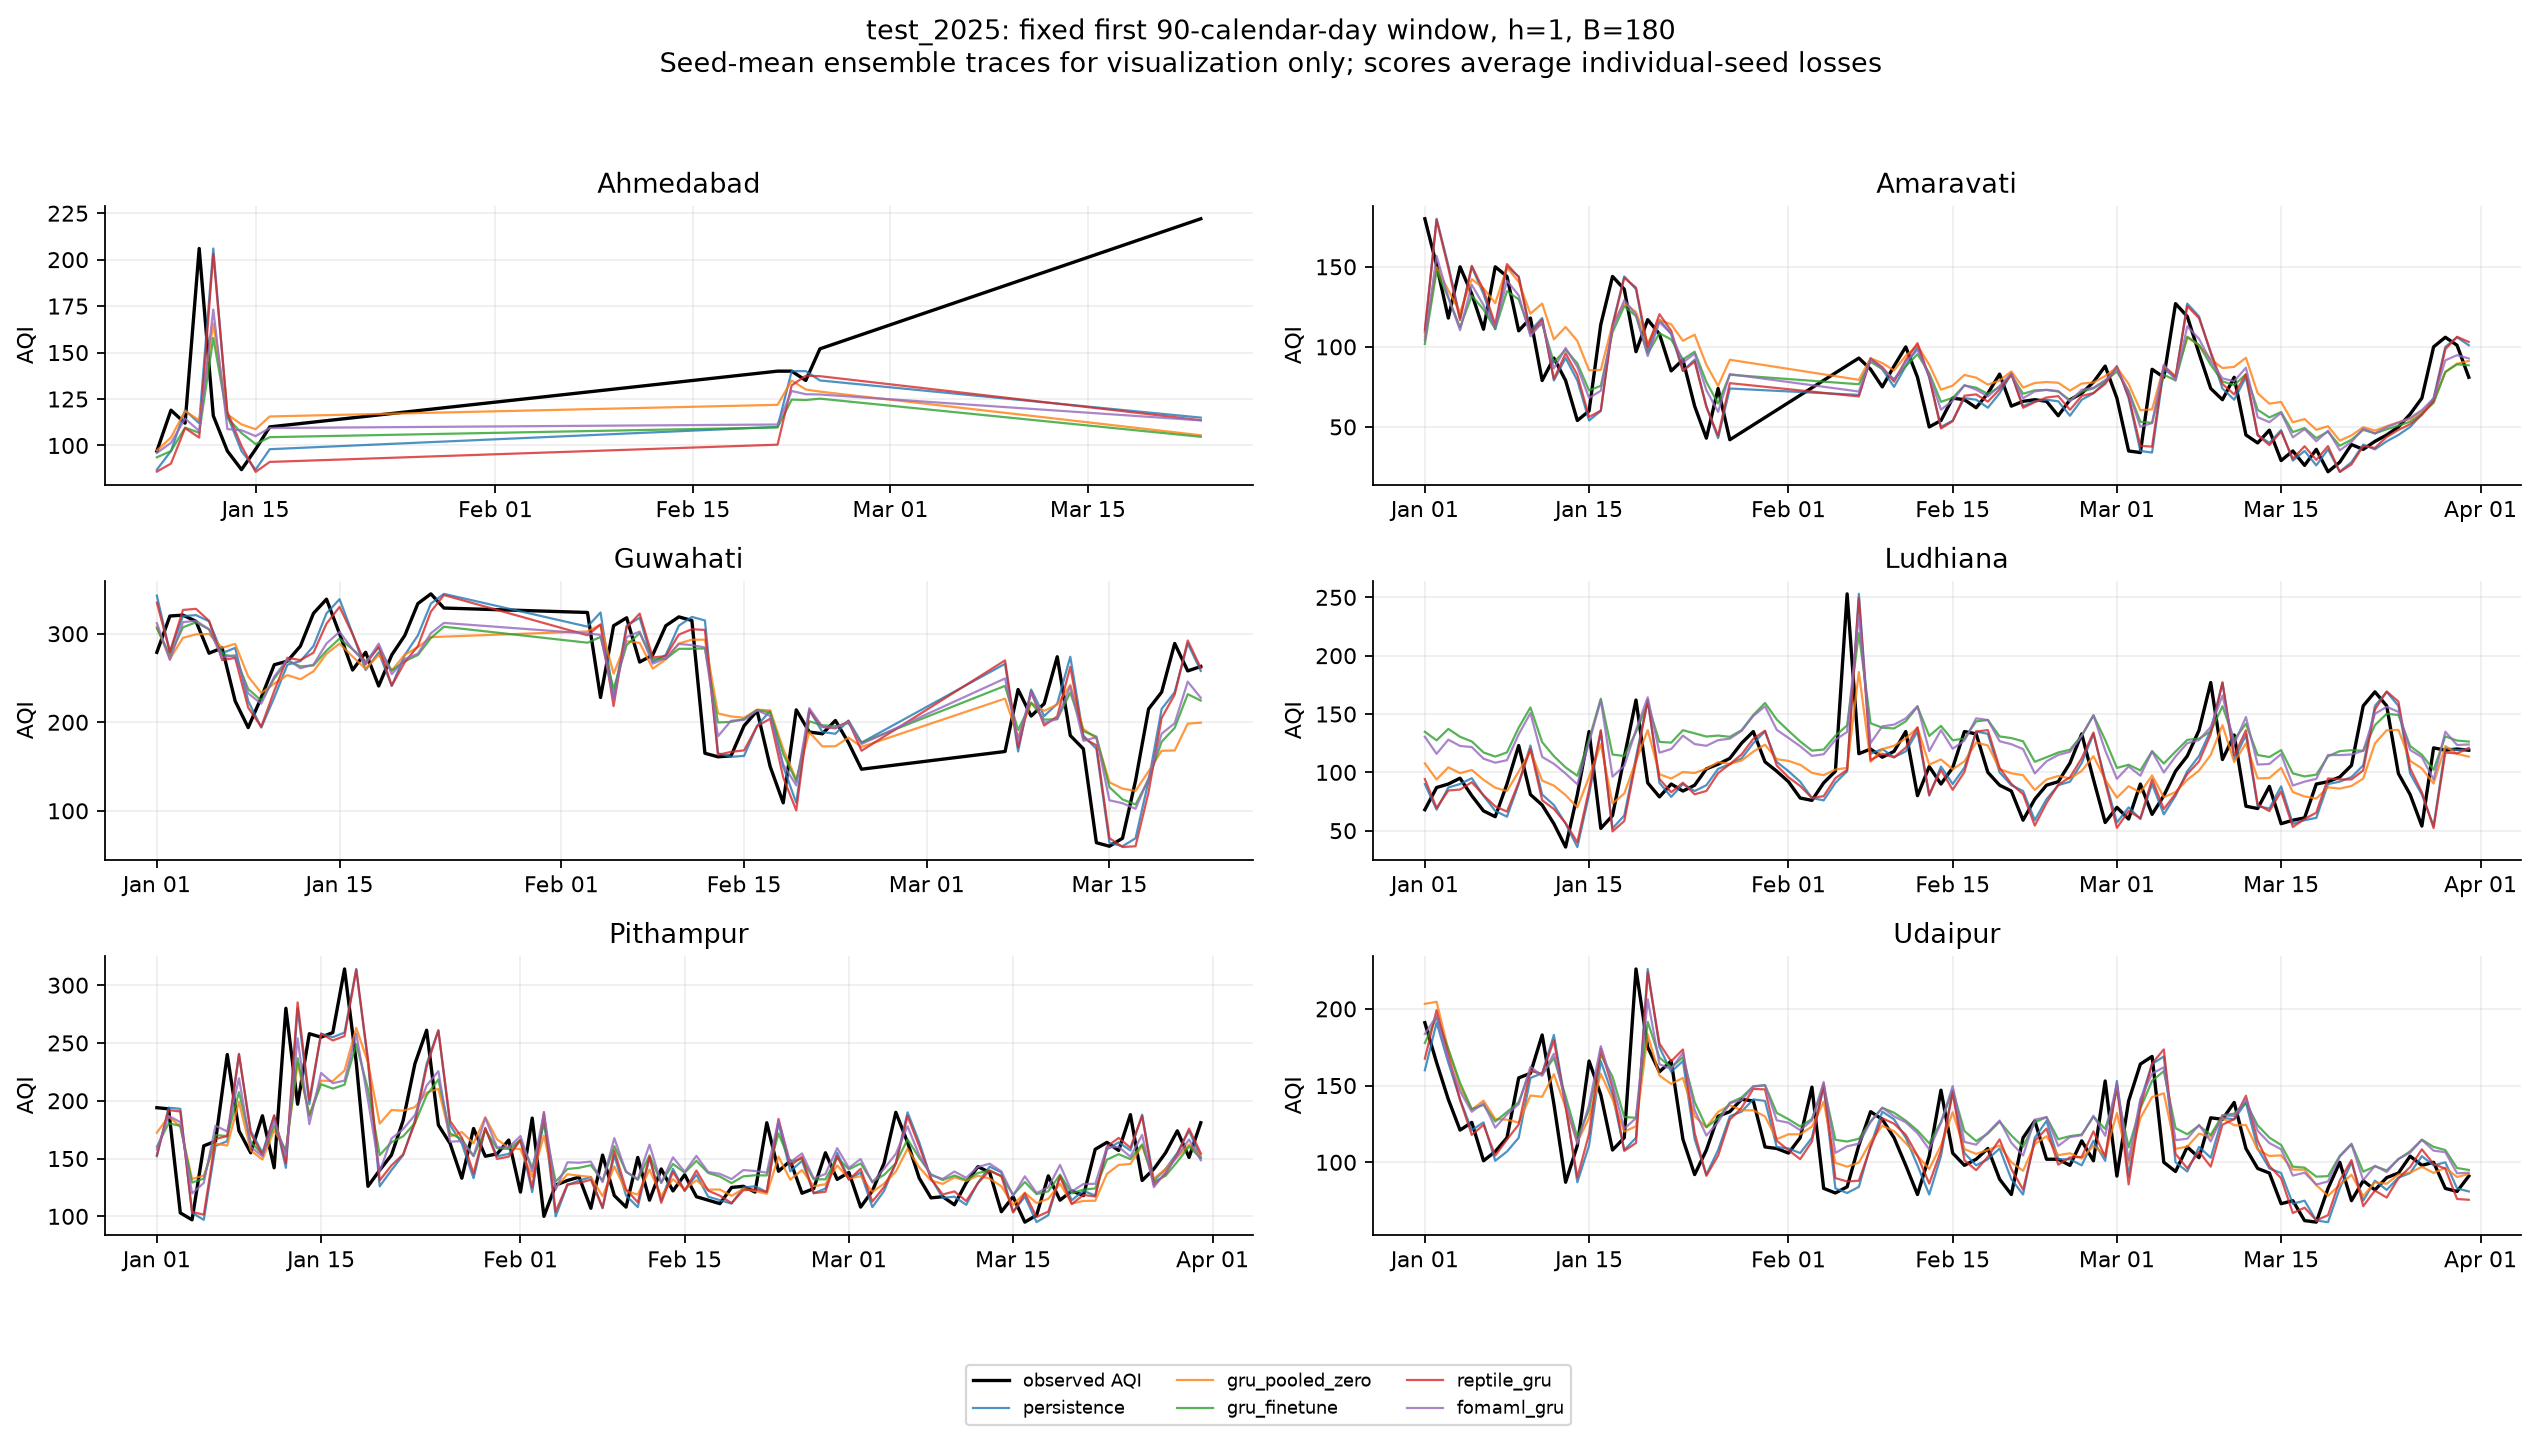

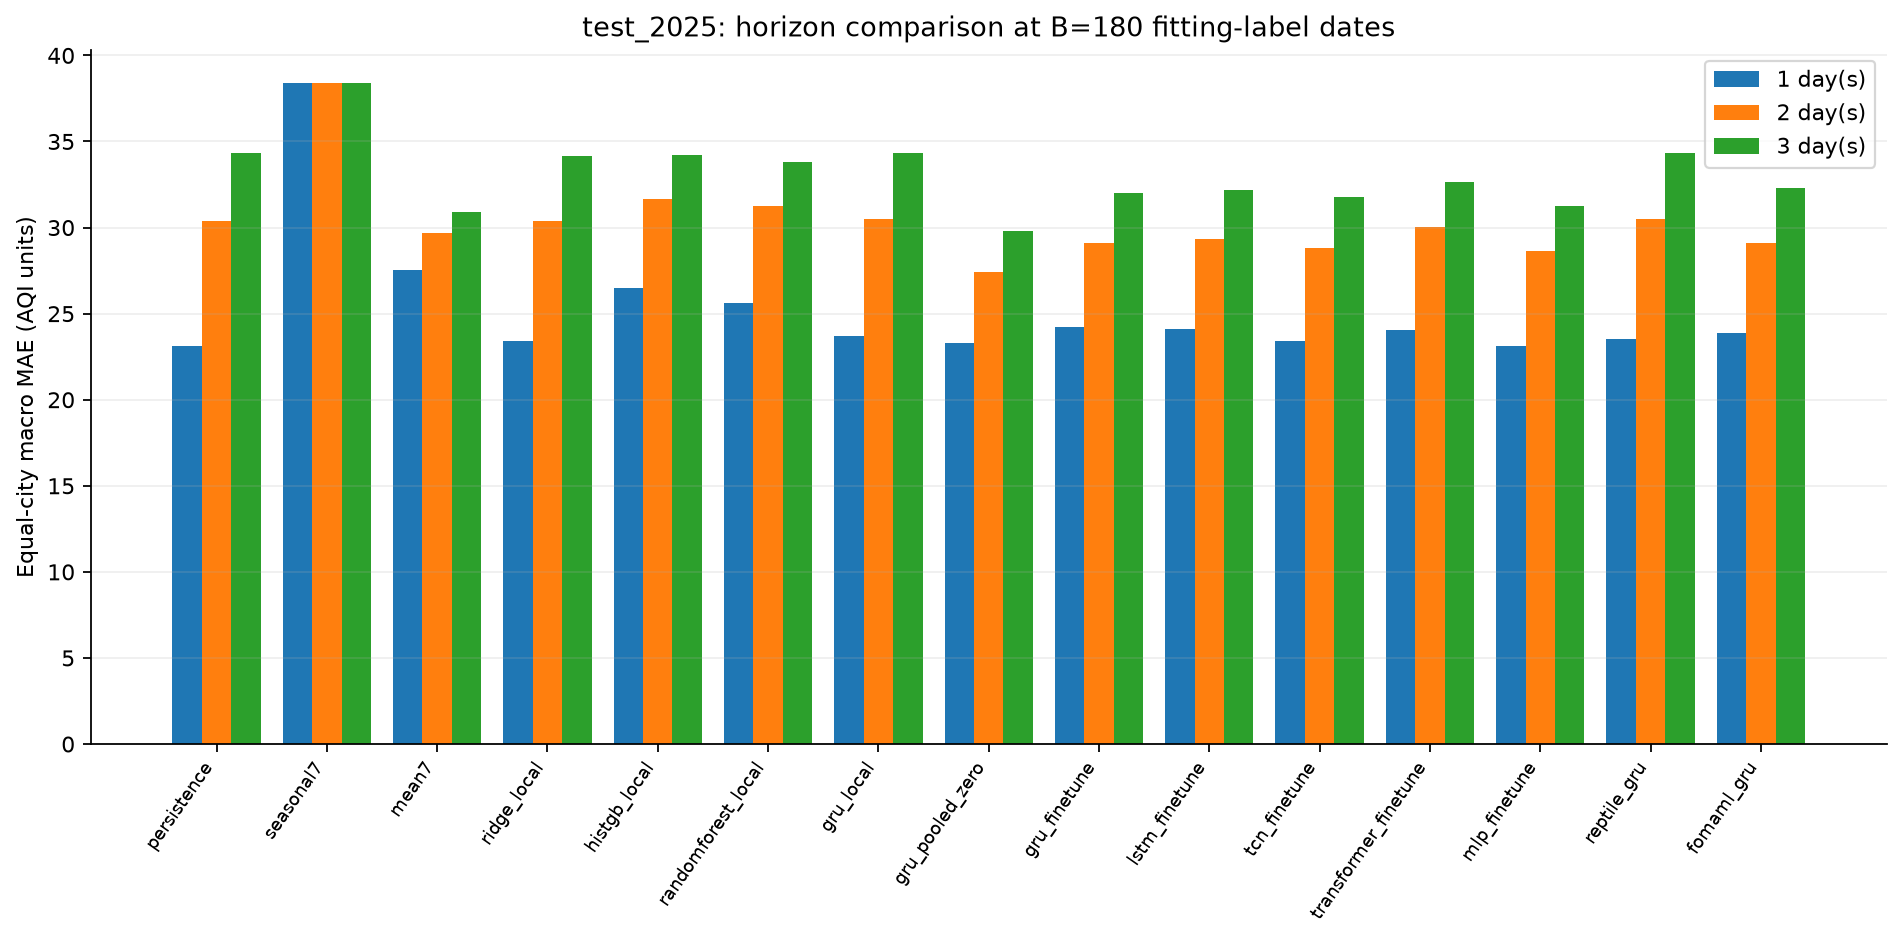

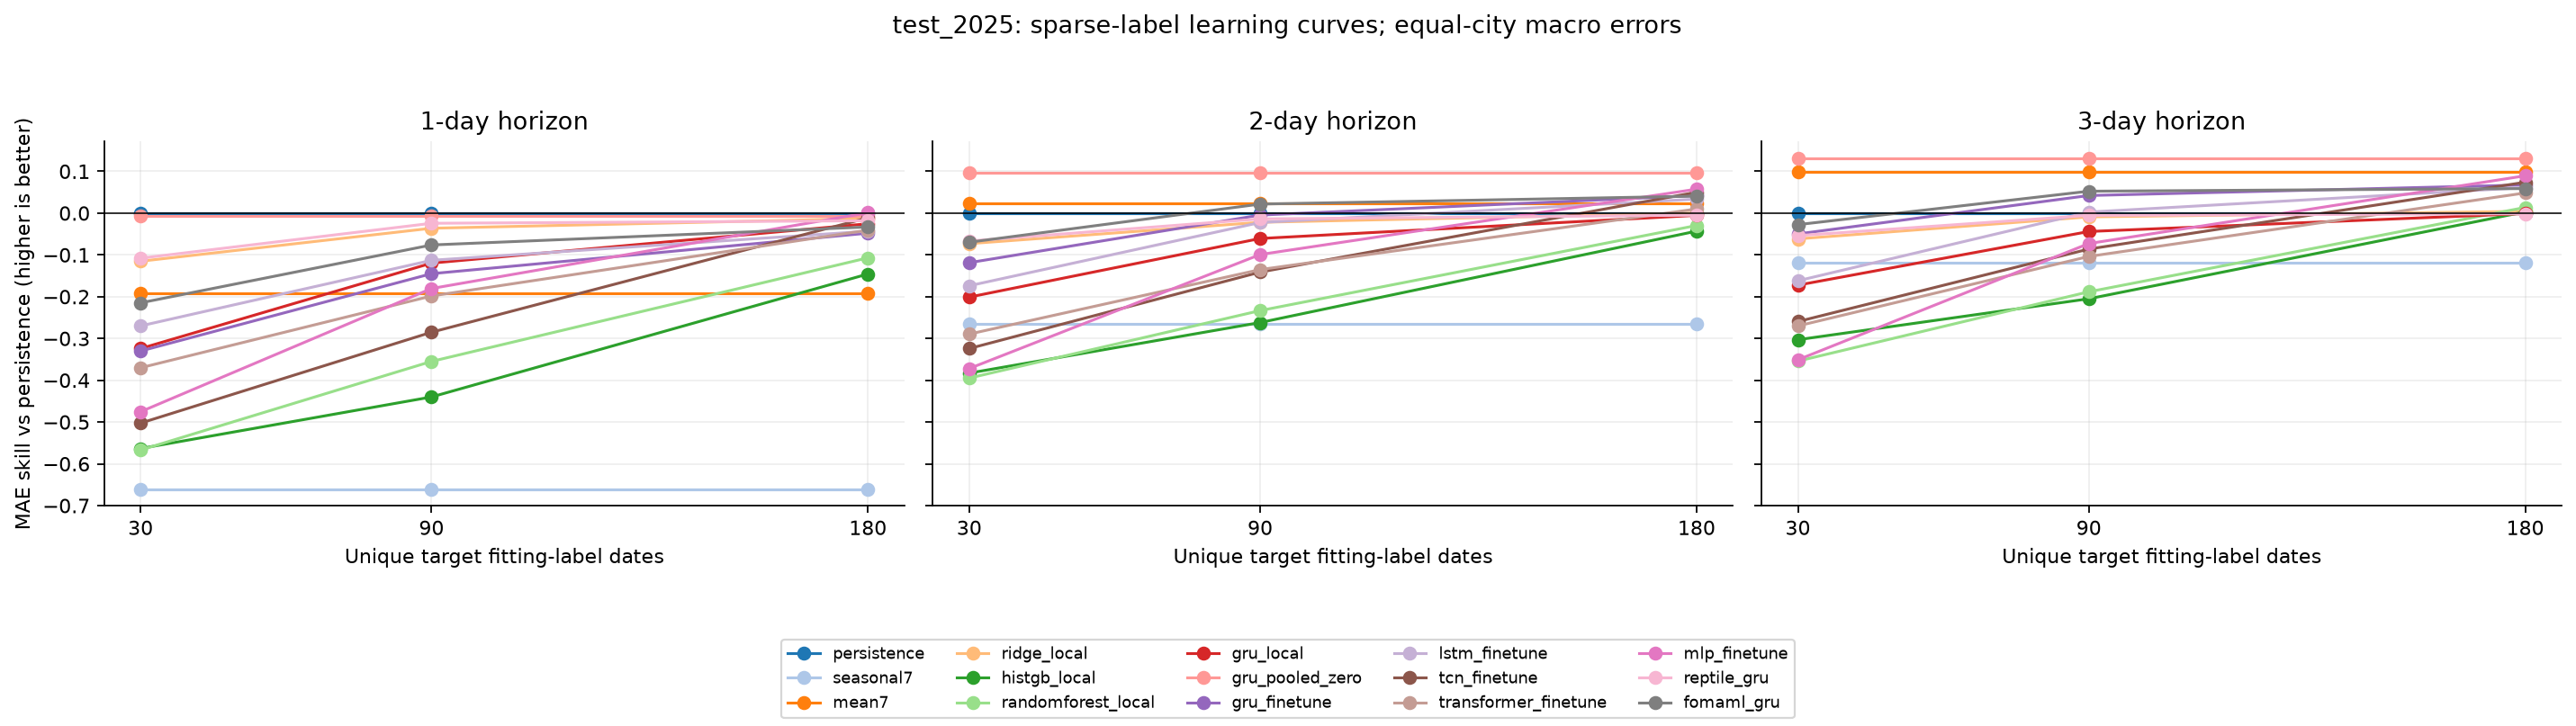

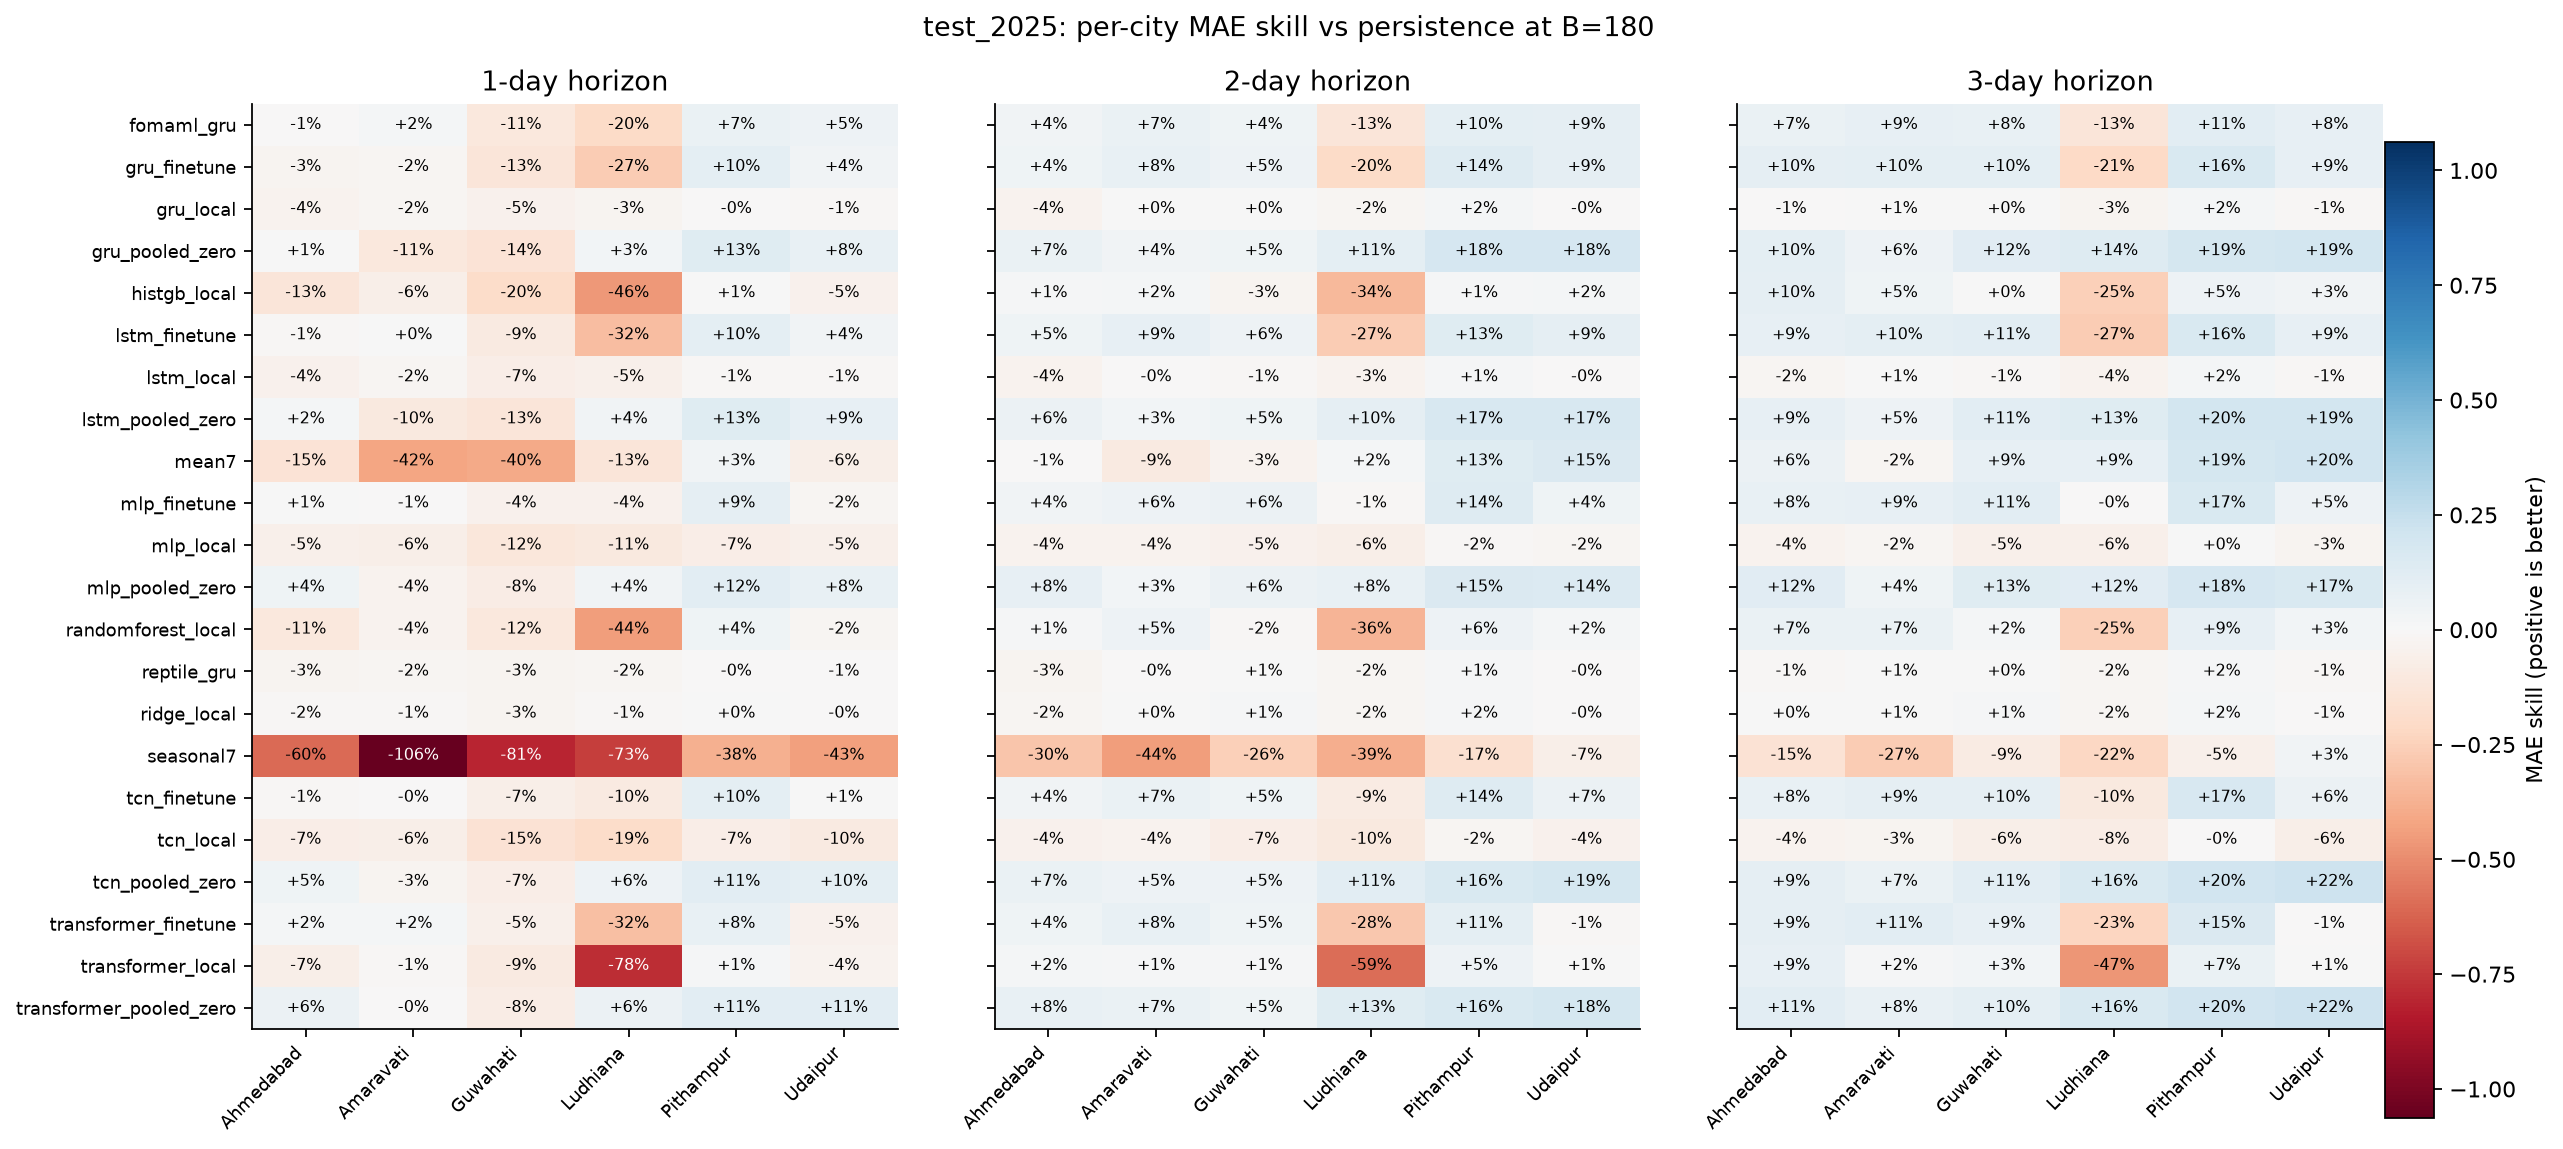

In [8]:
protocol['truth_reference']=pd.concat([f for d in bundle['targets'].values() for k,f in d.items() if k!='adapt'],ignore_index=True).rename(columns={'y':'y_true'})
protocol['eligibility_counts']=pd.read_csv(OUT/'data/eligibility.csv')
protocol['fit_costs']=fit_log
summary=evaluate(predictions, OUT/'evaluation', protocol)
protocol.pop('truth_reference',None)
protocol.pop('eligibility_counts',None)
protocol.pop('fit_costs',None)
display(Markdown((OUT/'evaluation/RESULTS.md').read_text()))
for p in sorted((OUT/'evaluation').glob('*.png')): display(Image(filename=str(p)))

## Questions answered and further work
The generated report quantifies: (1) source coverage and exclusions; (2) whether pretraining beats scratch; (3) whether fine-tuning beats pooled prediction; (4) whether either beats persistence; (5) whether Reptile/FOMAML helps; (6) changes with fitting-label budget, horizon, target city and high-AQI days; and (7) training cost and uncertainty. Improvement over weak scratch alone does not establish useful transfer.

Interpretation is descriptive: observed differences can reflect task diversity, optimization, recency, season or distribution shift; these comparisons cannot prove a pollution mechanism or catastrophic forgetting. No architecture is added after viewing target errors. Further work should use predeclared new-city studies, station-history validation, rolling-origin adaptation with fresh labels, more independent meta-training cities, publication-latency checks, missing-input robustness and higher-pollution calibration. Weather, peer sensors and spatial models require a separate fair-input experiment. A negative result is a complete answer to the registered hypothesis when the comparison is valid.


## Research sources
The design follows published distinctions between global/local models and gradient-based meta-learning. Citations justify methods, not a claim that these methods must improve AQI.
- [MAML, Finn et al. (2017)](https://proceedings.mlr.press/v70/finn17a.html): task support adaptation and held-out query loss.
- [First-Order Meta-Learning Algorithms, Nichol et al. (2018)](https://arxiv.org/abs/1803.02999): Reptile and first-order MAML are distinct algorithms.
- [Global and Local Forecasting Models, Montero-Manso & Hyndman](https://arxiv.org/abs/2008.00444).
- [Forecasting: Principles and Practice — benchmark methods](https://otexts.com/fpp3/toolbox.html).
- [GRU encoder-decoder, Cho et al.](https://arxiv.org/abs/1406.1078).
- [LSTM, Hochreiter & Schmidhuber](https://doi.org/10.1162/neco.1997.9.8.1735), [Transformer, Vaswani et al.](https://arxiv.org/abs/1706.03762), and [TCN, Bai et al.](https://arxiv.org/abs/1803.01271). These are compact adaptations using seven-day histories, not reproductions of the original papers or evidence of long-memory learning.
- [Random forests, Breiman](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf) and [gradient boosting, Friedman](https://doi.org/10.1214/aos/1013203451).
- [Forecast evaluation pitfalls and recommendations](https://link.springer.com/article/10.1007/s10618-022-00894-5).
- [scikit-learn Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
- [Official CPCB archive](https://airquality.cpcb.gov.in/ccr/#/repository/aqi).


In [9]:
import zipfile
with zipfile.ZipFile(str(OUT.parent/'AFML_complete_results.zip'),'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p,p.relative_to(OUT.parent))
print('Complete reproducibility artifacts:',OUT)


Complete reproducibility artifacts: /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_models/afml_final
